# 📊 GSE120376 Bulk RNA-seq Analysis Pipeline

> **📋 Project Metadata**
> - **Author:** Cao Qiang
> - **Contact:** qiangcao2014@gmail.com
> - **Dataset:** [GSE120376](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE120376) — mESC differentiation (LIF vs RA)
> - **Version:** `2.1.0` (Refactored)
> - **Last Modified:** 2026-10-15

---

> **⚖️ Copyright & Compliance Notice**
> - **Copyright:** Copyright © 2020-2026 Cao Qiang.
> - **License:** Licensed under the [MIT License](https://opensource.org/licenses/MIT).
> - **Acknowledgments:** This pipeline utilizes publicly available datasets and open-source packages. Portions of the code architecture were implemented with reference to established community workflows.
> - **AI Disclosure:** Code refactoring, performance optimization, and standardized documentation were enhanced using AI assistance under human supervision. Code and inline results are retained in this notebook for author review.

---

# 1. Experimental Design

**Dataset:** Genome-wide histone modification and accessibility maps of mESCs, in the pluripotent state and after induced differentiation.
- **Source:** Ramisch, A. et al. *CRUP: a comprehensive framework to predict condition-specific regulatory units.* Genome Biol **20**, 227 (2019).
- **Protocol:** polyA RNA-seq, Illumina HiSeq 2500, PE50
- **Reference genome:** mm10 (GENCODE vM23)

| Sample | Organism | Cell | Strain | Treatment | Replicates |
|--------|----------|------|--------|-----------|------------|
| LIF | *M. musculus* | mESC | E14 | Leukemia inhibitory factor (LIF) | rep1~3 |
| RA | *M. musculus* | mESC | E14 | Retinoic acid (RA) | rep1~3 |

> **Design:** Two-group comparison (LIF = pluripotent control, RA = differentiated treatment).  
> LIF: maintains pluripotency; LIF withdrawal + RA addition induces an early differentiation response (4 h pulse). Replicate labels are identifiers, not evidence of paired samples; no batch or pairing covariate is asserted.

**Pipeline Overview**

```
┌─────────────────────────────────────────────────────────────┐
│  1. Configuration ──► 2. Data Import ──► 3. Normalization   │
│                       (FeatureCounts / HTSeq / Salmon /     │
│                        kallisto)                            │
├─────────────────────────────────────────────────────────────┤
│  4. Exploration ──► 5. DEG Analysis ──► 6. Enrichment       │
│  (PCA/MDS/PCoA)    (DESeq2 / edgeR / limma)   (ORA / GSEA)  │
└─────────────────────────────────────────────────────────────┘
```

# 2. Preprocessing

In [1]:
suppressPackageStartupMessages({
    library(tidyverse)
    library(DESeq2)
    library(edgeR)
    library(limma)
})

suppressPackageStartupMessages({
    library(ggrepel)
    library(pheatmap)
    library(patchwork)
    library(RColorBrewer)
})

## 1). Import Data

Run the notebook from top to bottom with the `r452` kernel. The configuration cell
sets the input paths, filtering rule, adjusted P-value cutoff, log2 fold-change
threshold, number of variable genes, and random seed. Positive log2 fold changes
represent higher expression in RA relative to LIF.

The featureCounts matrix supplies the main analysis. The other import routes create
separate example objects. Tables and plots are displayed directly in this notebook.

In [2]:
# Configure paths and shared analysis parameters before importing data.
data_dir <- path.expand(file.path(
    "~/dataset_2/bulk_omics",
    "chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq"
))
gtf_file <- path.expand(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"
)

filter_method <- "filterByExpr" # Alternative: "manual"
p_cutoff <- 0.05
logfc_cutoff <- 1
n_top_genes <- 1000L
analysis_seed <- 123L

set.seed(analysis_seed)
options(timeout = 300)
stopifnot(dir.exists(data_dir), file.exists(gtf_file))

### a). FeatureCounts

Separate gene annotations from sample counts, then align the count columns with
sample metadata. The checks below verify nonnegative integer counts, unique IDs,
and matching row and column order before constructing analysis objects.

In [3]:
# ---- Import FeatureCounts raw count matrix ----
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

# Standardize sample names: strip directory path
colnames(raw_counts) <- colnames(raw_counts) |>
    basename() |>
    sub("[.]Aligned[.]out[.]bam$", "", x = _)

message(
    "Raw counts loaded: ", nrow(raw_counts), " genes x ",
    sum(str_detect(colnames(raw_counts), "mESC")), " samples"
)
head(raw_counts)

Raw counts loaded: 55335 genes x 6 samples



,Geneid,Chr,Start,End,Strand,Length,gene_name,gene_type,mESC_LIF_rep1,mESC_LIF_rep2,mESC_LIF_rep3,mESC_RA_rep1,mESC_RA_rep2,mESC_RA_rep3
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>
1,ENSMUSG00000102693.1,chr1,3073253,3074322,+,1070,4933401J01Rik,TEC,0,0,0,0,0,0
2,ENSMUSG00000064842.1,chr1,3102016,3102125,+,110,Gm26206,snRNA,0,0,0,0,0,0
3,ENSMUSG00000051951.5,chr1;chr1;chr1;chr1;chr1;chr1;chr1,3205901;3206523;3213439;3213609;3214482;3421702;3670552,3207317;3207317;3215632;3216344;3216968;3421901;3671498,-;-;-;-;-;-;-,6094,Xkr4,protein_coding,5,23,17,2,8,5
4,ENSMUSG00000102851.1,chr1,3252757,3253236,+,480,Gm18956,processed_pseudogene,0,0,1,0,0,0
5,ENSMUSG00000103377.1,chr1,3365731,3368549,-,2819,Gm37180,TEC,0,0,1,0,0,0
6,ENSMUSG00000104017.1,chr1,3375556,3377788,-,2233,Gm37363,TEC,0,0,0,0,0,0


In [4]:
# ---- Construct sample metadata (colData) ----
# Parses sample names (Cell_Group_Replicate) into structured metadata.
# Group factor levels: LIF (baseline/control) first, then RA (treatment).
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("mESC"))) |>
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"),
        sep = "_", fill = "right", extra = "drop", remove = FALSE
    ) |>
    mutate(
        sample    = sub("^[^_]+_", "", sample),
        Group     = factor(Group, levels = c("LIF", "RA")),
        Replicate = factor(Replicate)
    ) |>
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Group,Replicate
,<chr>,<fct>,<fct>
LIF_rep1,mESC,LIF,rep1
LIF_rep2,mESC,LIF,rep2
LIF_rep3,mESC,LIF,rep3
RA_rep1,mESC,RA,rep1
RA_rep2,mESC,RA,rep2
RA_rep3,mESC,RA,rep3


In [5]:
# ---- Extract gene annotations (rowData) ----
# Preserves gene_id, symbol, gene_type, and feature length for downstream use.
anno_gene <- raw_counts |>
    dplyr::select(Geneid, symbol = gene_name, type = gene_type, basepairs = Length) |>
    column_to_rownames(var = "Geneid") |>
    DataFrame()

message(
    "Gene annotations: ", nrow(anno_gene), " genes with ",
    n_distinct(anno_gene$type), " biotypes"
)
anno_gene

Gene annotations: 55335 genes with 38 biotypes



DataFrame with 55335 rows and 3 columns
                            symbol                 type basepairs
                       <character>          <character> <integer>
ENSMUSG00000102693.1 4933401J01Rik                  TEC      1070
ENSMUSG00000064842.1       Gm26206                snRNA       110
ENSMUSG00000051951.5          Xkr4       protein_coding      6094
ENSMUSG00000102851.1       Gm18956 processed_pseudogene       480
ENSMUSG00000103377.1       Gm37180                  TEC      2819
...                            ...                  ...       ...
ENSMUSG00000064368.1        mt-Nd6       protein_coding       519
ENSMUSG00000064369.1         mt-Te              Mt_tRNA        69
ENSMUSG00000064370.1       mt-Cytb       protein_coding      1144
ENSMUSG00000064371.1         mt-Tt              Mt_tRNA        67
ENSMUSG00000064372.1         mt-Tp              Mt_tRNA        67

In [6]:
# ---- Prepare clean count matrix ----
# Align column order with coldata for downstream compatibility.
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    dplyr::select(matches("mESC")) |>
    rename_with(~ sub("^[^_]+_", "", .x)) |>
    dplyr::select(all_of(rownames(coldata))) |>
    as.matrix()

head(raw_counts)

,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000102693.1,0,0,0,0,0,0
ENSMUSG00000064842.1,0,0,0,0,0,0
ENSMUSG00000051951.5,5,23,17,2,8,5
ENSMUSG00000102851.1,0,0,1,0,0,0
ENSMUSG00000103377.1,0,0,1,0,0,0
ENSMUSG00000104017.1,0,0,0,0,0,0


In [7]:
# Fail early on silent sample/annotation mismatches; preserve this full matrix.
stopifnot(
    is.numeric(raw_counts), all(is.finite(raw_counts)), all(raw_counts >= 0),
    all(raw_counts == round(raw_counts)), !anyDuplicated(rownames(raw_counts)),
    !anyDuplicated(colnames(raw_counts)), identical(colnames(raw_counts), rownames(coldata)),
    identical(rownames(raw_counts), rownames(anno_gene)), !anyNA(coldata$Group),
    all(table(coldata$Group) == 3L), all(colSums(raw_counts) > 0),
    all(is.finite(anno_gene$basepairs)), all(anno_gene$basepairs > 0)
)

coldata

,Cell,Group,Replicate
,<chr>,<fct>,<fct>
LIF_rep1,mESC,LIF,rep1
LIF_rep2,mESC,LIF,rep2
LIF_rep3,mESC,LIF,rep3
RA_rep1,mESC,RA,rep1
RA_rep2,mESC,RA,rep2
RA_rep3,mESC,RA,rep3


In [8]:
# ---- Build DESeqDataSet (core container for DESeq2) ----
dds_featurecounts_example <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~Group
)

dds_featurecounts_example

class: DESeqDataSet 
dim: 55335 6 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(6): LIF_rep1 LIF_rep2 ... RA_rep2 RA_rep3
colData names(3): Cell Group Replicate

### b). HTSeq-count

Read one HTSeq-count file per sample and construct the independent `dds_htseq`
object to demonstrate this import route. The downstream analysis continues with
`dds` constructed from featureCounts.

In [9]:
# Locate HTSeq-count output files (one per sample)
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

htseq_files |> cat(sep = "\n")

mESC_LIF_rep1.tsv
mESC_LIF_rep2.tsv
mESC_LIF_rep3.tsv
mESC_RA_rep1.tsv
mESC_RA_rep2.tsv
mESC_RA_rep3.tsv


In [10]:
# Build sample table for HTSeq import
coldata_htseq <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName   = htseq_files
) |>
    separate(
        col = sampleName, into = c("Cell", "Group", "Replicate"),
        sep = "_", fill = "right", extra = "drop", remove = FALSE
    ) |>
    mutate(
        sampleName = sub("^[^_]+_", "", sampleName),
        Group      = factor(Group, levels = c("LIF", "RA")),
        Replicate  = factor(Replicate)
    ) |>
    arrange(Group, Replicate) |>
    dplyr::select(sampleName, fileName, Cell, Group, Replicate) |>
    as.data.frame()

coldata_htseq

sampleName,fileName,Cell,Group,Replicate
<chr>,<chr>,<chr>,<fct>,<fct>
LIF_rep1,mESC_LIF_rep1.tsv,mESC,LIF,rep1
LIF_rep2,mESC_LIF_rep2.tsv,mESC,LIF,rep2
LIF_rep3,mESC_LIF_rep3.tsv,mESC,LIF,rep3
RA_rep1,mESC_RA_rep1.tsv,mESC,RA,rep1
RA_rep2,mESC_RA_rep2.tsv,mESC,RA,rep2
RA_rep3,mESC_RA_rep3.tsv,mESC,RA,rep3


In [11]:
# ---- Alternative: DESeqDataSet from HTSeq files ----
dds_htseq <- DESeqDataSetFromHTSeqCount(
    sampleTable = coldata_htseq, design = ~Group,
    directory = file.path(data_dir, "04_counts")
)

dds_htseq

class: DESeqDataSet 
dim: 55335 6 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(6): LIF_rep1 LIF_rep2 ... RA_rep2 RA_rep3
colData names(3): Cell Group Replicate

### c). Salmon

> **Alternative:** If you have Salmon quantification output, use tximport or tximeta.
> - **tximport**: Flexible, works offline, supports multiple tools (Salmon, kallisto, RSEM)
> - **tximeta**: Automatic annotation via online databases (slower, requires network)


#### tximport

In [12]:
# Build transcript-to-gene mapping from GTF
gtf <- rtracklayer::import(gtf_file)

tx2gene <- gtf |>
    subset(
        type == "transcript",
        select = c("transcript_id", "gene_id")
    ) |>
    mcols()

tx2gene

DataFrame with 142351 rows and 2 columns
              transcript_id              gene_id
                <character>          <character>
1      ENSMUST00000193812.1 ENSMUSG00000102693.1
2      ENSMUST00000082908.1 ENSMUSG00000064842.1
3      ENSMUST00000162897.1 ENSMUSG00000051951.5
4      ENSMUST00000159265.1 ENSMUSG00000051951.5
5      ENSMUST00000070533.4 ENSMUSG00000051951.5
...                     ...                  ...
142347 ENSMUST00000082419.1 ENSMUSG00000064368.1
142348 ENSMUST00000082420.1 ENSMUSG00000064369.1
142349 ENSMUST00000082421.1 ENSMUSG00000064370.1
142350 ENSMUST00000082422.1 ENSMUSG00000064371.1
142351 ENSMUST00000082423.1 ENSMUSG00000064372.1

In [13]:
# Locate Salmon quant files
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_dirs <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_dirs, "quant.sf"), salmon_dirs
)

cat(paste(names(salmon_quants), salmon_quants, sep = ": "), sep = "\n")

mESC_LIF_rep1: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_LIF_rep1/quant.sf
mESC_LIF_rep2: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_LIF_rep2/quant.sf
mESC_LIF_rep3: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_LIF_rep3/quant.sf
mESC_RA_rep1: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_RA_rep1/quant.sf
mESC_RA_rep2: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_RA_rep2/quant.sf
mESC_RA_rep3: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_RA_rep3/quant.sf


In [14]:
# Build coldata from Salmon quant files, align with sample order
coldata_salmon <- tibble(sample = names(salmon_quants)) |>
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"),
        sep = "_", fill = "right", extra = "drop", remove = FALSE
    ) |>
    mutate(
        sample    = sub("^[^_]+_", "", sample),
        Group     = factor(Group, levels = c("LIF", "RA")),
        Replicate = factor(Replicate)
    ) |>
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

# Align quant files with coldata order
names(salmon_quants) <- sub("^[^_]+_", "", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata_salmon)]

coldata_salmon

,Cell,Group,Replicate
,<chr>,<fct>,<fct>
LIF_rep1,mESC,LIF,rep1
LIF_rep2,mESC,LIF,rep2
LIF_rep3,mESC,LIF,rep3
RA_rep1,mESC,RA,rep1
RA_rep2,mESC,RA,rep2
RA_rep3,mESC,RA,rep3


In [15]:
# ---- Salmon → tximport (aggregate transcript-level to gene-level counts) ----
txi_salmon <- tximport::tximport(
    salmon_quants,
    type = "salmon", tx2gene = tx2gene,
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE
)

reading in files with read_tsv



1 


2 


3 


4 


5 


6 


summarizing abundance



summarizing counts



summarizing length



In [16]:
# ---- Alternative: DESeqDataSet from tximport ----
dds_salmon <- DESeqDataSetFromTximport(txi_salmon, colData = coldata_salmon, design = ~Group)

dds_salmon

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 6 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(6): LIF_rep1 LIF_rep2 ... RA_rep2 RA_rep3
colData names(3): Cell Group Replicate

#### tximeta

> **Use `tximeta` if internet access is available** for automatic transcriptome annotation.
> `useHub = FALSE` avoids AnnotationHub; a linked transcriptome and its FASTA/GTF are still required.

In [17]:
# List Salmon sample directories
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

salmon_dirs |> cat(sep = "\n")

mESC_LIF_rep1
mESC_LIF_rep2
mESC_LIF_rep3
mESC_RA_rep1
mESC_RA_rep2
mESC_RA_rep3


In [18]:
# Build coldata for tximeta with full file paths
coldata_tximeta <- tibble(
    names = salmon_dirs,
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")
) |>
    separate(
        col = names, into = c("Cell", "Group", "Replicate"),
        sep = "_", fill = "right", extra = "drop", remove = FALSE
    ) |>
    mutate(
        names     = sub("^[^_]+_", "", names),
        Group     = factor(Group, levels = c("LIF", "RA")),
        Replicate = factor(Replicate)
    ) |>
    arrange(Group, Replicate) |>
    dplyr::select(names, files, Cell, Group, Replicate) |>
    as.data.frame()

coldata_tximeta

names,files,Cell,Group,Replicate
<chr>,<chr>,<chr>,<fct>,<fct>
LIF_rep1,/home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_LIF_rep1/quant.sf,mESC,LIF,rep1
LIF_rep2,/home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_LIF_rep2/quant.sf,mESC,LIF,rep2
LIF_rep3,/home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_LIF_rep3/quant.sf,mESC,LIF,rep3
RA_rep1,/home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_RA_rep1/quant.sf,mESC,RA,rep1
RA_rep2,/home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_RA_rep2/quant.sf,mESC,RA,rep2
RA_rep3,/home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_salmon/mESC_RA_rep3/quant.sf,mESC,RA,rep3


In [19]:
# tximeta uses a temporary cache for the current R session.
tximeta::setTximetaBFC(file.path(tempdir(), "tximeta"))
tximeta::makeLinkedTxome(
    indexDir = path.expand("~/reference/Mus_musculus/mm10/index/salmon_index"),
    source = "GENCODE", organism = "Mus musculus", release = "M23", genome = "GRCm38",
    fasta = path.expand("~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa"),
    gtf = gtf_file, write = FALSE
)

for group use, set the permissions of this directory to allow group write (g+w)



reading digest from indexDir: /home/fugui/reference/Mus_musculus/mm10/index/salmon_index



NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE



saving linkedTxome in bfc (first time)



In [20]:
# Import with tximeta (useHub = FALSE when offline)
se <- tximeta::tximeta(coldata_tximeta, useHub = FALSE, skipSeqinfo = TRUE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files



reading in files with read_tsv



1 


2 


3 


4 


... (20 outputs left out)

assignRanges='range': gene ranges assigned by total range of isoforms
  see details at: ?summarizeToGene,SummarizedExperiment-method



summarizing abundance



summarizing counts



summarizing length



In [21]:
# ---- Alternative: DESeqDataSet from tximeta SE ----
dds_tximeta <- DESeqDataSet(gse, design = ~Group)

dds_tximeta

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 6 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(6): LIF_rep1 LIF_rep2 ... RA_rep2 RA_rep3
colData names(4): names Cell Group Replicate

### d). kallisto

> **Alternative:** Use with tximport (same workflow as Salmon but for kallisto `.h5` files).


#### tximport

In [22]:
# Locate kallisto abundance files
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_dirs <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_dirs, "abundance.h5"), kallisto_dirs
)

cat(paste(names(kallisto_quants), kallisto_quants, sep = ": "), sep = "\n")

mESC_LIF_rep1: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_kallisto/mESC_LIF_rep1/abundance.h5
mESC_LIF_rep2: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_kallisto/mESC_LIF_rep2/abundance.h5
mESC_LIF_rep3: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_kallisto/mESC_LIF_rep3/abundance.h5
mESC_RA_rep1: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_kallisto/mESC_RA_rep1/abundance.h5
mESC_RA_rep2: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_kallisto/mESC_RA_rep2/abundance.h5
mESC_RA_rep3: /home/fugui/dataset_2/bulk_omics/chipseq_Mm_mESC_Histone_GSE120376/02_output_rnaseq/05_kallisto/mESC_RA_rep3/abundance.h5


In [23]:
# Build coldata and align kallisto quant files
coldata_kallisto <- tibble(sample = names(kallisto_quants)) |>
    separate(
        col = sample, into = c("Cell", "Group", "Replicate"),
        sep = "_", fill = "right", extra = "drop", remove = FALSE
    ) |>
    mutate(
        sample    = sub("^[^_]+_", "", sample),
        Group     = factor(Group, levels = c("LIF", "RA")),
        Replicate = factor(Replicate)
    ) |>
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

names(kallisto_quants) <- sub("^[^_]+_", "", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata_kallisto)]

coldata_kallisto

,Cell,Group,Replicate
,<chr>,<fct>,<fct>
LIF_rep1,mESC,LIF,rep1
LIF_rep2,mESC,LIF,rep2
LIF_rep3,mESC,LIF,rep3
RA_rep1,mESC,RA,rep1
RA_rep2,mESC,RA,rep2
RA_rep3,mESC,RA,rep3


In [24]:
# ---- kallisto → tximport ----
txi_kallisto <- tximport::tximport(
    kallisto_quants,
    type = "kallisto", tx2gene = tx2gene,
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE
)

1 


2 


3 


4 


5 


6 


summarizing abundance



summarizing counts



summarizing length



In [25]:
# ---- Alternative: DESeqDataSet from kallisto tximport ----
dds_kallisto <- DESeqDataSetFromTximport(txi_kallisto,
    colData = coldata_kallisto,
    design = ~Group
)

dds_kallisto

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 6 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(6): LIF_rep1 LIF_rep2 ... RA_rep2 RA_rep3
colData names(3): Cell Group Replicate

## 2). Object Construction

Create three containers from the same featureCounts matrix and sample metadata:

- `SummarizedExperiment` (`eSet`): counts, gene annotations, and sample information
  for exploration.
- `DESeqDataSet` (`dds`): input to DESeq2 normalization and model fitting.
- `DGEList` (`dgel`): input to edgeR and the limma workflows used here.

Apply the selected gene filter consistently to all three containers. Keep
`raw_counts` intact for the full-matrix normalization calculations.

### a). SummarizedExperiment

In [26]:
# ---- SummarizedExperiment (base container) ----
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts),
    rowData = anno_gene, colData = coldata
)

message("SummarizedExperiment: ", nrow(eSet), " genes x ", ncol(eSet), " samples")
eSet

SummarizedExperiment: 55335 genes x 6 samples



class: SummarizedExperiment 
dim: 55335 6 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(6): LIF_rep1 LIF_rep2 ... RA_rep2 RA_rep3
colData names(3): Cell Group Replicate

### b). DESeqDataSet

In [27]:
# ---- DESeqDataSet (for DESeq2) ----
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~Group
)

message("DESeqDataSet: ", nrow(dds), " genes x ", ncol(dds), " samples")
dds

DESeqDataSet: 55335 genes x 6 samples



class: DESeqDataSet 
dim: 55335 6 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(6): LIF_rep1 LIF_rep2 ... RA_rep2 RA_rep3
colData names(3): Cell Group Replicate

### c). DGEList

In [28]:
# ---- DGEList (for edgeR) ----
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene,
    samples = coldata, group = coldata$Group
)

message("DGEList: ", nrow(dgel), " genes x ", ncol(dgel), " samples")
lapply(dgel, head)

DGEList: 55335 genes x 6 samples



,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000102693.1,0,0,0,0,0,0
ENSMUSG00000064842.1,0,0,0,0,0,0
ENSMUSG00000051951.5,5,23,17,2,8,5
ENSMUSG00000102851.1,0,0,1,0,0,0
ENSMUSG00000103377.1,0,0,1,0,0,0
ENSMUSG00000104017.1,0,0,0,0,0,0
,group,lib.size,norm.factors,Cell,Group,Replicate
,<fct>,<dbl>,<dbl>,<chr>,<fct>,<fct>
LIF_rep1,LIF,37976626,1,mESC,LIF,rep1
LIF_rep2,LIF,35097408,1,mESC,LIF,rep2


## 3). Low-Count Filtering

> Removes lowly-expressed genes to reduce noise, improve statistical power, and speed computation.
> Two methods provided: (1) Manual threshold, (2) edgeR `filterByExpr()` (recommended).

The manual rule retains genes with at least 10 counts in at least three samples.
The comparison table shows how this rule overlaps with `filterByExpr()`. Only the
rule selected by `filter_method` is applied; the two filters are not applied in
sequence. TMM factors are then estimated on the retained count matrix.

In [29]:
# Manual rule remains an explicit alternative; do not filter objects here.
keep_manual <- rowSums(raw_counts >= 10) >= 3
table(keep_manual)

keep_manual
FALSE  TRUE 
38671 16664 

In [30]:
keep_edgeR <- edgeR::filterByExpr(dgel, group = coldata$Group)
filter_comparison <- table(manual = keep_manual, filterByExpr = keep_edgeR)
filter_comparison

       filterByExpr
manual  FALSE  TRUE
  FALSE 38671     0
  TRUE    134 16530

In [31]:
# Apply one selected gene mask to every main analysis container.
# Preserve raw_counts for normalization denominators based on the full matrix.
stopifnot(filter_method %in% c("manual", "filterByExpr"))
keep <- if (filter_method == "manual") keep_manual else keep_edgeR
stopifnot(sum(keep) >= n_top_genes)
eSet <- eSet[keep, ]
dds <- dds[keep, ]
dgel <- dgel[keep, , keep.lib.sizes = FALSE]
dgel <- edgeR::normLibSizes(dgel)
stopifnot(identical(rownames(dds), rownames(dgel)), identical(rownames(dds), rownames(eSet)))

table(retained = keep)

retained
FALSE  TRUE 
38805 16530 

# 3. Normalization

| Method | Interpretation | Use |
|---|---|---|
| CPM / FPKM / TPM | Depth and/or gene-length scaling; composition bias can remain | Descriptive expression comparisons |
| DESeq2 size factors / edgeR TMM | Between-sample composition scaling | Count-based modeling |
| voom | LogCPM plus observation precision weights | limma modeling |
| VST / rlog | Size-factor-aware variance stabilization | QC, distances, heatmaps |

CPM/FPKM/TPM below use the full valid gene set for their denominators, then subset for plotting. Gene-level TPM based on union-exon lengths is an approximation and is not identical to Salmon transcript TPM aggregation. None of these normalized display matrices replaces raw counts in DESeq2/edgeR.

## Simple

> Transformation for exploration and visualization

### 1). CPM

> Counts Per Million (CPM) adjusts raw counts for sequencing depth by scaling each gene's count to the total library size, then multiplying by $10^6$.
> - **Pros:**
>   - Simple, intuitive, widely used for exploratory visualization (heatmaps, clustering).
> - **Cons:**
>   - Does **not** account for gene length → unsuitable for within-sample gene-gene comparison.
>   - **RNA composition bias:** If a small number of highly-expressed genes are differentially expressed between conditions, they inflate the total counts denominator, suppressing CPM values of all other genes. This can introduce false positives in downstream analyses.

<span style="font-size: 150%">

$$ \text{CPM}_i = \frac{\text{Count}_i}{\sum_{i=1}^{n}\text{Count}_i} \times 10^6 $$
</span>

In [32]:
# Base R implementation, using full assigned-fragment library sizes.
cpm_full <- sweep(raw_counts, 2, colSums(raw_counts), FUN = "/") * 1e6
cpm_mat <- cpm_full[rownames(eSet), , drop = FALSE]
head(cpm_mat)

,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000103922.1,8.6895555,9.231451,8.636132,8.7043201,9.1053825,8.132540
ENSMUSG00000033845.13,193.2504483,192.948721,187.362937,186.5420779,178.2095938,178.075615
ENSMUSG00000102275.1,0.9479515,1.025717,1.480480,1.0550691,0.9819530,1.620506
ENSMUSG00000025903.14,159.2558539,157.618477,153.147405,155.3296171,142.7105045,126.879626
ENSMUSG00000033813.15,129.1320614,129.924124,127.293842,132.3232493,127.8919409,117.996852
ENSMUSG00000002459.17,0.2106559,0.427382,0.466077,0.3223822,0.7736599,1.140356


### 2). FPKM / RPKM

> Fragments Per Kilobase of exon per Million mapped fragments (FPKM) and its single-end counterpart RPKM normalize by **both** gene length and library size, enabling within-sample comparison of expression across genes.
> - **Pros:**
>   - Enables comparison of expression levels between genes in the same sample (e.g., identify highly expressed genes).
> - **Cons:**
>   - The **sum of FPKM values is not constant across samples**, making cross-sample comparisons unreliable (TPM addresses this).
>   - Subject to the same **RNA composition bias** as CPM.
>   - **Not recommended for formal differential expression testing** because it does not model the mean-variance relationship of count data.

<span style="font-size: 150%">

$$ \text{FPKM}_i = \frac{\text{Count}_i}{\frac{\text{Length}_i}{10^3} \times \frac{\sum\text{Count}}{10^6}} = \frac{\text{Count}_i}{\text{Length}_i \times \sum\text{Count}} \times 10^9 $$
</span>


In [33]:
fpkm_full <- raw_counts |>
    sweep(1, anno_gene$basepairs / 1e3, FUN = "/") |>
    sweep(2, colSums(raw_counts) / 1e6, FUN = "/")
fpkm_mat <- fpkm_full[rownames(eSet), , drop = FALSE]
head(fpkm_mat)

,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000103922.1,8.12867682,8.6355949,8.0787015,8.14248835,8.5176637,7.6076145
ENSMUSG00000033845.13,22.77017183,22.7346202,22.0764625,21.97974288,20.9979491,20.9821627
ENSMUSG00000102275.1,0.82430566,0.8919276,1.2873737,0.91745139,0.8538722,1.4091357
ENSMUSG00000025903.14,22.28913280,22.0599688,21.4342065,21.73962450,19.9734786,17.7578203
ENSMUSG00000033813.15,42.80147875,43.0640120,42.1921917,43.85921420,42.3904345,39.1106568
ENSMUSG00000002459.17,0.04969471,0.1008214,0.1099497,0.07605148,0.1825100,0.2690154


### 3). TPM

> Transcripts Per Kilobase Million (TPM) is an improvement over RPKM/FPKM. TPM first normalizes for gene length, then for sequencing depth, making the sum of all TPMs in each sample identical. This provides relative abundance; equal sums alone do not ensure unbiased between-sample comparisons.
> - Pros:
>    - A fixed-sum relative expression scale, still sensitive to composition differences.
>    - Accounts for the total sum of normalized expression levels, allowing for a more balanced comparison.
> - Cons:
>    - Can be affected by highly expressed genes and depends on accurate estimates of gene lengths and accurate read mapping.
>    - Not an appropriate substitute for count input in the models used here.

<span style="font-size: 150%">

$$ \text{TPM} = \frac{\frac{Count_i} {Length_i}}{\sum_{i=1}^{n}(\frac{Count_i}{Length_i})} \times 10^6 = \frac{FPKM}{\sum_{i=1}^{n}(FPKM)} \times 10^6 $$
</span>

In [34]:
tpm_full <- raw_counts |>
    sweep(1, anno_gene$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
stopifnot(all(abs(colSums(tpm_full) - 1e6) < 1e-6))
tpm <- tpm_full[rownames(eSet), , drop = FALSE]
head(tpm)

,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000103922.1,29.7662698,31.3676764,29.458856,29.6641567,30.8674045,27.3601282
ENSMUSG00000033845.13,83.3817228,82.5805538,80.501467,80.0750961,76.0950668,75.4605354
ENSMUSG00000102275.1,3.0185115,3.2398112,4.694388,3.3423962,3.0943718,5.0678349
ENSMUSG00000025903.14,81.6202138,80.1299703,78.159491,79.2003132,72.3824590,63.8644664
ENSMUSG00000033813.15,156.7340406,156.4244282,153.853151,159.7848897,153.6199051,140.6580984
ENSMUSG00000002459.17,0.1819763,0.3662207,0.400930,0.2770656,0.6614032,0.9674905


## Statistical

> Statistical normalization for differential expression analysis

### 1). DESeq2

> DESeq, a normalization method designed for differential gene expression analysis, uses a more robust negative binomial distribution model. It estimates size factors from the geometric mean of each gene's counts across all samples, effectively scaling for library size and accounting for differences in gene expression variability.
> - Pros:
>    - Robust to outliers and can handle large variations in expression levels.
>    - Ideal for datasets with substantial differences in library sizes or where some genes are only expressed in a subset of samples.
> - Cons:
>    - Assumption that **most genes are not differentially expressed** may not hold in certain experimental conditions.
>    - Relies on the assumption of having a sufficient number of samples to accurately estimate dispersion.

**DESeq2-normalized counts: Median of ratios method**

> 1. Calculate the geometric mean of gene 𝑖:

<span style="font-size: 150%">

$$ g_i = \left(\prod_{j=1}^{n} \mathrm{Count}_{ij}\right)^{1/n} = \exp\left(\frac{1}{n}\sum_{j=1}^{n}\ln(\mathrm{Count}_{ij})\right) $$
</span>

> 2. Calculate the gene ratios:

<span style="font-size: 150%">

$$ r_{ij} = \frac{\mathrm{counts}_{ij}}{g_i} \qquad (g_i>0) $$
</span>

> 3. Calculate the size factor for sample 𝑗 (take the median of all gene ratios):

<span style="font-size: 150%">

$$ s_j = \operatorname{median}_{i}\; r_{ij} \qquad (g_i>0) $$
</span>

> 4. Normalize the counts using the size factor:

<span style="font-size: 150%">

$$ \mathrm{counts}^{(\mathrm{norm})}_{ij} = \frac{\mathrm{counts}_{ij}}{s_j} $$
</span>

> - https://hbctraining.github.io/DGE_workshop/lessons/02_DGE_count_normalization.html

In [35]:
# ---- DESeq2 normalization (Median-of-Ratios) ----
# Size factors = median(gene_count / geometric_mean_across_samples).
# Assumption: most genes are NOT differentially expressed.
dds <- estimateSizeFactors(dds)
norm_count <- counts(dds, normalized = TRUE)
norm_count |> head()

# DESeq2 FPKM (with robust size factor estimation)
deseq2_fpkm <- DESeq2::fpkm(dds, robust = TRUE)
deseq2_fpkm |> head()

,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000103922.1,316.57147,318.21389,293.92605,315.07231,314.29622,278.73846
ENSMUSG00000033845.13,7040.35757,6651.06310,6376.79565,6752.30727,6151.37267,6103.44663
ENSMUSG00000102275.1,34.53507,35.35710,50.38732,38.19058,33.89469,55.54198
ENSMUSG00000025903.14,5801.89161,5433.20748,5212.28863,5622.50252,4926.02827,4348.73144
ENSMUSG00000033813.15,4704.44386,4478.56582,4332.37668,4789.73564,4414.52659,4044.27909
ENSMUSG00000002459.17,7.67446,14.73212,15.86268,11.66934,26.70491,39.08510


,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000103922.1,8.45340357,8.49726109,7.8487033,8.41337162,8.3926476,7.4431494
ENSMUSG00000033845.13,23.67980129,22.37043377,21.4479524,22.71096218,20.6897563,20.5285601
ENSMUSG00000102275.1,0.85723526,0.87763982,1.2507226,0.94797305,0.8413397,1.3786724
ENSMUSG00000025903.14,23.17954558,21.70658965,20.8239812,22.46285557,19.6803223,17.3739231
ENSMUSG00000033813.15,44.51132471,42.37416862,40.9909929,45.31831698,41.7682583,38.2651436
ENSMUSG00000002459.17,0.05167993,0.09920636,0.1068195,0.07858155,0.1798313,0.2631997


### 2). edgeR TMM

TMM estimates composition factors from trimmed, weighted log2 ratios to a reference library.

$$M_i=\log_2\frac{y_{ij}/N_j}{y_{ir}/N_r},\qquad
f_j=2^{\sum_{i\in S}w_iM_i/\sum_{i\in S}w_i}.$$

The asymptotic variance includes library-size terms:
$v_i=(N_j-y_{ij})/(N_jy_{ij})+(N_r-y_{ir})/(N_ry_{ir})$, with $w_i=1/v_i$.
Default trimming removes 30% from **each tail** of M and 5% from each tail of A.
Factors are centered to geometric mean 1; effective library size is $N_j f_j$.
This is composition scaling, not gene-length normalization; strong global shifts require external controls for absolute-RNA claims.

In [36]:
# edgeR TMM-normalized CPM
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)
norm_cpm |> head()

# edgeR TMM-normalized RPKM
edger_rpkm <- rpkm(dgel, gene.length = "basepairs", normalized.lib.sizes = TRUE)
edger_rpkm |> head()

,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000103922.1,8.9200056,9.081914,8.4392712,9.0155933,9.0506537,8.044891
ENSMUSG00000033845.13,198.3755181,189.823223,183.0919988,193.2129678,177.1384478,176.156398
ENSMUSG00000102275.1,0.9730915,1.009102,1.4467322,1.0927992,0.9760509,1.603041
ENSMUSG00000025903.14,163.4793751,155.065279,149.6564099,160.8843251,141.8527293,125.512176
ENSMUSG00000033813.15,132.5566890,127.819536,124.3921789,137.0552317,127.1232341,116.725136
ENSMUSG00000002459.17,0.2162426,0.420459,0.4554527,0.3339109,0.7690098,1.128066


,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000103922.1,8.34425218,8.49571038,7.8945475,8.43367008,8.4664675,7.525623
ENSMUSG00000033845.13,23.37404479,22.36635126,21.5732295,22.76575560,20.8717389,20.756027
ENSMUSG00000102275.1,0.84616654,0.87747965,1.2580280,0.95026016,0.8487399,1.393949
ENSMUSG00000025903.14,22.88024844,21.70262829,20.9456137,22.51705040,19.8534261,17.566435
ENSMUSG00000033813.15,43.93658901,42.36643552,41.2304206,45.42765385,42.1356427,38.689140
ENSMUSG00000002459.17,0.05101263,0.09918825,0.1074434,0.07877114,0.1814130,0.266116


### 3). limma-voom

> **voom** (Mean-Variance Modeling at the Observational Level) converts raw counts to **log2-CPM** with associated **precision weights** that account for the mean-variance relationship typical of count data. This enables the use of limma's linear modeling framework — originally designed for microarrays — on RNA-seq data.
>
> **Key steps:**
> 1. Compute log2-CPM from normalized library sizes.
> 2. Fit a LOWESS curve to estimate the mean-variance trend.
> 3. Assign each observation a precision weight (inverse variance) based on its fitted variance.
> 4. Feed log2-CPM values + precision weights into `lmFit()` + `eBayes()`.
>
> **Note:** voom defaults to no additional between-array normalization (`normalize.method="none"`). Quantile normalization is a microarray-era technique that forces identical distributions across samples; voom instead relies on precision weights to handle heteroscedasticity.
>
> - **Pros:** Handles varying library sizes well; integrates seamlessly with limma's mature linear model framework; supports complex designs with blocking factors and interaction terms.
> - **Cons:** The log2-CPM transformation with precision weights is an approximation to a full count model; performance depends on design and mean-variance estimation; method choice is not determined by sample size alone.

In [37]:
# ---- limma voom ----
# Transforms counts → log2-CPM with precision weights modeling the mean-variance trend.
design_voom <- model.matrix(~group, data = dgel$samples)
norm_v <- voom(dgel, design_voom, plot = FALSE)

head(norm_v$E)

,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000103922.1,3.15922882,3.18522106,3.0794066,3.1748491,3.1803774,3.0107322
ENSMUSG00000033845.13,7.63218843,7.56861917,7.5165304,7.5941614,7.4688540,7.4608346
ENSMUSG00000102275.1,-0.01945308,0.03297095,0.5460947,0.1479278,-0.0132767,0.6941081
ENSMUSG00000025903.14,7.35308405,7.27686223,7.2256394,7.3300160,7.1484005,6.9718541
ENSMUSG00000033813.15,7.05061271,6.99812269,6.9589073,7.0987733,6.9902517,6.8671549
ENSMUSG00000002459.17,-2.12181480,-1.20265729,-1.0928066,-1.5183348,-0.3514454,0.1927103


## Variance Stabilization

> Transformation for visualization

### 1). rlog

> Regularized-logarithm transformation: the rlog tends to work well on small datasets (n < 30)

In [38]:
# ---- rlog (Regularized Log Transformation) ----
# Variance-stabilizing; best for n < 30. Shrinkage-based, slower; useful for comparing
# transformation behavior in small datasets.
rld <- rlog(dds, blind = FALSE)
assay(rld) |> head()

,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000103922.1,8.283761,8.287773,8.225882,8.279799,8.277947,8.186003
ENSMUSG00000033845.13,12.756806,12.692405,12.644836,12.709471,12.604321,12.595530
ENSMUSG00000102275.1,5.320734,5.326168,5.417682,5.344246,5.317390,5.445684
ENSMUSG00000025903.14,12.467897,12.393787,12.347097,12.432344,12.283777,12.144901
ENSMUSG00000033813.15,12.182187,12.127058,12.089968,12.202286,12.110962,12.013426
ENSMUSG00000002459.17,4.157282,4.209813,4.217612,4.188700,4.291895,4.370185


### 2). VST

> Variance stabilizing transformation: the VST is much faster to compute and is less sensitive to high count outliers than the rlog.

In [39]:
# ---- VST (Variance Stabilizing Transformation) ----
# Faster than rlog; recommended for n > 30. Less sensitive to high-count outliers.
vsd <- vst(dds, blind = FALSE)
assay(vsd) |> head()

,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000103922.1,9.229061,9.233322,9.168764,9.225159,9.223134,9.126599
ENSMUSG00000033845.13,12.846504,12.768117,12.710214,12.788917,12.660817,12.650093
ENSMUSG00000102275.1,8.015551,8.023178,8.148873,8.048776,8.009543,8.187235
ENSMUSG00000025903.14,12.580722,12.491102,12.434601,12.537812,12.357928,12.189651
ENSMUSG00000033813.15,12.295642,12.229248,12.184584,12.319937,12.209853,12.092288
ENSMUSG00000002459.17,7.670915,7.790144,7.806231,7.743085,7.937531,8.056648


## Summary

Compare the mean-SD relationship across the displayed transformations. Use these
plots to inspect expression-dependent variability; model fitting below still uses
the inputs appropriate to each method.

In [40]:
suppressPackageStartupMessages(library(vsn))

In [41]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

In [42]:
# ---- Compare mean-variance across normalization methods ----

p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg +
    labs(title = "log2(raw counts+1)") +
    common_theme

p2 <- meanSdPlot(log2(cpm_mat + 1), ranks = FALSE, plot = FALSE)$gg +
    labs(title = "log2(CPM+1)") +
    common_theme

p3 <- meanSdPlot(log2(fpkm_mat + 1), ranks = FALSE, plot = FALSE)$gg +
    labs(title = "log2(FPKM+1)") +
    common_theme

p4 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg +
    labs(title = "log2(TPM+1)") +
    common_theme

p5 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg +
    labs(title = "rlog") +
    common_theme

p6 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg +
    labs(title = "VST") +
    common_theme

p7 <- meanSdPlot(log2(norm_count + 1), ranks = FALSE, plot = FALSE)$gg +
    labs(title = "DESeq2") +
    common_theme

p8 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg +
    labs(title = "edgeR TMM") +
    common_theme

p9 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg +
    labs(title = "limma voom") +
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


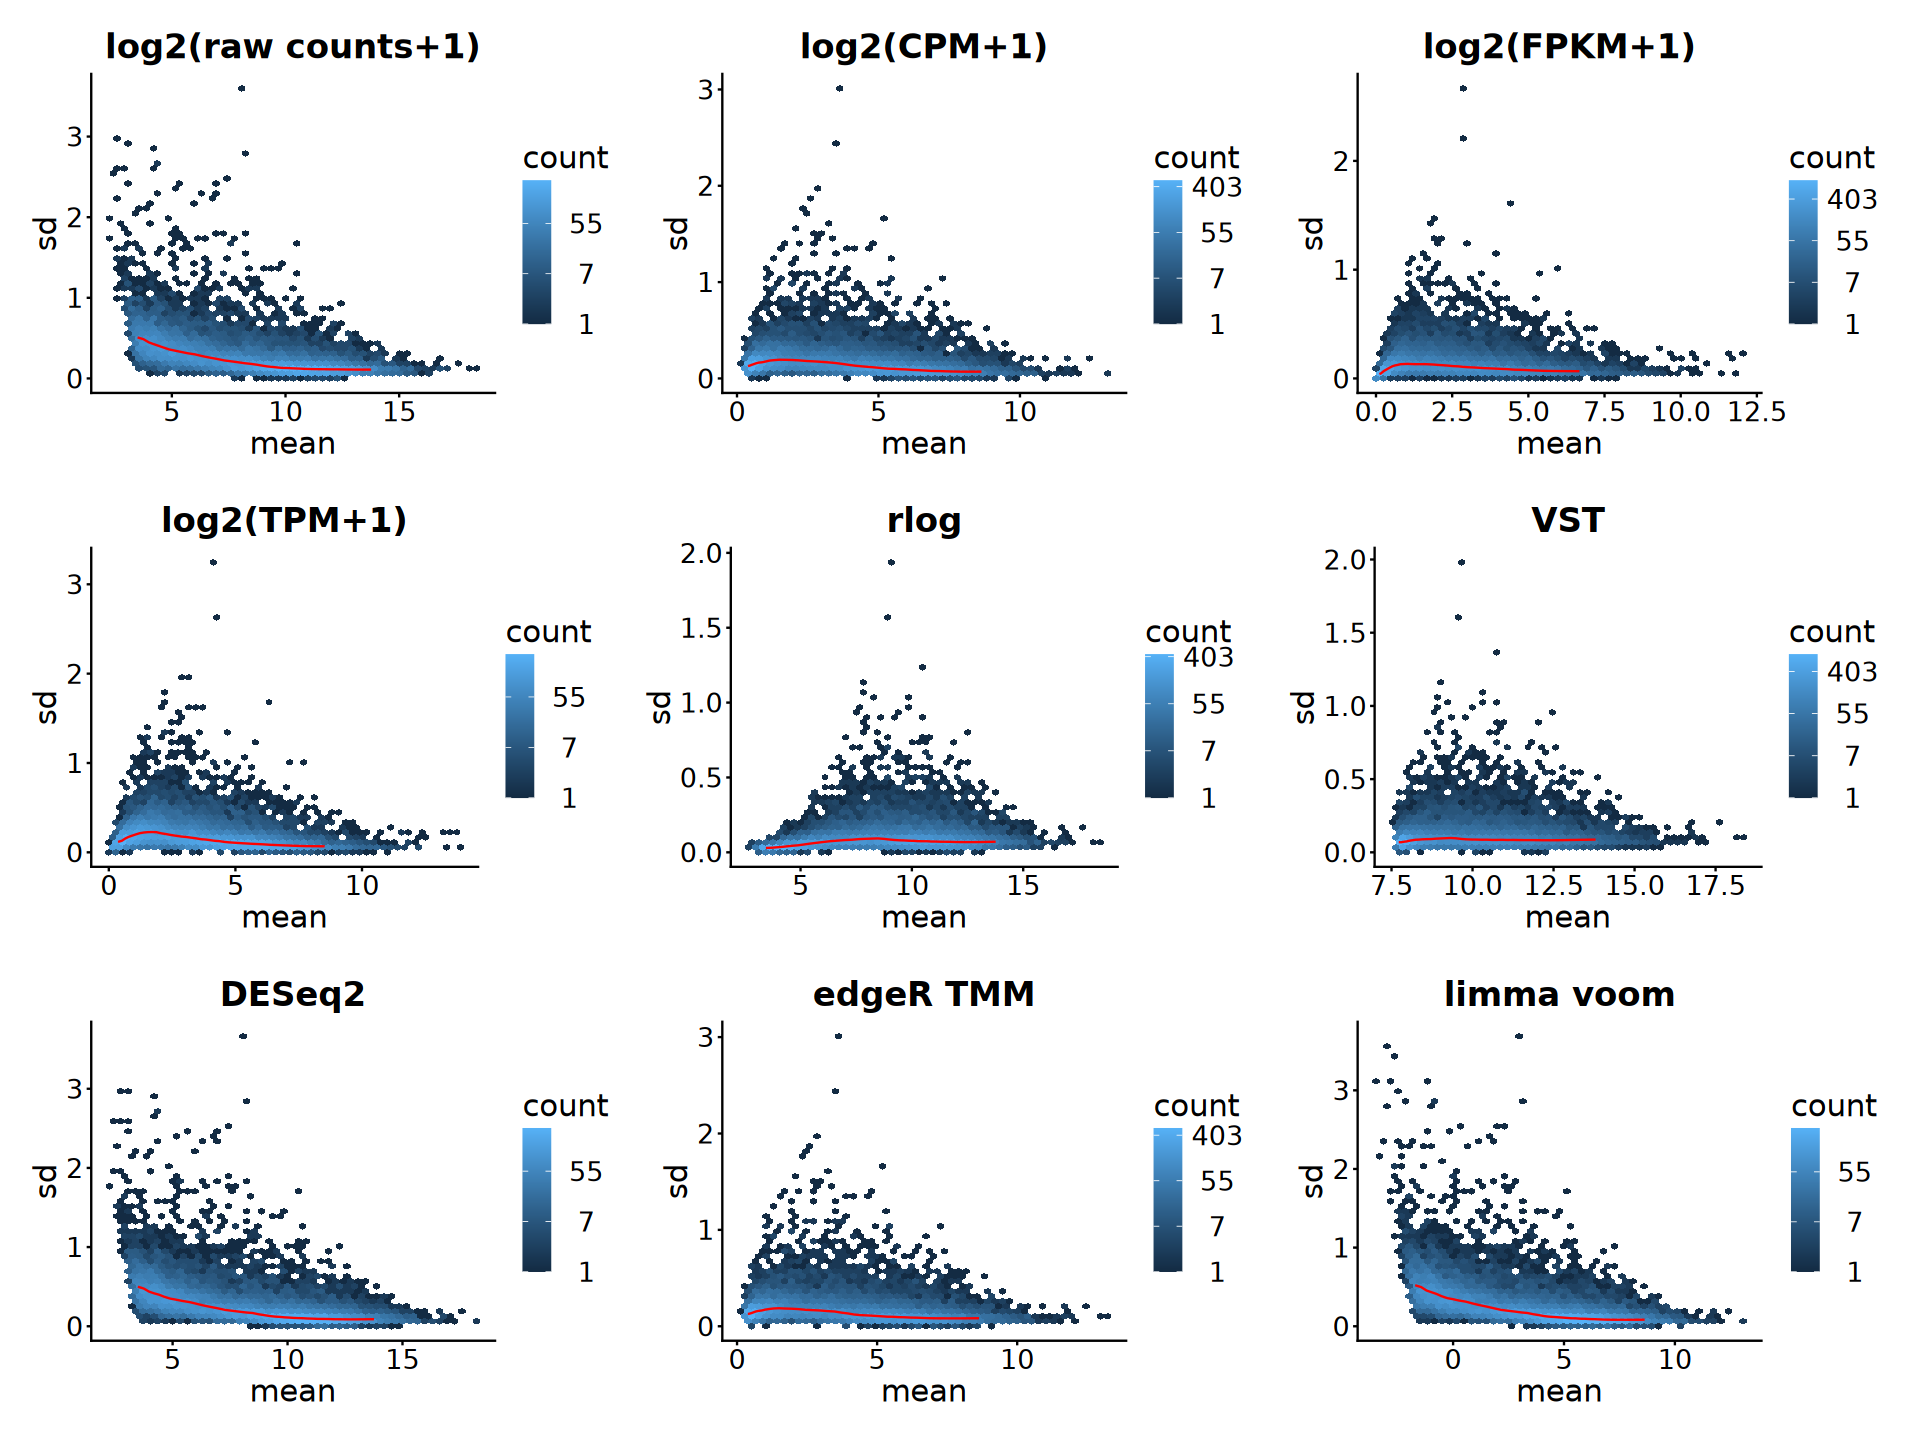

In [43]:
options(repr.plot.width = 16, repr.plot.height = 12)
(p1 + p2 + p3) / (p4 + p5 + p6) / (p7 + p8 + p9)

# 4. Exploration

In [44]:
# Normalized matrices for downstream exploration
norm_mat <- log2(tpm + 1) # log2-TPM for general visualization
norm_vs <- assay(rld) # rlog for PCA/distance/correlation

### 1). Overview

In [45]:
plot_df <- colData(eSet) |>
    as.data.frame() |>
    arrange(Group, Replicate) |>
    rownames_to_column(var = "Sample") |>
    mutate(
        librarySize = colSums(raw_counts)[Sample],
        Sample = gsub("_", "\n", Sample),
        Sample = factor(Sample, levels = Sample)
    )

plot_df

Sample,Cell,Group,Replicate,librarySize
<fct>,<chr>,<fct>,<fct>,<dbl>
LIF rep1,mESC,LIF,rep1,37976626
LIF rep2,mESC,LIF,rep2,35097408
LIF rep3,mESC,LIF,rep3,36474663
RA rep1,mESC,RA,rep1,34120988
RA rep2,mESC,RA,rep2,33606496
RA rep3,mESC,RA,rep3,33322923


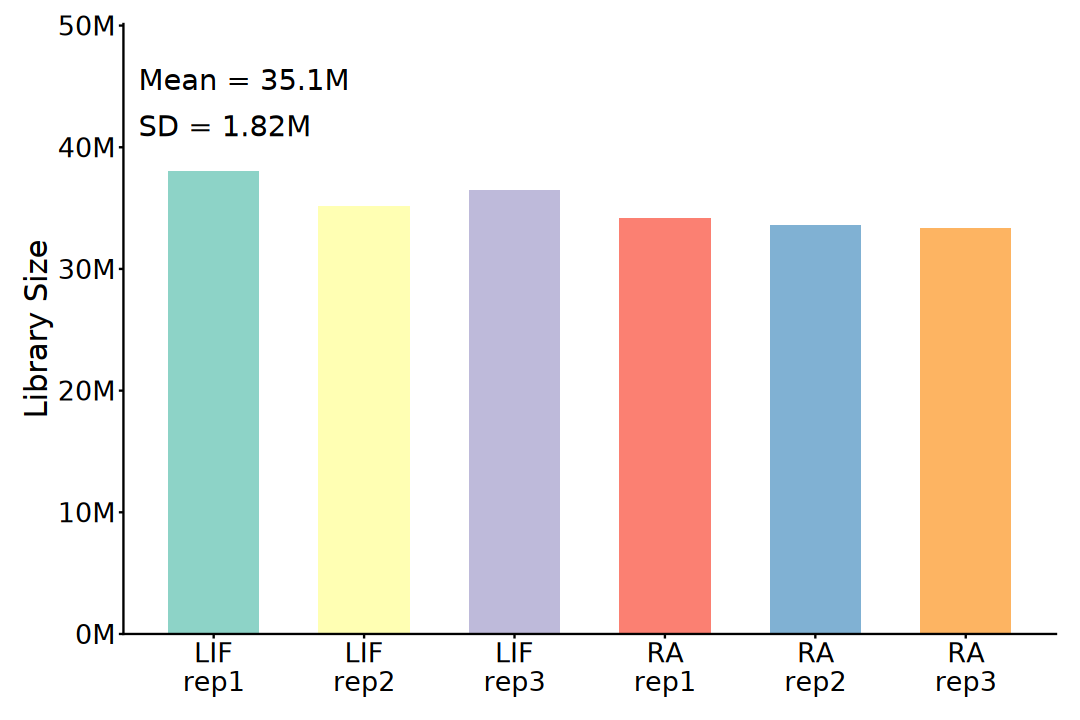

In [46]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Sample, y = librarySize)) +
    geom_col(aes(fill = Sample), width = 0.6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.2,
        label = paste0("Mean = ", round(
            mean(plot_df$librarySize) / 1e6, 2
        ), "M"),
        hjust = 0, size = 6
    ) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("SD = ", round(
            sd(plot_df$librarySize) * 1e-6, 2
        ), "M"),
        hjust = 0, size = 6
    ) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))
    ) +
    scale_fill_brewer(palette = "Set3") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

In [47]:
# Combine count-based QC with featureCounts assignment and available STAR metrics.
# Match upstream summaries to the count-matrix sample order.
qc_samples <- data.frame(
    sample = colnames(raw_counts), Group = coldata$Group,
    assigned_fragments = colSums(raw_counts), detected_genes = colSums(raw_counts > 0),
    genes_count_ge10 = colSums(raw_counts >= 10),
    size_factor = sizeFactors(dds), TMM_factor = dgel$samples$norm.factors
)
fc_summary <- read.delim(file.path(data_dir, "04_counts", "featureCounts.tsv.summary"),
    row.names = 1, check.names = FALSE
)
colnames(fc_summary) <- sub("[.]Aligned[.]out[.]bam$", "", basename(colnames(fc_summary))) |>
    sub("^mESC_", "", x = _)
fc_summary <- fc_summary[, qc_samples$sample, drop = FALSE]
qc_samples$assignment_percent <- 100 * as.numeric(fc_summary["Assigned", ]) / colSums(fc_summary)
star_file <- file.path(data_dir, "multiqc_data", "star_summary_table.txt")
if (file.exists(star_file)) {
    star <- read.delim(star_file, check.names = FALSE)
    sample_idx <- match(paste0("mESC_", qc_samples$sample), star$Sample)
    qc_samples$STAR_unique_percent <- star[["Uniq aligned"]][sample_idx]
}
qc_samples

,sample,Group,assigned_fragments,detected_genes,genes_count_ge10,size_factor,TMM_factor,assignment_percent,STAR_unique_percent
,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LIF_rep1,LIF_rep1,LIF,37976626,25594,16202,1.0424186,0.9748568,65.88073,84.04
LIF_rep2,LIF_rep2,LIF,35097408,25724,16470,1.0181831,1.0173128,64.30941,83.43
LIF_rep3,LIF_rep3,LIF,36474663,26442,16830,1.0716981,1.0242949,63.65648,83.50
RA_rep1,RA_rep1,RA,34120988,25130,16133,0.9426408,0.9661841,65.38337,84.23
RA_rep2,RA_rep2,RA,33606496,26061,16592,0.9736038,1.0069635,64.24210,83.93
RA_rep3,RA_rep3,RA,33322923,25986,16646,0.9722376,1.0118265,64.79603,83.99


In [48]:
# remotes::install_github("psyteachr/introdataviz")
suppressPackageStartupMessages(library(introdataviz))

Warning message:
"Using the `size` aesthetic with geom_polygon was deprecated in ggplot2 3.4.0.
ℹ Please use the `linewidth` aesthetic instead."


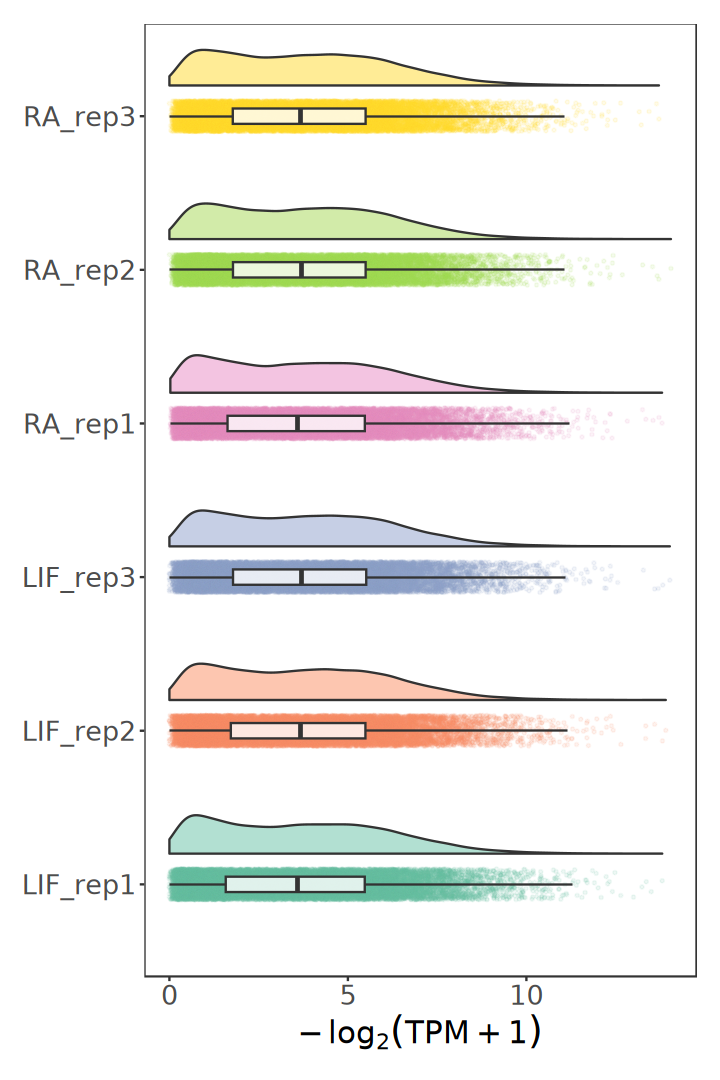

In [49]:
options(repr.plot.width = 6, repr.plot.height = 9)

norm_mat |>
    as.data.frame() |>
    pivot_longer(
        cols = everything(), names_to = "Sample",
        values_to = "Value"
    ) |>
    mutate(
        Sample = factor(Sample, levels = colnames(norm_mat))
    ) |>
    ggplot(aes(x = Sample, y = Value)) +
    geom_flat_violin(
        aes(fill = Sample),
        width = 0.5, alpha = 0.5,
        position = position_nudge(x = 0.2, y = 0)
    ) +
    geom_point(
        aes(color = Sample),
        size = 0.5, alpha = 0.1,
        position = position_jitter(width = 0.1)
    ) +
    geom_boxplot(
        width = 0.1, alpha = 0.8, outlier.shape = NA
    ) +
    scale_fill_brewer(palette = "Set2") +
    scale_colour_brewer(palette = "Set2") +
    coord_flip() +
    labs(x = NULL, y = expression(-log[2](TPM + 1))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

## 2). PCA

Select the most variable genes using rlog expression and reuse this selection for
log2-TPM PCA and count-based GLM-PCA. The rlog PCA also selects `n_top_genes` by
variance. Compare sample grouping across views; the GLM-PCA axes are displayed
without percentages of explained variance.

In [50]:
# Fix one rlog-selected gene set when comparing transformed matrices.
top_var_idx <- norm_vs |>
    matrixStats::rowSds() |>
    tibble::enframe(name = "gene_id", value = "sd") |>
    slice_max(sd, n = n_top_genes, with_ties = FALSE) |>
    pull(gene_id)
stopifnot(all(top_var_idx %in% rownames(norm_mat)))
message("Fixed rlog-variable gene set: ", length(top_var_idx))

Fixed rlog-variable gene set: 1000



In [51]:
pca_res <- norm_mat[top_var_idx, ] |>
    t() |>
    prcomp(center = TRUE, scale. = FALSE)
per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")
message("PCA: PC1=", per_var[1], "%, PC2=", per_var[2], "% variance")
head(pca_df)

PCA: PC1=89.29%, PC2=7.14% variance



,Row.names,PC1,PC2,PC3,PC4,PC5,PC6,Cell,Group,Replicate
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<fct>,<fct>
1,LIF_rep1,-15.07767,5.349553,-3.1403365,0.9476217,-0.6149633,1.398534e-14,mESC,LIF,rep1
2,LIF_rep2,-14.74103,-1.071753,2.2627196,1.9287484,1.5643306,1.243450e-14,mESC,LIF,rep2
3,LIF_rep3,-16.48187,-4.668755,0.6606083,-2.5957673,-0.8965057,1.576517e-14,mESC,LIF,rep3
4,RA_rep1,13.62267,6.461332,1.8495049,-2.0088050,0.4288810,4.385381e-15,mESC,RA,rep1
5,RA_rep2,15.96531,-1.795038,1.3623138,2.1154670,-1.6328522,-3.969047e-15,mESC,RA,rep2
6,RA_rep3,16.71259,-4.275340,-2.9948101,-0.3872648,1.1511096,-7.189128e-15,mESC,RA,rep3


In [52]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ log[2](TPM + 1)),
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")
    ) +
    guides(
        color = guide_legend(override.aes = list(size = 5)),
        shape = guide_legend(override.aes = list(size = 5))
    ) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

In [53]:
pca_res <- plotPCA(
    rld,
    intgroup = c("Group", "Replicate"),
    ntop = n_top_genes, returnData = TRUE
)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=1000 top features by variance



In [54]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog",
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")
    ) +
    guides(
        color = guide_legend(override.aes = list(size = 5)),
        shape = guide_legend(override.aes = list(size = 5))
    ) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

In [55]:
# GLM-PCA: generalized PCA for count data (accounts for count-specific variance structure)
set.seed(123)

gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

gpca_df

DataFrame with 6 rows and 6 columns
    Row.names      dim1      dim2        Cell    Group Replicate
  <character> <numeric> <numeric> <character> <factor>  <factor>
1    LIF_rep1   14.0587 -2.516912        mESC      LIF      rep1
2    LIF_rep2   11.8836  3.164338        mESC      LIF      rep2
3    LIF_rep3   13.1078  6.180805        mESC      LIF      rep3
4     RA_rep1  -10.6430 -7.471601        mESC      RA       rep1
5     RA_rep2  -13.4497 -0.700608        mESC      RA       rep2
6     RA_rep3  -14.9575  1.343978        mESC      RA       rep3

In [56]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)),
        shape = guide_legend(override.aes = list(size = 5))
    ) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

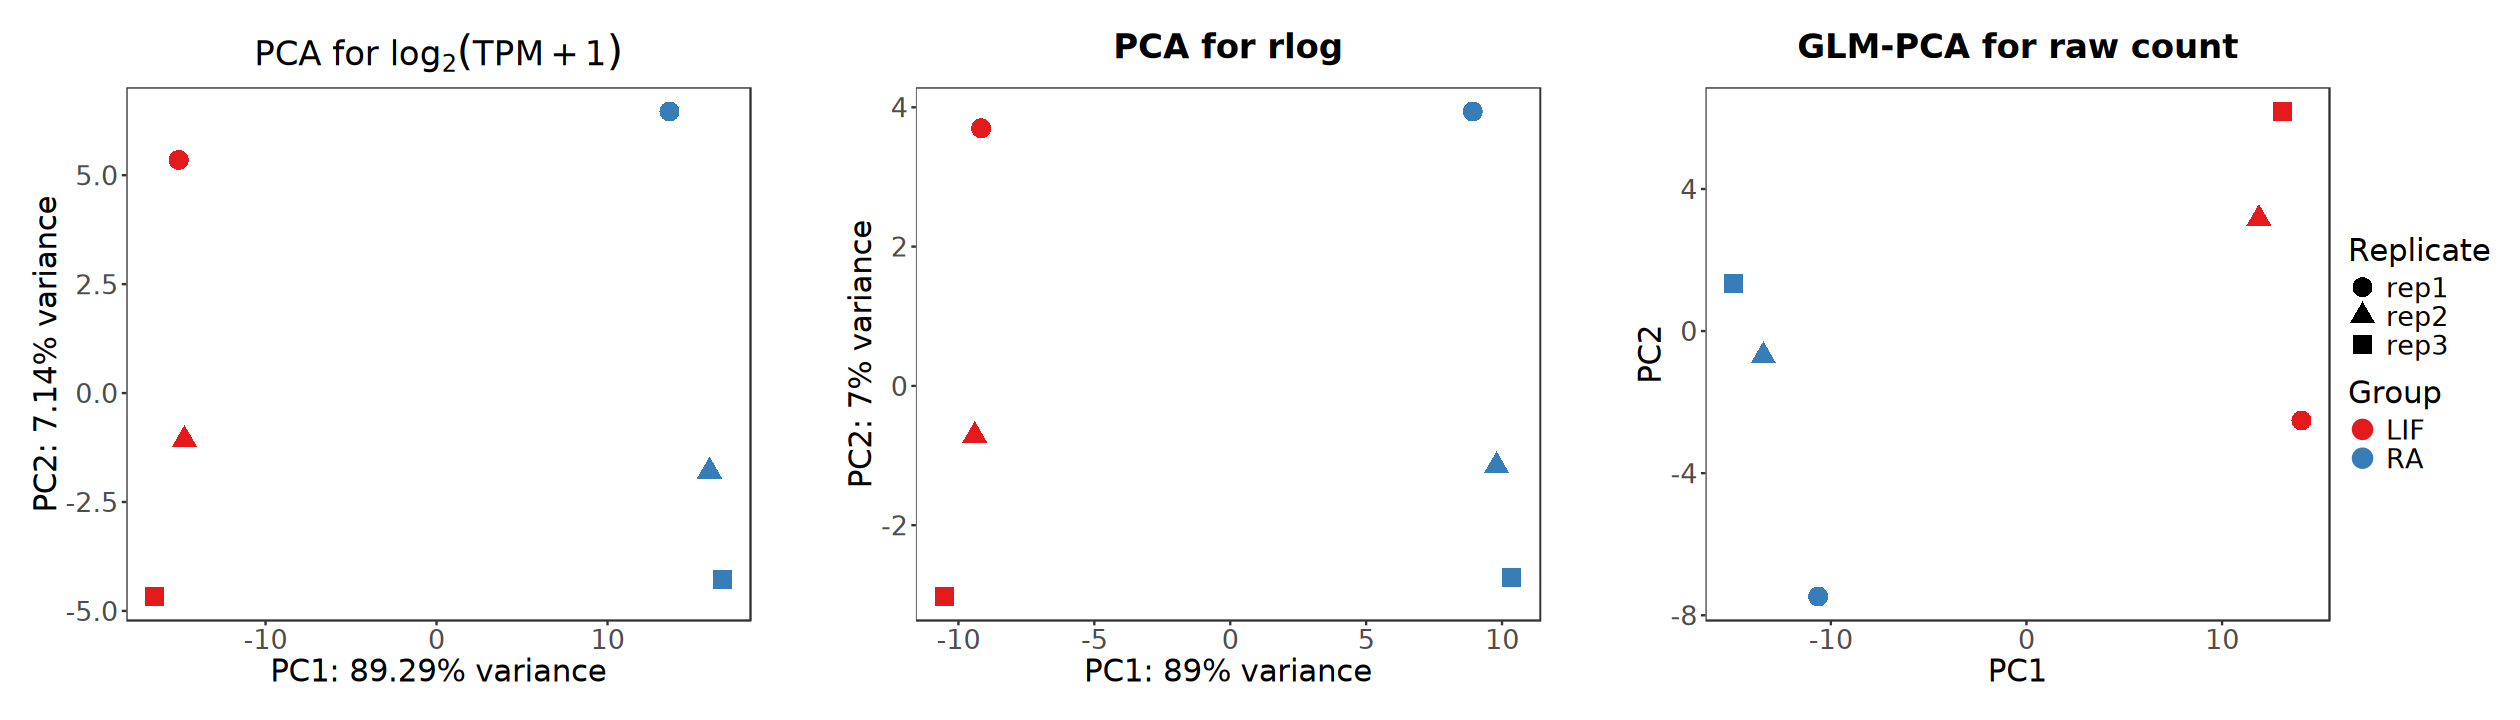

In [57]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect",
        widths = c(1, 0.05, 1, 0.05, 1)
    )

## 3). MDS

> Multidimensional scaling

Compute Euclidean distances between samples using the selected rlog-transformed
genes, then display the two-dimensional configuration alongside sample metadata.

In [58]:
dist_mat <- norm_vs[top_var_idx, ] |>
    t() |>
    dist()

mds <- colData(eSet) |>
    as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

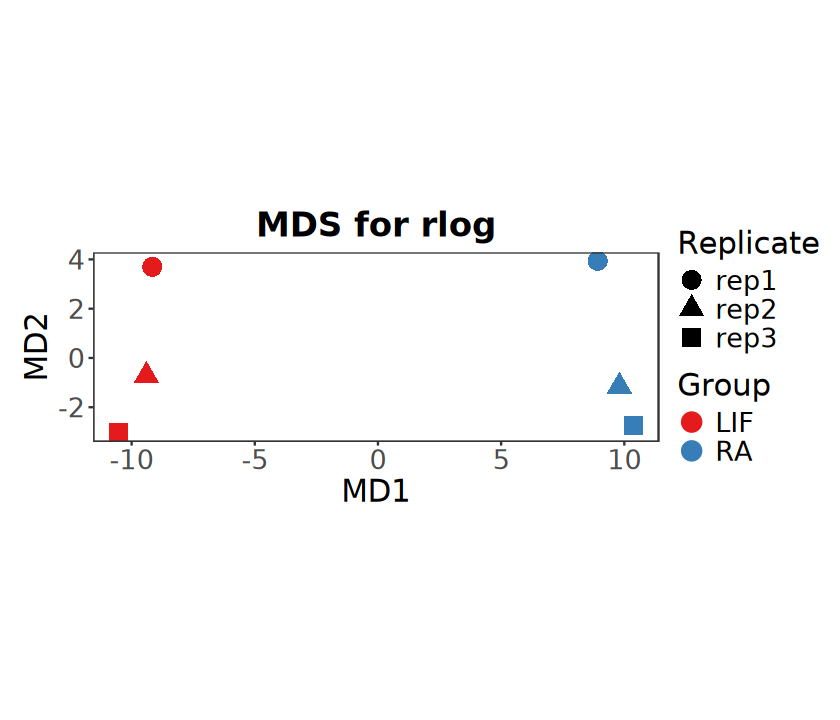

In [59]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() +
    # ggtitle(bquote("MDS for" ~ -log[2](TPM+1))) +
    ggtitle("MDS for rlog") +
    labs(x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)),
        shape = guide_legend(override.aes = list(size = 5))
    ) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

## 4). PCoA

> Principal coordinate analysis

Use Bray-Curtis dissimilarity on nonnegative TPM values. The code checks for
negative eigenvalues and requests an additive correction when needed.

In [60]:
# Bray-Curtis requires nonnegative abundance; use TPM, not rlog.
# Report negative eigenvalues and apply additive correction when necessary.
bray_dist <- vegan::vegdist(t(tpm[top_var_idx, ]), method = "bray")
pcoa_initial <- cmdscale(bray_dist, k = 2, eig = TRUE)
negative_eigenvalues <- sum(pcoa_initial$eig < -1e-8)
pcoa_res <- cmdscale(bray_dist, k = 2, eig = TRUE, add = negative_eigenvalues > 0)
pcoa_df <- merge(pcoa_res$points, as.data.frame(colData(eSet)), by = "row.names")
message("PCoA negative eigenvalues before correction: ", negative_eigenvalues)
head(pcoa_df)

PCoA negative eigenvalues before correction: 1



,Row.names,V1,V2,Cell,Group,Replicate
,<chr>,<dbl>,<dbl>,<chr>,<fct>,<fct>
1,LIF_rep1,-0.09758164,0.052981339,mESC,LIF,rep1
2,LIF_rep2,-0.10707766,-0.019303405,mESC,LIF,rep2
3,LIF_rep3,-0.12225695,-0.027541981,mESC,LIF,rep3
4,RA_rep1,0.09751941,-0.003020953,mESC,RA,rep1
5,RA_rep2,0.10652260,-0.025269569,mESC,RA,rep2
6,RA_rep3,0.12287423,0.022154568,mESC,RA,rep3


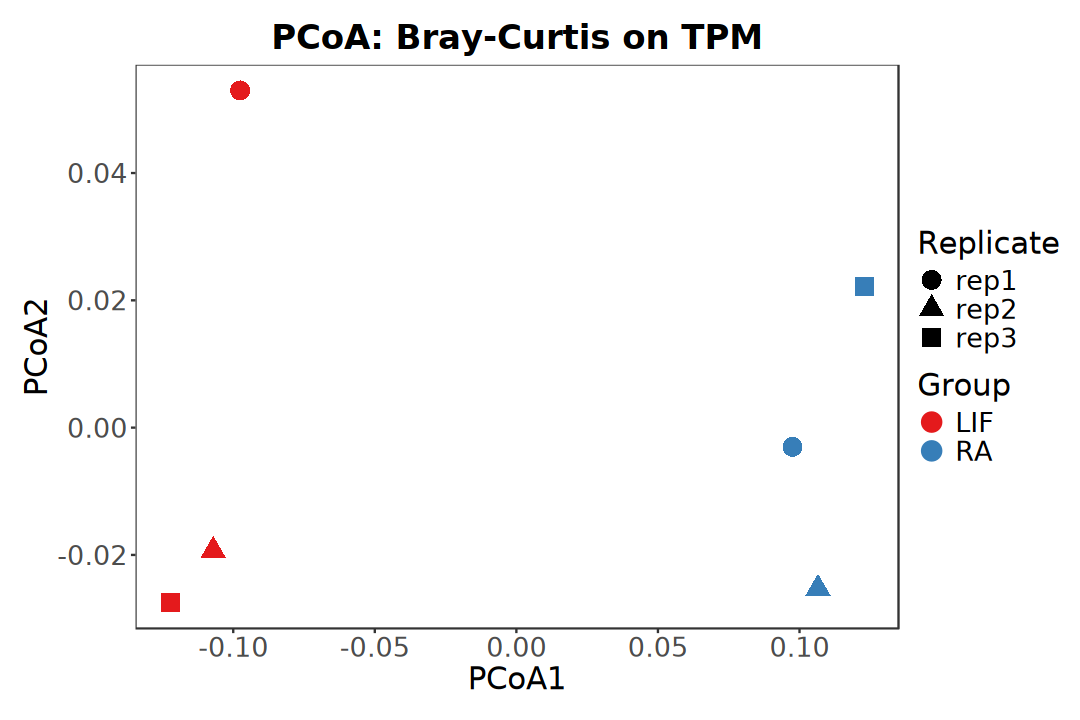

In [61]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    ggtitle("PCoA: Bray-Curtis on TPM") +
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)),
        shape = guide_legend(override.aes = list(size = 5))
    ) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

## 5). Sample Distance

Compare Euclidean distance on rlog expression with Poisson distance on counts.
Each heatmap uses its own distance matrix for clustering and the same sample
annotations for interpretation.

In [62]:
ac <- colData(eSet) |>
    as.data.frame() |>
    dplyr::select(Replicate, Group)

In [63]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group)
)
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate)
)

anno_colors <- list(
    Group = group_colors,
    Replicate = replicate_colors
)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [64]:
dist_mat <- norm_vs[top_var_idx, ] |>
    t() |>
    dist()

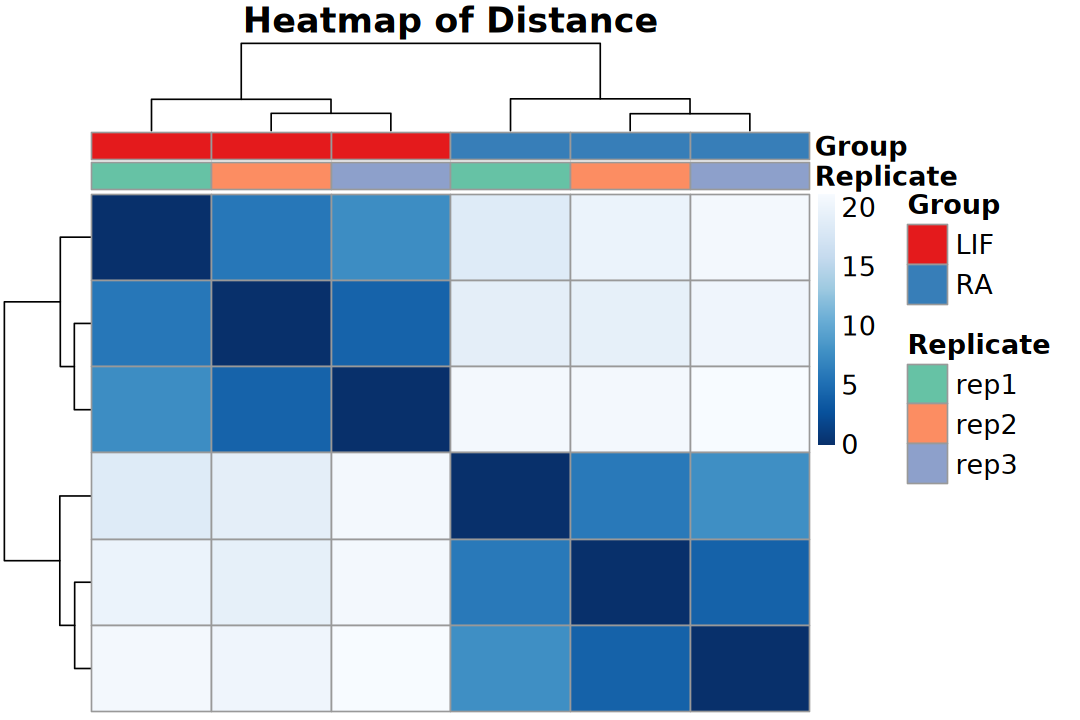

In [65]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors),
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16,
    show_colnames = FALSE, show_rownames = FALSE
)

In [66]:
# Poisson distance (accounts for count-specific variance) on raw count matrix
poisd <- assay(eSet)[top_var_idx, ] |>
    t() |>
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()
colnames(dist_mat) <- colnames(eSet)

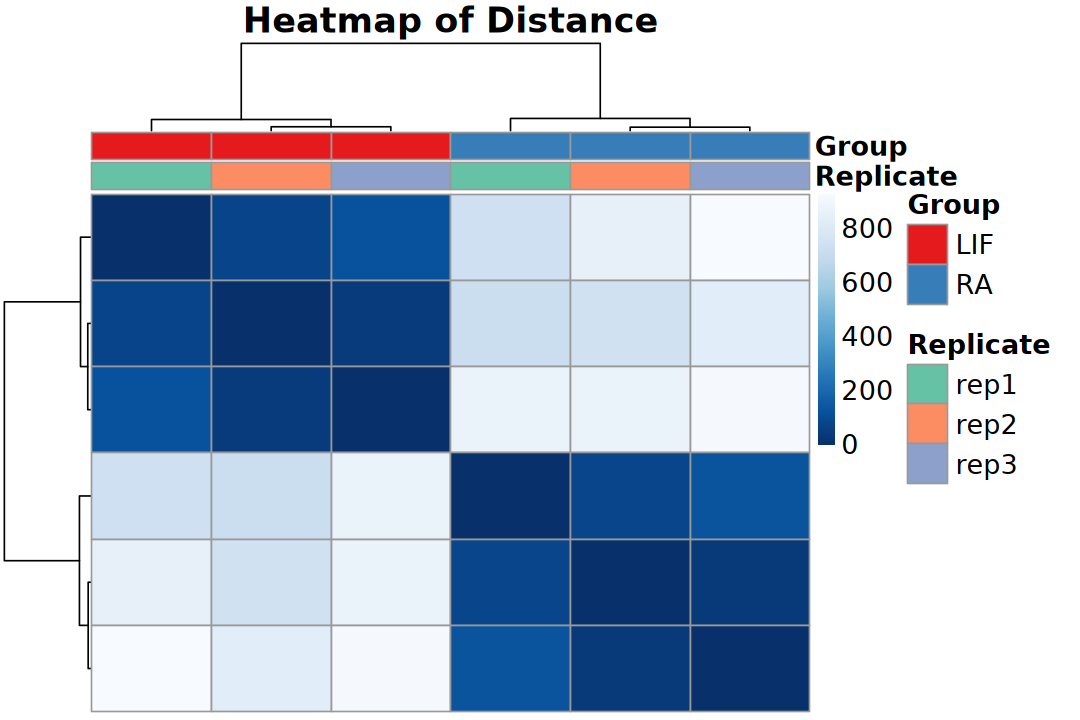

In [67]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors),
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16,
    show_colnames = FALSE, show_rownames = FALSE
)

## 6). Sample Correlation

Calculate Spearman correlations on the selected rlog-transformed genes. The
correlation heatmap clusters samples using `1 - correlation`; inspect both
within-group similarity and differences between groups.

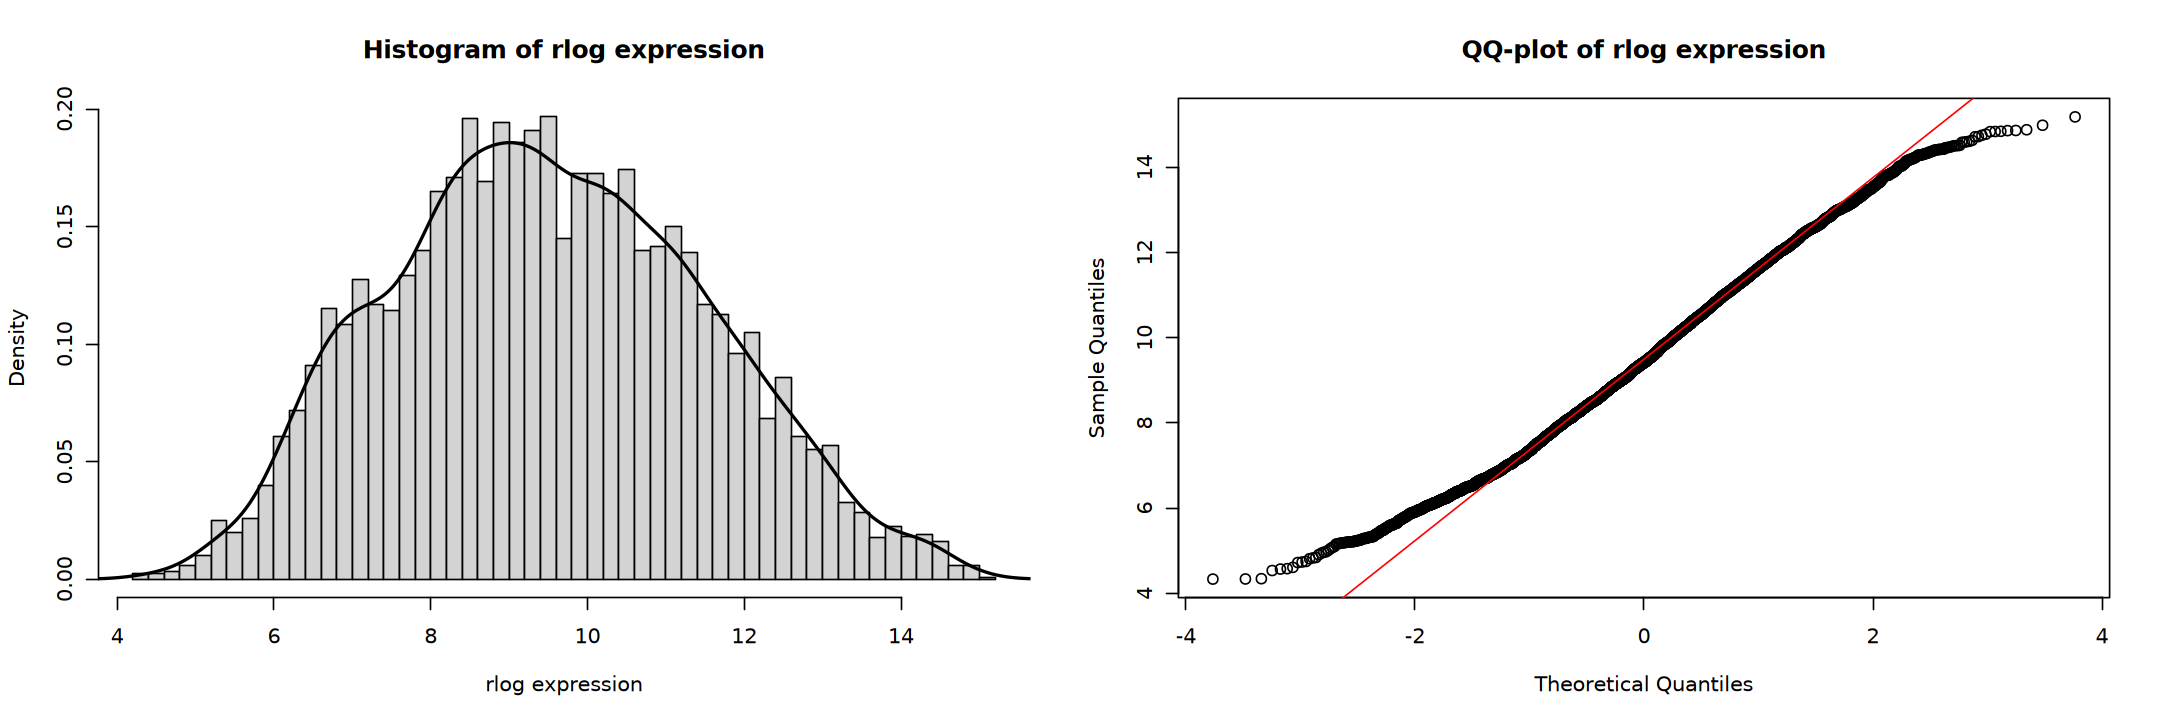

In [68]:
options(repr.plot.width = 18, repr.plot.height = 6)

par(mfrow = c(1, 2))
hist(
    norm_vs[top_var_idx, ],
    breaks = 50, probability = TRUE,
    main = "Histogram of rlog expression", xlab = "rlog expression"
)
lines(density(norm_vs[top_var_idx, ]), lwd = 2)

qqnorm(
    norm_vs[top_var_idx, ],
    main = "QQ-plot of rlog expression"
)
qqline(
    norm_vs[top_var_idx, ],
    col = "red"
)

par(mfrow = c(1, 1))

In [69]:
# cor_mat <- cor(norm_vs[top_var_idx, ], method = "pearson")
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

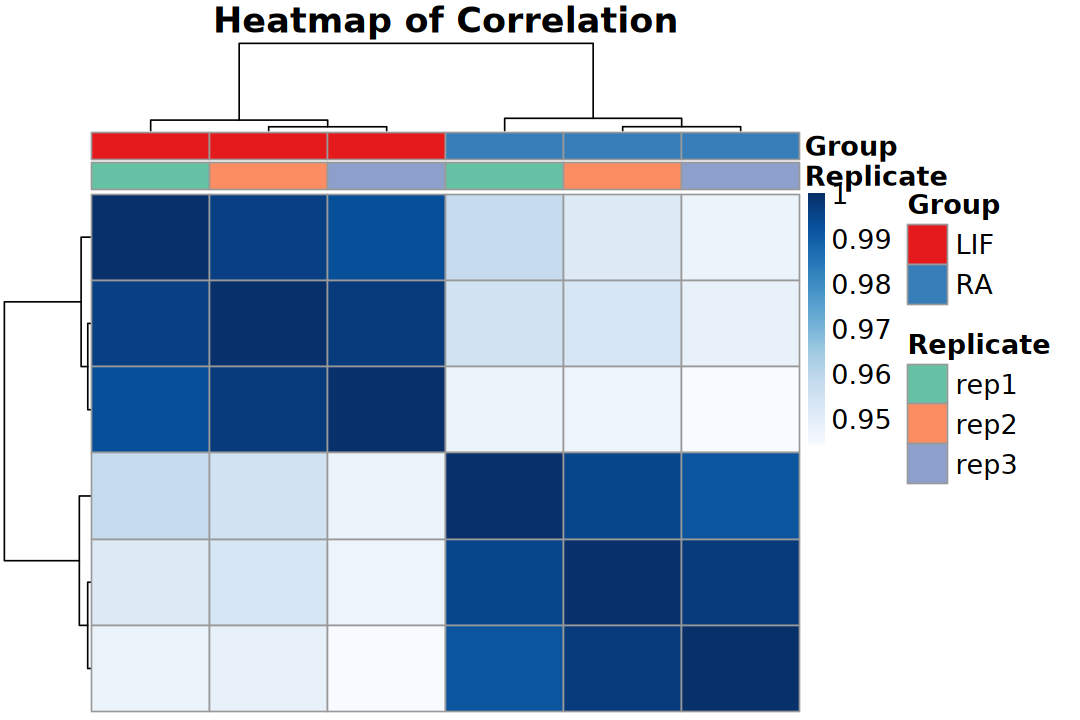

In [70]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat),
    clustering_distance_rows = as.dist(1 - cor_mat),
    clustering_distance_cols = as.dist(1 - cor_mat),
    annotation_col = ac, col = colors,
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16,
    show_colnames = FALSE, show_rownames = FALSE
)

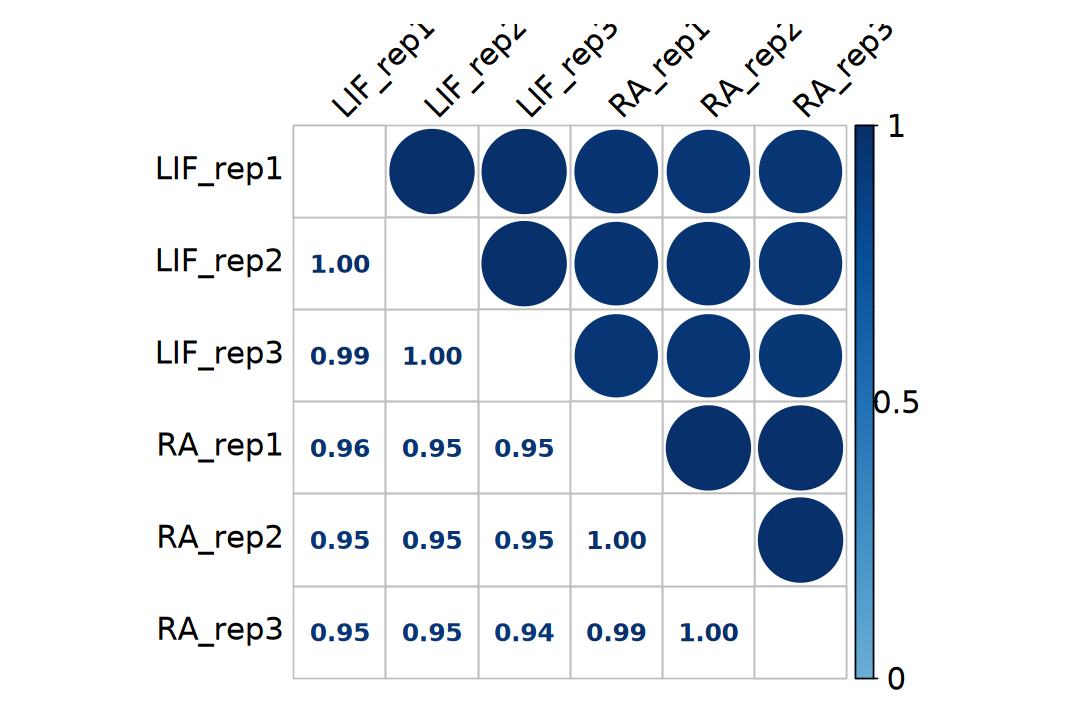

In [71]:
# suppressPackageStartupMessages(library(corrplot))
options(repr.plot.width = 9, repr.plot.height = 6)

corrplot::corrplot.mixed(
    cor_mat,
    order = "hclust", upper.col = colors,
    tl.pos = "lt", tl.cex = 1.5, tl.col = "black", tl.srt = 45,
    number.cex = 1.2, diag = "n", col.lim = c(0, 1),
    lower.col = colors, rect.col = "grey50",
    cl.cex = 1.5, cl.length = 3, mar = c(1, 0, 1, 0)
)

## 7). Heatmap

Display the selected variable genes using log2-TPM expression and row scaling.
Colors represent each gene's relative pattern across samples, rather than its
absolute expression compared with other genes.

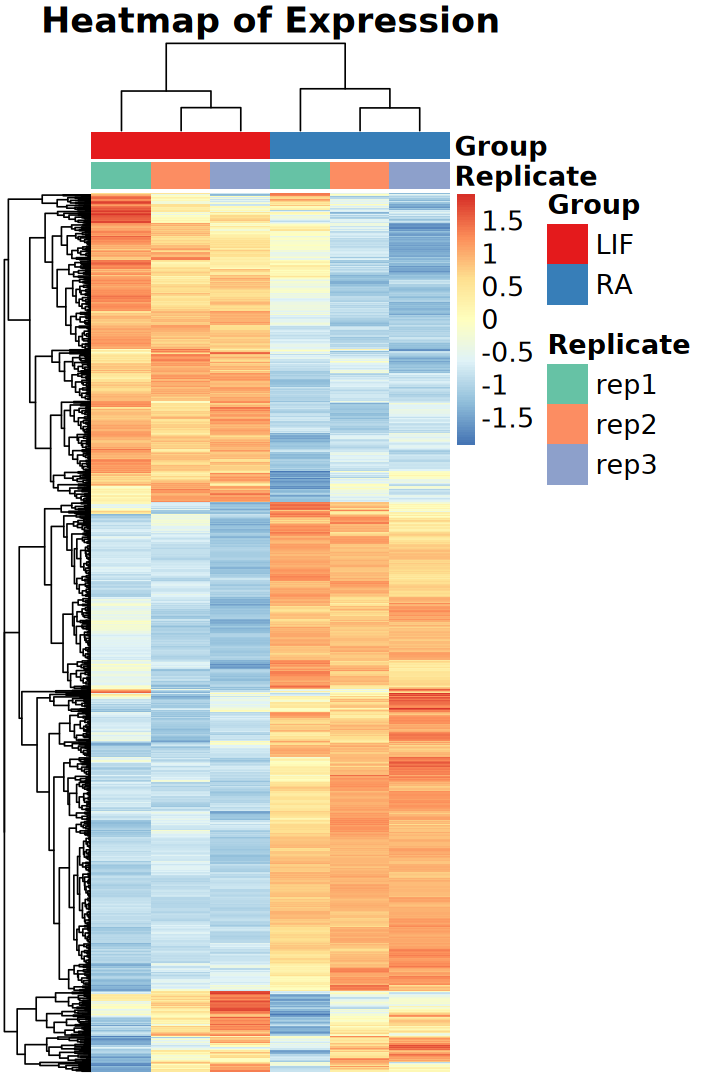

In [72]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ],
    scale = "row",
    annotation_col = ac,
    annotation_colors = anno_colors,
    main = "Heatmap of Expression", fontsize = 16,
    show_colnames = FALSE, show_rownames = FALSE
)

**Sample quality review**

Review mapping rates, assignment rates, library sizes, PCA, and sample correlations
together before interpreting differential expression. If a sample separates from
its group, check its label and experimental records before changing the analysis.

# 5. DEGs

In [73]:
# Thresholds are configured once above.
stopifnot(p_cutoff > 0, p_cutoff < 1, logfc_cutoff >= 0)
stopifnot(identical(colnames(norm_vs), rownames(coldata)), all(is.finite(norm_vs)))
print(with(coldata, table(Group)))

Group
LIF  RA 
  3   3 


## 1). DESeq2

> median of ratios for normalization

In [74]:
design(dds)

~Group

In [75]:
# ---- Execute DESeq2 pipeline ----
# Runs size factor estimation → dispersion estimation → GLM Wald test.
dds <- DESeq(dds)

using pre-existing size factors



estimating dispersions



gene-wise dispersion estimates



mean-dispersion relationship



final dispersion estimates



fitting model and testing



In [76]:
resultsNames(dds)

[1] "Intercept"       "Group_RA_vs_LIF"

### a). Standard

Two result objects answer different questions. `res` uses the configured effect
threshold (`lfcThreshold = logfc_cutoff`), whereas `res_zero` uses the ordinary
zero-effect Wald test. The main DEG labels come from `res`; the ordinary Wald
statistic is retained separately for GSEA.

In the formatted tables, `Up` and `Down` indicate the configured significance and
direction criteria. `NS` denotes a tested gene that does not meet those criteria;
`Not_tested` denotes an unavailable adjusted P value or nonfinite effect estimate.

In [77]:
# Primary: effect-threshold test. Secondary: ordinary zero-effect Wald test.
res <- results(dds,
    contrast = c("Group", "RA", "LIF"),
    lfcThreshold = logfc_cutoff, altHypothesis = "greaterAbs", alpha = p_cutoff
)
res_zero <- results(dds, contrast = c("Group", "RA", "LIF"), alpha = p_cutoff)
summary(res, alpha = p_cutoff)


out of 16530 with nonzero total read count
adjusted p-value < 0.05
LFC > 1.00 (up)    : 139, 0.84%
LFC < -1.00 (down) : 19, 0.11%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 7)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [78]:
# ---- Helper: Format DESeq2 results ----
# Convert DESeqResults to standardized data.frame with gene annotations & DEG classification.
format_degs <- function(res, row_data, p_cutoff, logfc_cutoff) {
    gene_info <- row_data |>
        as.data.frame() |>
        dplyr::select(symbol, type, basepairs) |>
        rownames_to_column("gene_id")

    res |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            result = case_when(
                is.na(padj) | !is.finite(logFC) ~ "Not_tested",
                padj < p_cutoff & logFC > logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ),
            result = factor(result, levels = c("Up", "Down", "NS", "Not_tested"))
        ) |>
        left_join(gene_info, by = "gene_id") |>
        column_to_rownames("gene_id")
}

deseq2_raw_result <- format_degs(res, rowData(dds), p_cutoff, logfc_cutoff)

message(
    "DESeq2 raw DEGs: ",
    sum(deseq2_raw_result$result == "Up"), " Up, ",
    sum(deseq2_raw_result$result == "Down"), " Down, ",
    sum(deseq2_raw_result$result == "NS"), " NS"
)
head(deseq2_raw_result)

DESeq2 raw DEGs: 139 Up, 19 Down, 16372 NS



,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000103922.1,306.13640,-0.03227810,0.13155730,-0.2453539,1.0000000,1,NS,Gm6123,processed_pseudogene,1069
ENSMUSG00000033845.13,6512.55715,-0.07839193,0.07675145,-1.0213739,1.0000000,1,NS,Mrpl15,protein_coding,8487
ENSMUSG00000102275.1,41.31779,0.08454261,0.33236696,0.2543653,0.9976107,1,NS,Gm37144,TEC,1150
ENSMUSG00000025903.14,5224.10833,-0.14286057,0.09450943,-1.5116013,1.0000000,1,NS,Lypla1,protein_coding,7145
ENSMUSG00000033813.15,4460.65461,-0.02881031,0.08286007,-0.3476983,1.0000000,1,NS,Tcea1,protein_coding,3017
ENSMUSG00000002459.17,19.28810,1.01858313,0.52077258,1.9559078,0.4858203,1,NS,Rgs20,protein_coding,4239


In [79]:
deseq2_zero_result <- format_degs(res_zero, rowData(dds), p_cutoff, logfc_cutoff)
# Preserve the ordinary Wald statistic for full-list GSEA.
deseq2_raw_result$stat_zero <- res_zero$stat[match(
    rownames(deseq2_raw_result),
    rownames(res_zero)
)]
deseq2_raw_result$test_status <- ifelse(is.na(res$pvalue), "pvalue_unavailable",
    ifelse(is.na(res$padj), "independent_filter", "tested")
)

### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

Use `apeglm` to obtain shrunken effects for the `Group_RA_vs_LIF` coefficient.
The merged table retains both `logFC_MLE` and `logFC_shrunk`. Gene-ID matching keeps
these estimates aligned with the original threshold-test results.

In [80]:
# Shrink coefficients using the explicitly defined ordinary result.
# Attach primary threshold-test inference by ID separately; shrinkage must not redefine DEGs.
res_lfc <- lfcShrink(dds, coef = "Group_RA_vs_LIF", res = res_zero, type = "apeglm")
summary(res_lfc, alpha = p_cutoff)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 16530 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 1179, 7.1%
LFC < 0 (down)     : 827, 5%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 7)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [81]:
deseq2_lfc_result <- deseq2_raw_result
idx <- match(rownames(deseq2_lfc_result), rownames(res_lfc))
deseq2_lfc_result$logFC_MLE <- deseq2_lfc_result$logFC
deseq2_lfc_result$logFC_shrunk <- res_lfc$log2FoldChange[idx]
deseq2_lfc_result$posteriorSD <- res_lfc$lfcSE[idx]
# Keep original lfcSE (Wald SE) separate from posteriorSD.
deseq2_lfc_result$logFC <- deseq2_lfc_result$logFC_shrunk
stopifnot(
    identical(deseq2_lfc_result$result, deseq2_raw_result$result),
    identical(deseq2_lfc_result$padj, deseq2_raw_result$padj)
)
head(deseq2_lfc_result)

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs,stat_zero,test_status,logFC_MLE,logFC_shrunk,posteriorSD
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
ENSMUSG00000103922.1,306.13640,-0.02402360,0.13155730,-0.2453539,1.0000000,1,NS,Gm6123,processed_pseudogene,1069,-0.2453539,tested,-0.03227810,-0.02402360,0.11389662
ENSMUSG00000033845.13,6512.55715,-0.07046380,0.07675145,-1.0213739,1.0000000,1,NS,Mrpl15,protein_coding,8487,-1.0213739,tested,-0.07839193,-0.07046380,0.07317623
ENSMUSG00000102275.1,41.31779,0.02699873,0.33236696,0.2543653,0.9976107,1,NS,Gm37144,TEC,1150,0.2543653,tested,0.08454261,0.02699873,0.18804158
ENSMUSG00000025903.14,5224.10833,-0.12419968,0.09450943,-1.5116013,1.0000000,1,NS,Lypla1,protein_coding,7145,-1.5116013,tested,-0.14286057,-0.12419968,0.08960766
ENSMUSG00000033813.15,4460.65461,-0.02547432,0.08286007,-0.3476983,1.0000000,1,NS,Tcea1,protein_coding,3017,-0.3476983,tested,-0.02881031,-0.02547432,0.07786771
ENSMUSG00000002459.17,19.28810,0.22180095,0.52077258,1.9559078,0.4858203,1,NS,Rgs20,protein_coding,4239,1.9559078,tested,1.01858313,0.22180095,0.34815740


### Evaluate shrinkage

DEG labels and adjusted P values remain those of the primary threshold test; only displayed effect estimates change.

In [82]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [83]:
shrink_df <- deseq2_lfc_result |>
    rownames_to_column("gene_id") |>
    mutate(log_baseMean = log10(baseMean + 1))

In [84]:
p1 <- ggplot(shrink_df, aes(logFC_MLE, logFC_shrunk, color = log_baseMean)) +
    geom_point(size = 0.6, alpha = 0.6) +
    geom_abline(slope = 1, intercept = 0, linetype = 2) +
    scale_color_viridis_c() +
    theme_classic() +
    labs(x = "MLE log2FC", y = "Shrunken log2FC", title = "Effect estimation: RA vs LIF")
p2 <- ggplot(shrink_df, aes(log_baseMean, logFC_shrunk - logFC_MLE)) +
    geom_point(size = 0.6, alpha = 0.4) +
    theme_classic() +
    labs(x = "log10(baseMean+1)", y = "Shrunken − MLE", title = "Shrinkage by abundance")

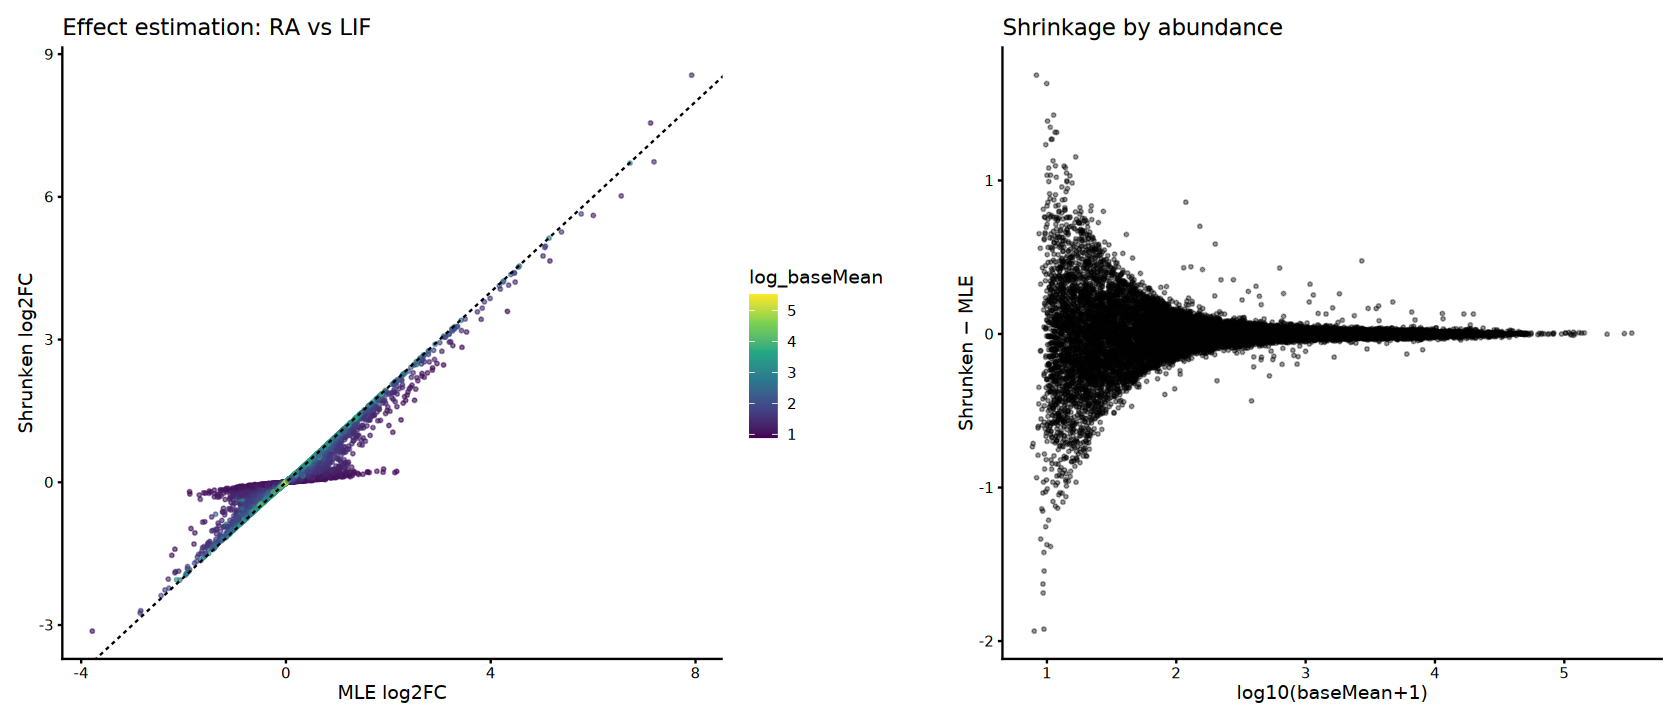

In [85]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 2). edgeR

TMM normalization is shared. Classic exact test and GLM LRT remain educational alternatives. QL v3 is explicitly `legacy=TRUE`; QL v4 is explicitly `legacy=FALSE` and adjusts small-count deviances and degrees of freedom. The v4 common **NB** dispersion must not be confused with gene-specific moderated **QL** dispersions. Ordinary tests below use a zero-effect null; threshold tests are added separately.

### a). Classic pipeline

In [86]:
# ---- edgeR Classic: estimate dispersions ----
# qCML method for simple 2-group designs. φ: Var = μ + φ μ² in NB model.
dgel_classic <- estimateDisp(dgel)
# # 1. Estimate common dispersion
# dgel <- estimateCommonDisp(dgel)
# # 2. Estimate tagwise dispersions
# dgel <- estimateTagwiseDisp(dgel)

message("edgeR classic dispersion — Common: ", round(dgel_classic$common.dispersion, 4))

Using classic mode.



edgeR classic dispersion — Common: 0.0069



In [87]:
# ---- Exact test (edgeR v1, simple 2-group) ----
et <- exactTest(dgel_classic, pair = c("LIF", "RA"))

In [88]:
# ---- Helper: Format edgeR results ----
# Standardize edgeR output (exactTest, glmLRT, glmQLFTest) into unified DEG table.
format_edger <- function(et, p_cutoff, logfc_cutoff) {
    topTags(et, n = Inf) |>
        as.data.frame() |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            result = case_when(
                is.na(padj) | !is.finite(logFC) ~ "Not_tested",
                padj < p_cutoff & logFC > logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ),
            result = factor(result, levels = c("Up", "Down", "NS", "Not_tested"))
        )
}

edger_classic_result <- format_edger(et, p_cutoff, logfc_cutoff)

message(
    "edgeR classic DEGs: ",
    sum(edger_classic_result$result == "Up"), " Up, ",
    sum(edger_classic_result$result == "Down"), " Down, ",
    sum(edger_classic_result$result == "NS"), " NS"
)
head(edger_classic_result)

edgeR classic DEGs: 505 Up, 174 Down, 15851 NS



,symbol,type,basepairs,logFC,logCPM,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000024987.6,Cyp26a1,protein_coding,1983,6.728467,5.266745,8.183069e-292,1.352661e-287,Up
ENSMUSG00000029848.11,Stra8,protein_coding,1803,5.150705,4.758325,1.087476e-290,8.987990e-287,Up
ENSMUSG00000030306.14,Tmtc1,protein_coding,8578,2.694980,5.195372,5.437620e-228,2.996128e-224,Up
ENSMUSG00000048490.14,Nrip1,protein_coding,11457,2.558837,5.080801,1.335088e-164,5.517253e-161,Up
ENSMUSG00000031486.15,Adgra2,protein_coding,5775,4.568433,3.513802,1.117568e-161,3.694679e-158,Up
ENSMUSG00000039047.17,Pigk,protein_coding,9495,1.954252,5.846413,4.483599e-138,1.235231e-134,Up


### b). Negative binomial GLM framework

In [89]:
# ---- edgeR GLM: construct design matrix ----
design <- model.matrix(~group, data = dgel$samples)
design

,(Intercept),groupRA
LIF_rep1,1,0
LIF_rep2,1,0
LIF_rep3,1,0
RA_rep1,1,1
RA_rep2,1,1
RA_rep3,1,1


In [90]:
# ---- edgeR GLM: estimate dispersions ----
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [91]:
# ---- edgeR GLM: fit + likelihood ratio test (LRT) ----
# LRT compares full model (~group) vs reduced model (~1).
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = 2)

In [92]:
edger_glm_lrt_result <- format_edger(lrt, p_cutoff, logfc_cutoff)

message(
    "edgeR GLM LRT DEGs: ",
    sum(edger_glm_lrt_result$result == "Up"), " Up, ",
    sum(edger_glm_lrt_result$result == "Down"), " Down, ",
    sum(edger_glm_lrt_result$result == "NS"), " NS"
)
head(edger_glm_lrt_result)

edgeR GLM LRT DEGs: 513 Up, 180 Down, 15837 NS



,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000024987.6,Cyp26a1,protein_coding,1983,6.728467,5.266748,1338.9411,3.898263e-293,6.443829e-289,Up
ENSMUSG00000029848.11,Stra8,protein_coding,1803,5.150693,4.758329,1327.1095,1.452066e-290,1.200133e-286,Up
ENSMUSG00000030306.14,Tmtc1,protein_coding,8578,2.694980,5.195375,967.6542,1.928367e-212,1.062530e-208,Up
ENSMUSG00000031486.15,Adgra2,protein_coding,5775,4.568447,3.513809,732.3618,2.745683e-161,1.134654e-157,Up
ENSMUSG00000048490.14,Nrip1,protein_coding,11457,2.558837,5.080804,706.3096,1.269559e-155,4.197162e-152,Up
ENSMUSG00000039047.17,Pigk,protein_coding,9495,1.954252,5.846414,610.0370,1.098234e-134,3.025634e-131,Up


### c). Quasi-likelihood pipeline (edgeR v3)

In [93]:
design <- model.matrix(~group, data = dgel$samples) # include intercept

In [94]:
dgel_nbglm <- estimateDisp(dgel, design)

In [95]:
# ---- edgeR Quasi-likelihood F-test (v3) ----
# Tag-wise QL dispersion → better FDR control than LRT; accounts for dispersion uncertainty.
fit_edger_qlf <- glmQLFit(dgel_nbglm, design, legacy = TRUE, robust = TRUE)
qlf_v3 <- glmQLFTest(fit_edger_qlf, coef = 2)
message("edgeR QLF (v3) completed")

edgeR QLF (v3) completed



In [96]:
edger_glm_qlf_result <- format_edger(qlf_v3, p_cutoff, logfc_cutoff)

message(
    "edgeR QLF (v3) DEGs: ",
    sum(edger_glm_qlf_result$result == "Up"), " Up, ",
    sum(edger_glm_qlf_result$result == "Down"), " Down, ",
    sum(edger_glm_qlf_result$result == "NS"), " NS"
)
head(edger_glm_qlf_result)

edgeR QLF (v3) DEGs: 475 Up, 155 Down, 15900 NS



,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000030306.14,Tmtc1,protein_coding,8578,2.695005,5.195375,1425.2325,3.290789e-14,5.439674e-10,Up
ENSMUSG00000029848.11,Stra8,protein_coding,1803,5.150854,4.758329,1210.1501,1.312631e-13,8.788405e-10,Up
ENSMUSG00000024987.6,Cyp26a1,protein_coding,1983,6.728201,5.266748,1482.6551,1.594992e-13,8.788405e-10,Up
ENSMUSG00000048490.14,Nrip1,protein_coding,11457,2.558754,5.080804,912.8571,5.110915e-13,2.112086e-09,Up
ENSMUSG00000039047.17,Pigk,protein_coding,9495,1.954254,5.846414,857.1969,7.520329e-13,2.486221e-09,Up
ENSMUSG00000001348.15,Acp5,protein_coding,2030,3.252211,3.399283,634.3321,4.752553e-12,1.139167e-08,Up


### d). Quasi-likelihood pipeline (edgeR v4)

In [97]:
design <- model.matrix(~group, data = dgel$samples)

In [98]:
# ---- edgeR QLF (v4) ----
# Common NB dispersion with moderated gene-wise QL dispersions.
fit_edger_qlf_v4 <- glmQLFit(dgel, design, legacy = FALSE, robust = TRUE)
qlf_v4 <- glmQLFTest(fit_edger_qlf_v4, coef = 2)

In [99]:
edger_glm_qlf_v4_result <- format_edger(qlf_v4, p_cutoff, logfc_cutoff)

message(
    "edgeR QLF (v4) DEGs: ",
    sum(edger_glm_qlf_v4_result$result == "Up"), " Up, ",
    sum(edger_glm_qlf_v4_result$result == "Down"), " Down, ",
    sum(edger_glm_qlf_v4_result$result == "NS"), " NS"
)
head(edger_glm_qlf_v4_result)

edgeR QLF (v4) DEGs: 477 Up, 157 Down, 15896 NS



,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000030306.14,Tmtc1,protein_coding,8578,2.694964,5.199514,1393.5011,1.705425e-13,1.286132e-09,Up
ENSMUSG00000024987.6,Cyp26a1,protein_coding,1983,6.728106,5.271870,1334.4831,2.202454e-13,1.286132e-09,Up
ENSMUSG00000029848.11,Stra8,protein_coding,1803,5.151708,4.765169,1320.1265,2.334178e-13,1.286132e-09,Up
ENSMUSG00000048490.14,Nrip1,protein_coding,11457,2.559075,5.085065,908.7523,2.011454e-12,8.312332e-09,Up
ENSMUSG00000039047.17,Pigk,protein_coding,9495,1.954250,5.848635,836.6591,3.236887e-12,1.070115e-08,Up
ENSMUSG00000031486.15,Adgra2,protein_coding,5775,4.567552,3.526836,737.6425,6.695281e-12,1.844550e-08,Up


### Evaluate DEGs

In [100]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [101]:
genes_up <- list(
    classic = edger_classic_result |> filter(result == "Up") |>
        rownames() |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Up") |>
        rownames() |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Up") |>
        rownames() |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Up") |>
        rownames() |> unique()
)

genes_down <- list(
    classic = edger_classic_result |> filter(result == "Down") |>
        rownames() |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Down") |>
        rownames() |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Down") |>
        rownames() |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Down") |>
        rownames() |> unique()
)

In [102]:
p1 <- ggVennDiagram(
    genes_up,
    set_color = "grey", set_size = 6,
    label_color = "firebrick", label_size = 5
) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down,
    set_color = "grey", set_size = 6,
    label_color = "firebrick", label_size = 5
) +
    scale_fill_distiller(palette = "Reds", direction = 1)

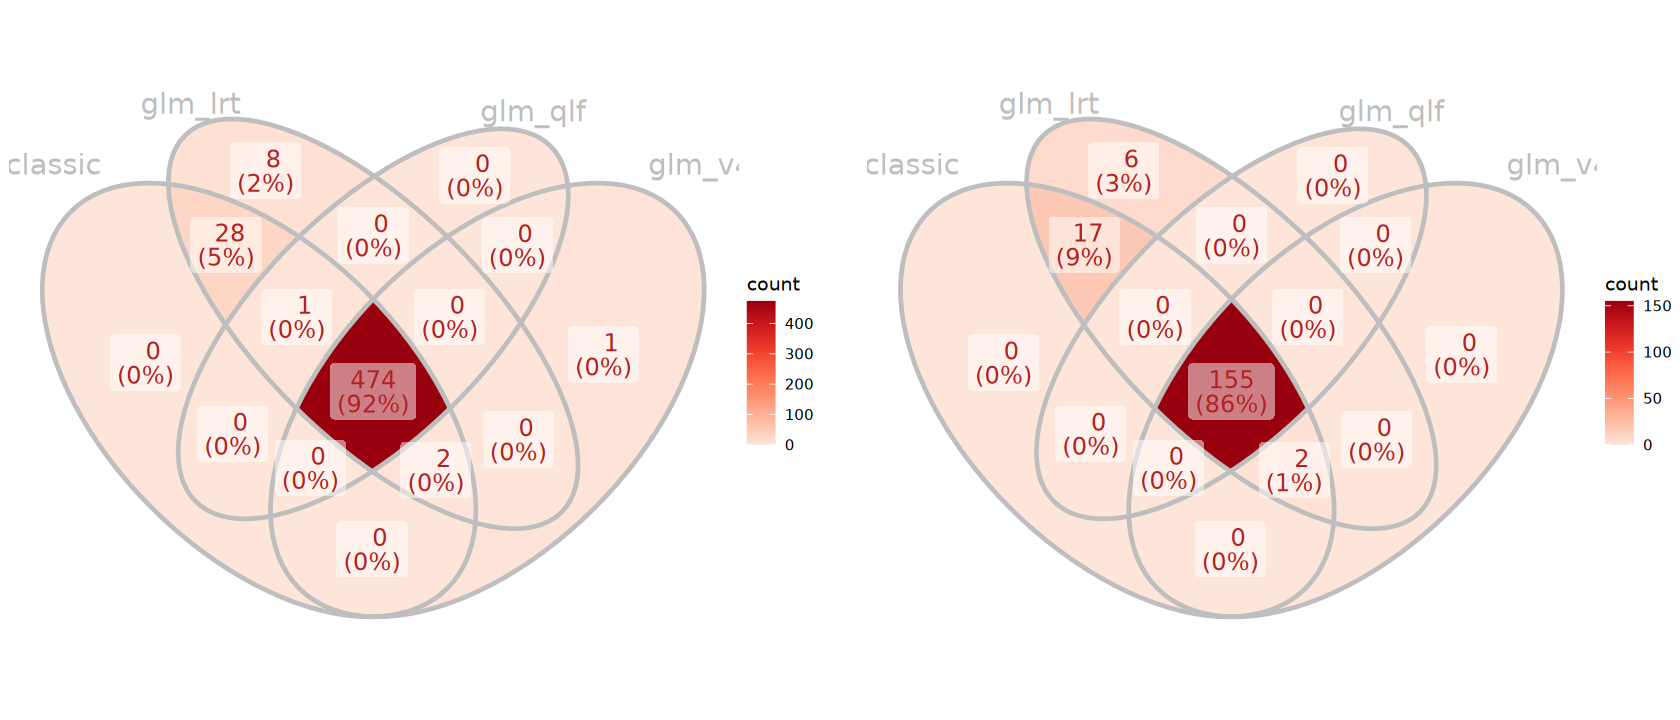

In [103]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

### a). limma-trend

> If the sequencing depth is fairly consistent across the RNA samples, then the simplest and most reliable method for differential expression is to use limma-trend. This method usually works well if the ratio of the largest library size to the smallest is no more than about 3-fold. Rarely used in practice.

In [104]:
design <- model.matrix(~group, data = dgel$samples)
design

,(Intercept),groupRA
LIF_rep1,1,0
LIF_rep2,1,0
LIF_rep3,1,0
RA_rep1,1,1
RA_rep2,1,1
RA_rep3,1,1


In [105]:
logCPM <- cpm(dgel, normalized.lib.sizes = TRUE, log = TRUE)
head(logCPM)

,LIF_rep1,LIF_rep2,LIF_rep3,RA_rep1,RA_rep2,RA_rep3
ENSMUSG00000103922.1,3.16623811,3.19202654,3.0868339,3.1815188,3.18708320,3.0182629
ENSMUSG00000033845.13,7.63250467,7.56894586,7.5168740,7.5944737,7.46919777,7.4611798
ENSMUSG00000102275.1,0.04280703,0.09237828,0.5885713,0.2014128,0.04694574,0.7312403
ENSMUSG00000025903.14,7.35346781,7.27726216,7.2260597,7.3303911,7.14882978,6.9723387
ENSMUSG00000033813.15,7.05108600,6.99860787,6.9594130,7.0992136,6.99073078,6.8676759
ENSMUSG00000002459.17,-1.87161531,-1.06647659,-0.9644396,-1.3549972,-0.27572613,0.2449973


In [106]:
# ---- limma-trend: for consistent library sizes ----
# Best when largest/smallest library ratio ≤ 3-fold.
fit <- lmFit(logCPM, design)
efit <- eBayes(fit, trend = TRUE)

In [107]:
# ---- Helper: Format limma results ----
# Convert limma eBayes output to standardized DEG table.
format_limma <- function(efit, coef, p_cutoff, logfc_cutoff, genes_df = NULL) {
    res <- topTable(efit, coef = coef, number = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
        mutate(
            result = case_when(
                is.na(padj) | !is.finite(logFC) ~ "Not_tested",
                padj < p_cutoff & logFC > logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ),
            result = factor(result, levels = c("Up", "Down", "NS", "Not_tested"))
        )
    if (!is.null(genes_df)) {
        res <- res |>
            left_join(genes_df |> rownames_to_column("gene_id"), by = "gene_id") |>
            column_to_rownames("gene_id")
    } else {
        res <- res |> column_to_rownames("gene_id")
    }
    res
}

In [108]:
limma_trend_result <- format_limma(efit, coef = 2, p_cutoff, logfc_cutoff, dgel$genes)

message(
    "limma-trend DEGs: ",
    sum(limma_trend_result$result == "Up"), " Up, ",
    sum(limma_trend_result$result == "Down"), " Down, ",
    sum(limma_trend_result$result == "NS"), " NS"
)
head(limma_trend_result)

limma-trend DEGs: 463 Up, 146 Down, 15921 NS



,logFC,AveExpr,t,pvalue,padj,B,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000024987.6,6.630516,2.928554,41.64747,4.557461e-14,7.533483e-10,21.17266,Up,Cyp26a1,protein_coding,1983
ENSMUSG00000030306.14,2.688062,4.647757,38.07344,1.290710e-13,1.066772e-09,20.47932,Up,Tmtc1,protein_coding,8578
ENSMUSG00000048490.14,2.554629,4.580398,29.97511,2.054010e-12,9.798532e-09,18.41712,Up,Nrip1,protein_coding,11457
ENSMUSG00000039047.17,1.951200,5.540657,29.60457,2.371091e-12,9.798532e-09,18.30213,Up,Pigk,protein_coding,9495
ENSMUSG00000029848.11,5.138127,3.153942,28.71790,3.367277e-12,1.113222e-08,18.01811,Up,Stra8,protein_coding,1803
ENSMUSG00000027359.16,-1.950531,5.292056,-24.46237,2.130922e-11,5.870690e-08,16.45749,Down,Slc27a2,protein_coding,3754


### b). limma-voom

> When library sizes vary significantly between samples, the voom approach is technically more powerful than limma-trend.

In [109]:
design <- model.matrix(~group, data = dgel$samples)

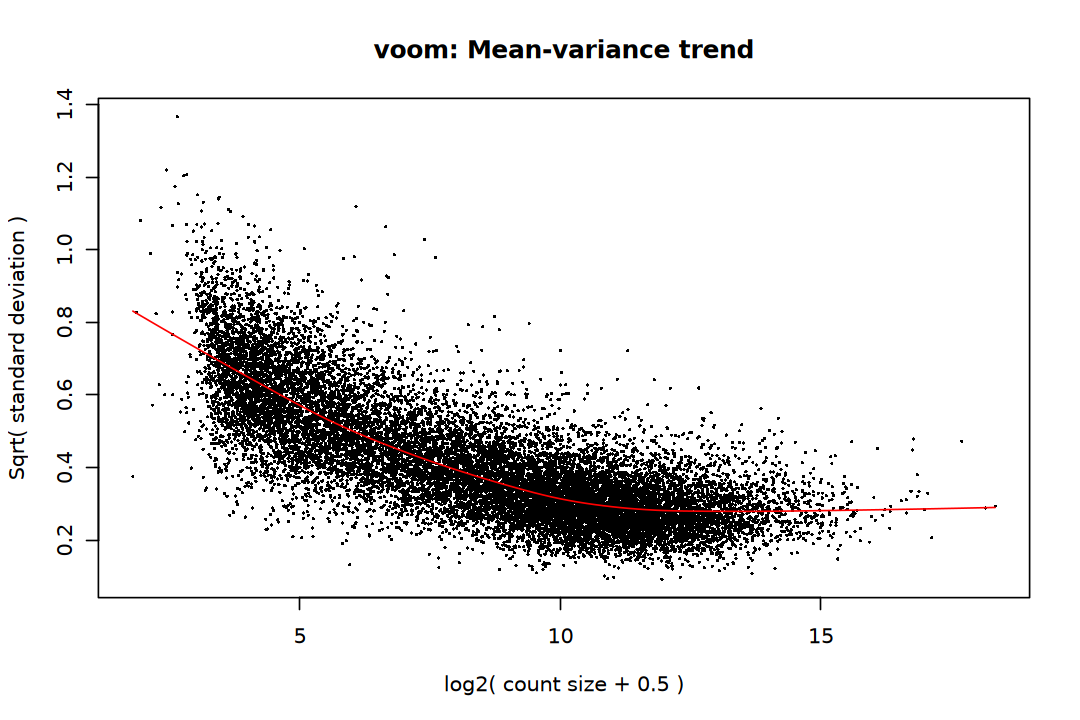

In [110]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [111]:
# ---- limma-voom: for varying library sizes ----
fit_voom <- lmFit(norm_v, design)
fit <- fit_voom
efit <- eBayes(fit)

In [112]:
limma_voom_result <- format_limma(efit, coef = 2, p_cutoff, logfc_cutoff)

message(
    "limma-voom DEGs: ",
    sum(limma_voom_result$result == "Up"), " Up, ",
    sum(limma_voom_result$result == "Down"), " Down, ",
    sum(limma_voom_result$result == "NS"), " NS"
)
head(limma_voom_result)

limma-voom DEGs: 473 Up, 153 Down, 15904 NS



,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000030306.14,Tmtc1,protein_coding,8578,2.693267,4.644104,33.85121,5.219670e-13,8.628115e-09,20.10816,Up
ENSMUSG00000039047.17,Pigk,protein_coding,9495,1.953183,5.539002,28.19598,4.296048e-12,2.367123e-08,18.34553,Up
ENSMUSG00000048490.14,Nrip1,protein_coding,11457,2.561299,4.576687,28.37730,3.990577e-12,2.367123e-08,18.28842,Up
ENSMUSG00000028435.8,Aqp3,protein_coding,1829,3.126183,5.207275,25.41003,1.419588e-11,4.693159e-08,17.14317,Up
ENSMUSG00000029848.11,Stra8,protein_coding,1803,5.185901,3.131476,27.44796,5.853012e-12,2.418757e-08,16.89208,Up
ENSMUSG00000027359.16,Slc27a2,protein_coding,3754,-1.952508,5.290120,-24.29211,2.377534e-11,6.550107e-08,16.65817,Down


### c). voomLmFit

> In recent versions of limma and edgeR, we now recommend voomLmFit as the preferred interface for RNA-seq analyses, replacing voom, lmFit, and voomWithQualityWeights. voomLmFit ensures unbiased estimation of the residual variances, even for genes that have no counts at all in some experimental conditions.
> - voomLmFit = voom transform + lmFit with weights

In [113]:
design <- model.matrix(~group, data = dgel$samples)

In [114]:
# ---- limma voomLmFit (recommended modern interface) ----
# Combines voom + lmFit with quality weights.
fit <- edgeR::voomLmFit(dgel, design = design, sample.weights = TRUE)
efit <- eBayes(fit)

First sample weights (min/max) 0.5590061/2.2533041



Final sample weights (min/max) 0.5576624/2.2487016



In [115]:
limma_voomLmFit_result <- format_limma(efit, coef = 2, p_cutoff, logfc_cutoff)

message(
    "limma voomLmFit DEGs: ",
    sum(limma_voomLmFit_result$result == "Up"), " Up, ",
    sum(limma_voomLmFit_result$result == "Down"), " Down, ",
    sum(limma_voomLmFit_result$result == "NS"), " NS"
)
head(limma_voomLmFit_result)

limma voomLmFit DEGs: 534 Up, 187 Down, 15809 NS



,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000030306.14,Tmtc1,protein_coding,8578,2.687272,4.644104,38.17767,1.845690e-14,3.050926e-10,23.34368,Up
ENSMUSG00000028435.8,Aqp3,protein_coding,1829,3.149514,5.207275,31.88837,1.765797e-13,1.106238e-09,21.37947,Up
ENSMUSG00000048490.14,Nrip1,protein_coding,11457,2.537393,4.576687,31.18007,2.339216e-13,1.106238e-09,21.06439,Up
ENSMUSG00000039047.17,Pigk,protein_coding,9495,1.922281,5.539002,30.84588,2.676923e-13,1.106238e-09,21.04699,Up
ENSMUSG00000029848.11,Stra8,protein_coding,1803,5.092283,3.131476,28.91701,6.001377e-13,1.984055e-09,19.28565,Up
ENSMUSG00000031383.8,Dusp9,protein_coding,2722,1.876173,7.290905,26.61726,1.687640e-12,3.985241e-09,19.19186,Up


### Evaluate DEGs

In [116]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [117]:
genes_up <- list(
    trend = limma_trend_result |> filter(result == "Up") |> rownames() |> unique(),
    voom = limma_voom_result |> filter(result == "Up") |> rownames() |> unique(),
    voomWeight = limma_voomLmFit_result |> filter(result == "Up") |> rownames() |> unique()
)

genes_down <- list(
    trend = limma_trend_result |> filter(result == "Down") |> rownames() |> unique(),
    voom = limma_voom_result |> filter(result == "Down") |> rownames() |> unique(),
    voomWeight = limma_voomLmFit_result |> filter(result == "Down") |> rownames() |> unique()
)

In [118]:
p1 <- ggVennDiagram(
    genes_up,
    set_color = "grey", set_size = 6,
    label_color = "firebrick", label_size = 5
) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down,
    set_color = "grey", set_size = 6,
    label_color = "firebrick", label_size = 5
) +
    scale_fill_distiller(palette = "Reds", direction = 1)

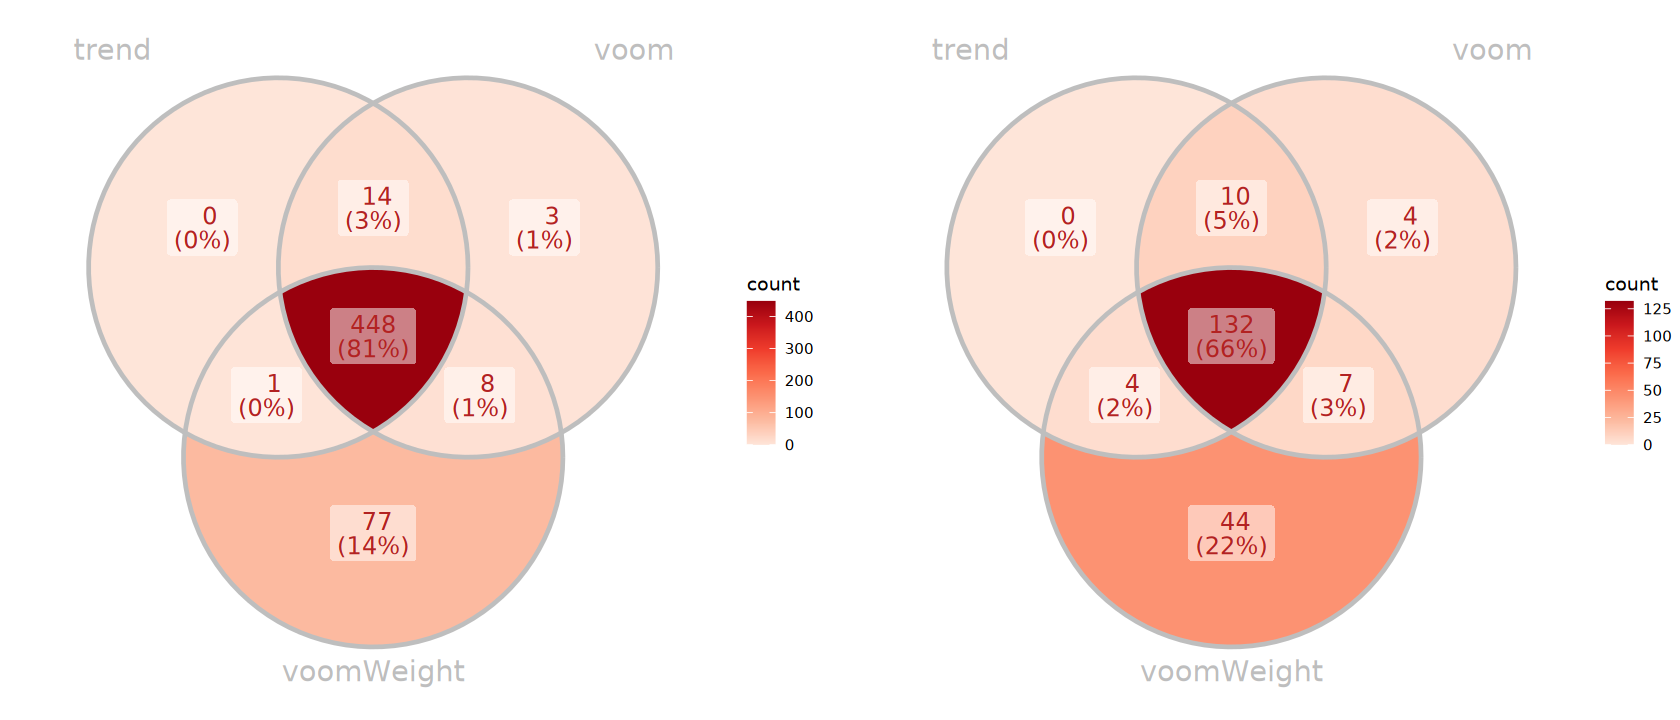

In [119]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Effect-threshold tests across methods

These tests target changes beyond |log2FC| = 1, unlike applying an observed fold-change cutoff after a zero-null test. Their statistical implementations differ; agreement is a sensitivity analysis on the same samples, not independent validation. DESeq2 is the primary analysis; edgeR v4 and limma-voom provide complementary evidence.

In [120]:
edger_treat <- glmTreat(fit_edger_qlf_v4, coef = "groupRA", lfc = logfc_cutoff)
edger_threshold_result <- format_edger(edger_treat, p_cutoff, logfc_cutoff)
limma_treat <- treat(fit_voom, lfc = logfc_cutoff)
limma_threshold_result <- topTreat(limma_treat, coef = "groupRA", number = Inf) |>
    as.data.frame() |>
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            is.na(padj) ~ "Not_tested",
            padj < p_cutoff & logFC > logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS"
        ),
        result = factor(result, levels = c("Up", "Down", "NS", "Not_tested"))
    )

In [121]:
ordinary_results <- list(
    DESeq2 = deseq2_zero_result, edgeR = edger_glm_qlf_v4_result,
    limma = limma_voom_result
)
threshold_results <- list(
    DESeq2 = deseq2_raw_result, edgeR = edger_threshold_result,
    limma = limma_threshold_result
)
de_summary <- bind_rows(lapply(c("ordinary", "threshold"), function(test) {
    collection <- if (test == "ordinary") ordinary_results else threshold_results
    bind_rows(lapply(names(collection), function(method) {
        as.data.frame(table(collection[[method]]$result)) |>
            setNames(c("status", "genes")) |>
            mutate(method = method, test = test)
    }))
}))
de_summary

status,genes,method,test
<fct>,<int>,<chr>,<chr>
Up,426,DESeq2,ordinary
Down,133,DESeq2,ordinary
NS,15971,DESeq2,ordinary
Not_tested,0,DESeq2,ordinary
Up,477,edgeR,ordinary
Down,157,edgeR,ordinary
NS,15896,edgeR,ordinary
Not_tested,0,edgeR,ordinary
Up,473,limma,ordinary


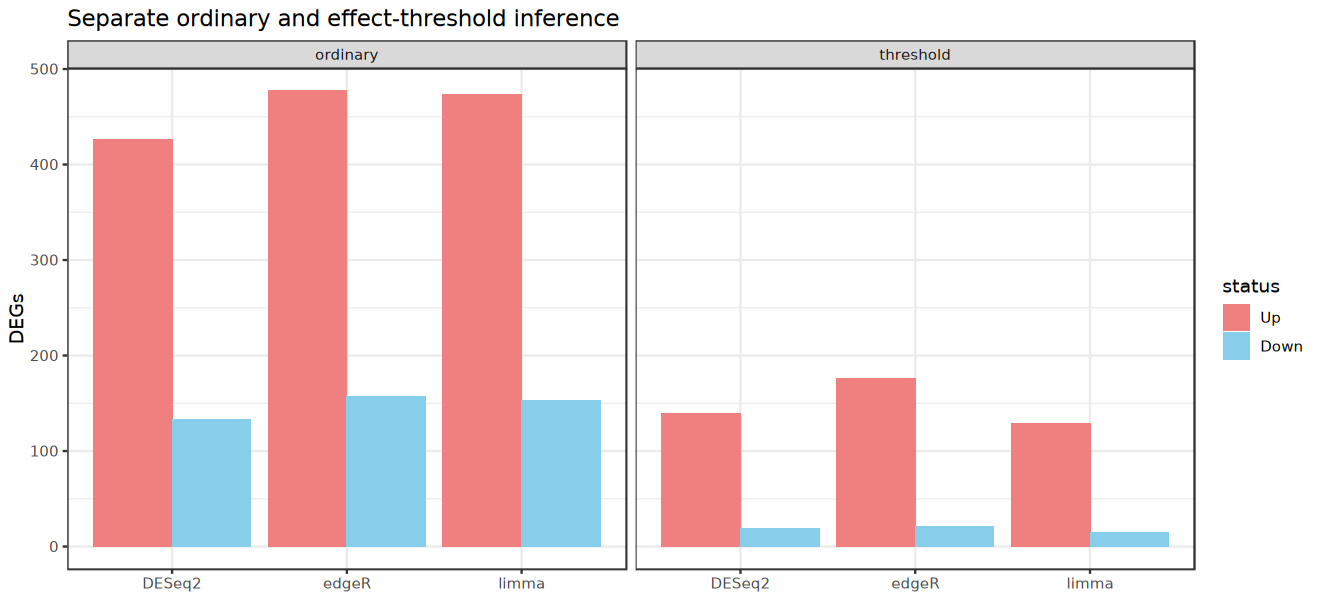

In [122]:
options(repr.plot.width = 11, repr.plot.height = 5)
ggplot(filter(de_summary, status %in% c("Up", "Down")), aes(method, genes, fill = status)) +
    geom_col(position = "dodge") +
    facet_wrap(~test) +
    theme_bw() +
    scale_fill_manual(values = c(Up = "LightCoral", Down = "SkyBlue")) +
    labs(x = NULL, y = "DEGs", title = "Separate ordinary and effect-threshold inference")

## DEGs Evaluation

Compare DESeq2, edgeR QL v4, and limma-voom using their effect-threshold results.
The correlation and agreement tables use genes with finite effects and available
adjusted P values in all three methods. Directional overlap plots use this same
eligible gene set.

In [123]:
# ---- Helper: Add top gene labels for visualization ----
# Annotate top-N DEGs (by significance & |logFC|) per direction with gene symbols.
add_label <- function(res, symbol_col = "symbol", n_labels = 5) {
    res |>
        rownames_to_column("gene_id") |>
        group_by(result) |>
        arrange(padj, desc(abs(logFC)), .by_group = TRUE) |>
        mutate(label = if_else(
            result %in% c("Up", "Down") & row_number() <= n_labels,
            .data[[symbol_col]], NA_character_
        )) |>
        ungroup() |>
        column_to_rownames("gene_id")
}

In [124]:
# Cross-method comparisons use threshold-test P values and unshrunken coefficients.
deseq2_result <- add_label(deseq2_raw_result)
edger_result <- add_label(edger_threshold_result)
limma_result <- add_label(limma_threshold_result)

In [125]:
# Restrict agreement calculations to genes eligible in every threshold-test table.
common_tested <- Reduce(intersect, lapply(threshold_results, function(x) {
    rownames(x)[is.finite(x$logFC) & !is.na(x$padj)]
}))
lfc_comparison <- data.frame(
    gene_id = common_tested,
    DESeq2 = deseq2_raw_result[common_tested, "logFC"],
    edgeR = edger_threshold_result[common_tested, "logFC"],
    limma = limma_threshold_result[common_tested, "logFC"]
)
print(cor(lfc_comparison[, -1], method = "spearman"))

          DESeq2     edgeR     limma
DESeq2 1.0000000 0.9999722 0.9931201
edgeR  0.9999722 1.0000000 0.9929367
limma  0.9931201 0.9929367 1.0000000


In [126]:
method_pairs <- combn(names(threshold_results), 2, simplify = FALSE)
concordance <- bind_rows(lapply(method_pairs, function(pair) {
    a <- threshold_results[[pair[1]]][common_tested, ]
    b <- threshold_results[[pair[2]]][common_tested, ]
    both <- a$result %in% c("Up", "Down") & b$result %in% c("Up", "Down")
    data.frame(
        method1 = pair[1], method2 = pair[2], common_tested = length(common_tested),
        spearman_logFC = cor(a$logFC, b$logFC, method = "spearman"),
        both_significant = sum(both),
        opposite_significant = sum(both & sign(a$logFC) != sign(b$logFC))
    )
}))
concordance

method1,method2,common_tested,spearman_logFC,both_significant,opposite_significant
<chr>,<chr>,<int>,<dbl>,<int>,<int>
DESeq2,edgeR,16530,0.9999722,158,0
DESeq2,limma,16530,0.9931201,137,0
edgeR,limma,16530,0.9929367,143,0


### Model diagnostics

Inspect fitted dispersions, quasi-likelihood moderation and Cook’s distances before interpreting gene-level results.

The plots show the DESeq2 dispersion fit and edgeR QL dispersions. The following
table summarizes maximum Cook's distances and missing test results. Its reference
cutoff flags genes for inspection; this diagnostic cell does not remove genes.

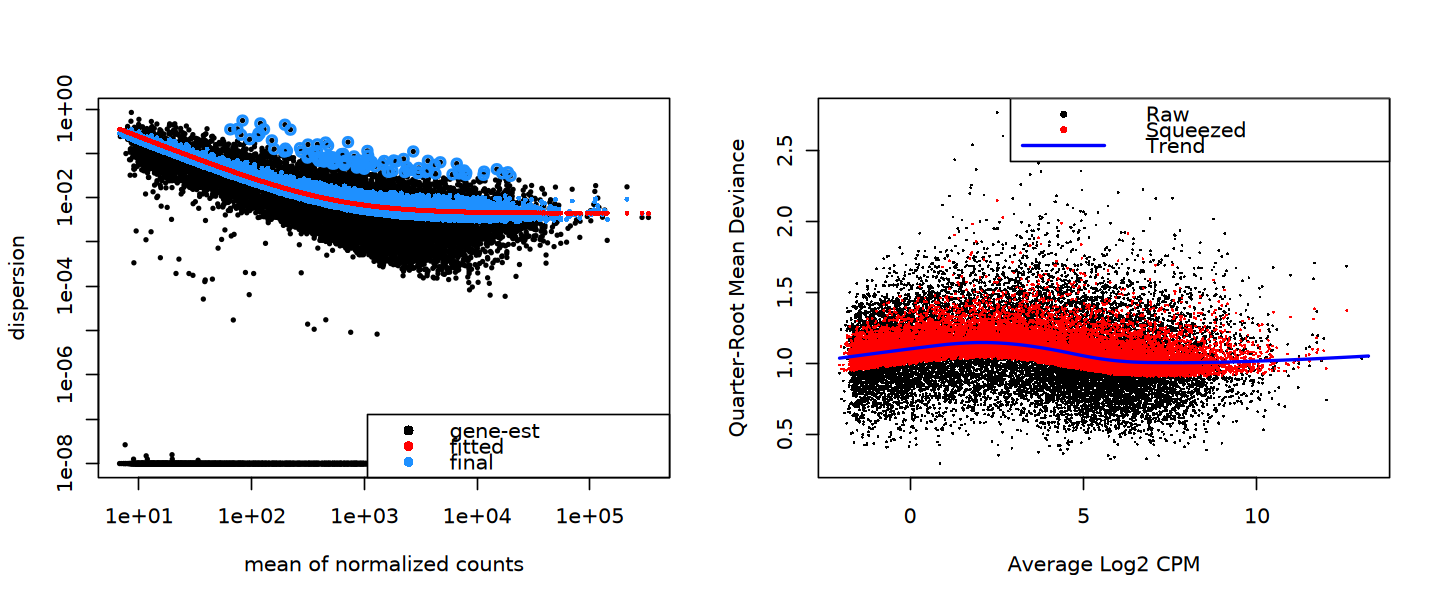

In [127]:
# Model diagnostics: inspect dispersion fit, QL moderation and count outliers.
options(repr.plot.width = 12, repr.plot.height = 5)
par(mfrow = c(1, 2))
plotDispEsts(dds)
plotQLDisp(fit_edger_qlf_v4)
par(mfrow = c(1, 1))

In [128]:
# Summarize influential observations for review without changing the fitted objects.
cooks <- assays(dds)[["cooks"]]
model_matrix <- model.matrix(design(dds), as.data.frame(colData(dds)))
n_coef <- ncol(model_matrix)
cooks_cutoff <- qf(0.99, n_coef, ncol(dds) - n_coef)
outlier_audit <- data.frame(
    gene_id = rownames(dds),
    max_cooks = apply(cooks,
        1,
        max,
        na.rm = TRUE
    ),
    threshold_pvalue_missing = is.na(res$pvalue), threshold_padj_missing = is.na(res$padj)
)
outlier_audit$cooks_above_reference <- outlier_audit$max_cooks > cooks_cutoff
table(outlier_audit$cooks_above_reference)


FALSE 
16530 

### P-value Histogram

This histogram uses the primary DESeq2 effect-threshold P values. Read it in the
context of that test definition and the model diagnostics.

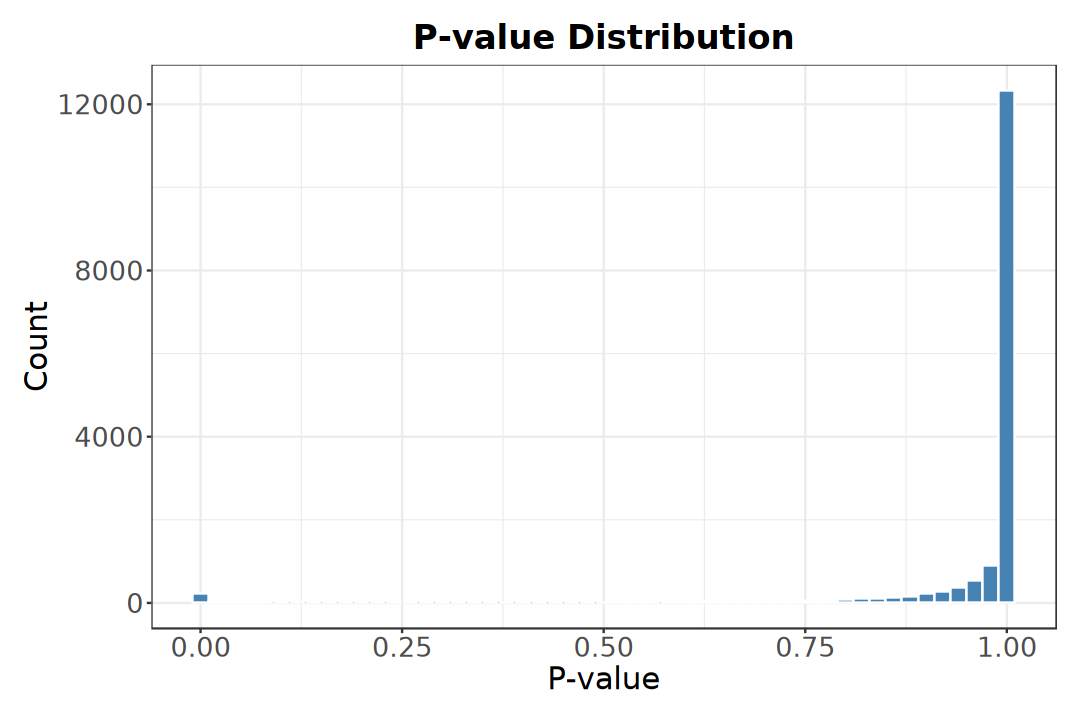

In [129]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deseq2_result, aes(x = pvalue)) +
    geom_histogram(binwidth = 0.02, fill = "steelblue", color = "white") +
    labs(
        title = "P-value Distribution",
        x = "P-value", y = "Count"
    ) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

Compare unshrunken log2 fold changes against each method's expression summary.
Colors identify DEG classes, and labels highlight selected significant genes.
The horizontal axes use different expression scales across methods.

In [130]:
# MA Plot: Visualize log2FC vs mean expression
#
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    x_vals <- if (log) log2(plot_df[[col]] + 1) else plot_df[[col]]
    max_logfc <- plot_df$logFC |>
        abs() |>
        max(na.rm = TRUE) |>
        ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray"
        ) +
        geom_text_repel(aes(label = label),
            color = "black", na.rm = TRUE, size = 6,
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf
        ) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(values = c(
            Up = "LightCoral",
            Down = "SkyBlue",
            NS = "gray",
            Not_tested = "grey85"
        )) +
        scale_size_manual(
            values = c(
                Up = 2,
                Down = 2,
                NS = 1,
                Not_tested = 0.5
            ),
            guide = "none"
        ) +
        guides(color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA Plot (", title, ")"), color = "DEG",
            x = "Mean Expression", y = "log2FC"
        ) +
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16)
        )
}

In [131]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

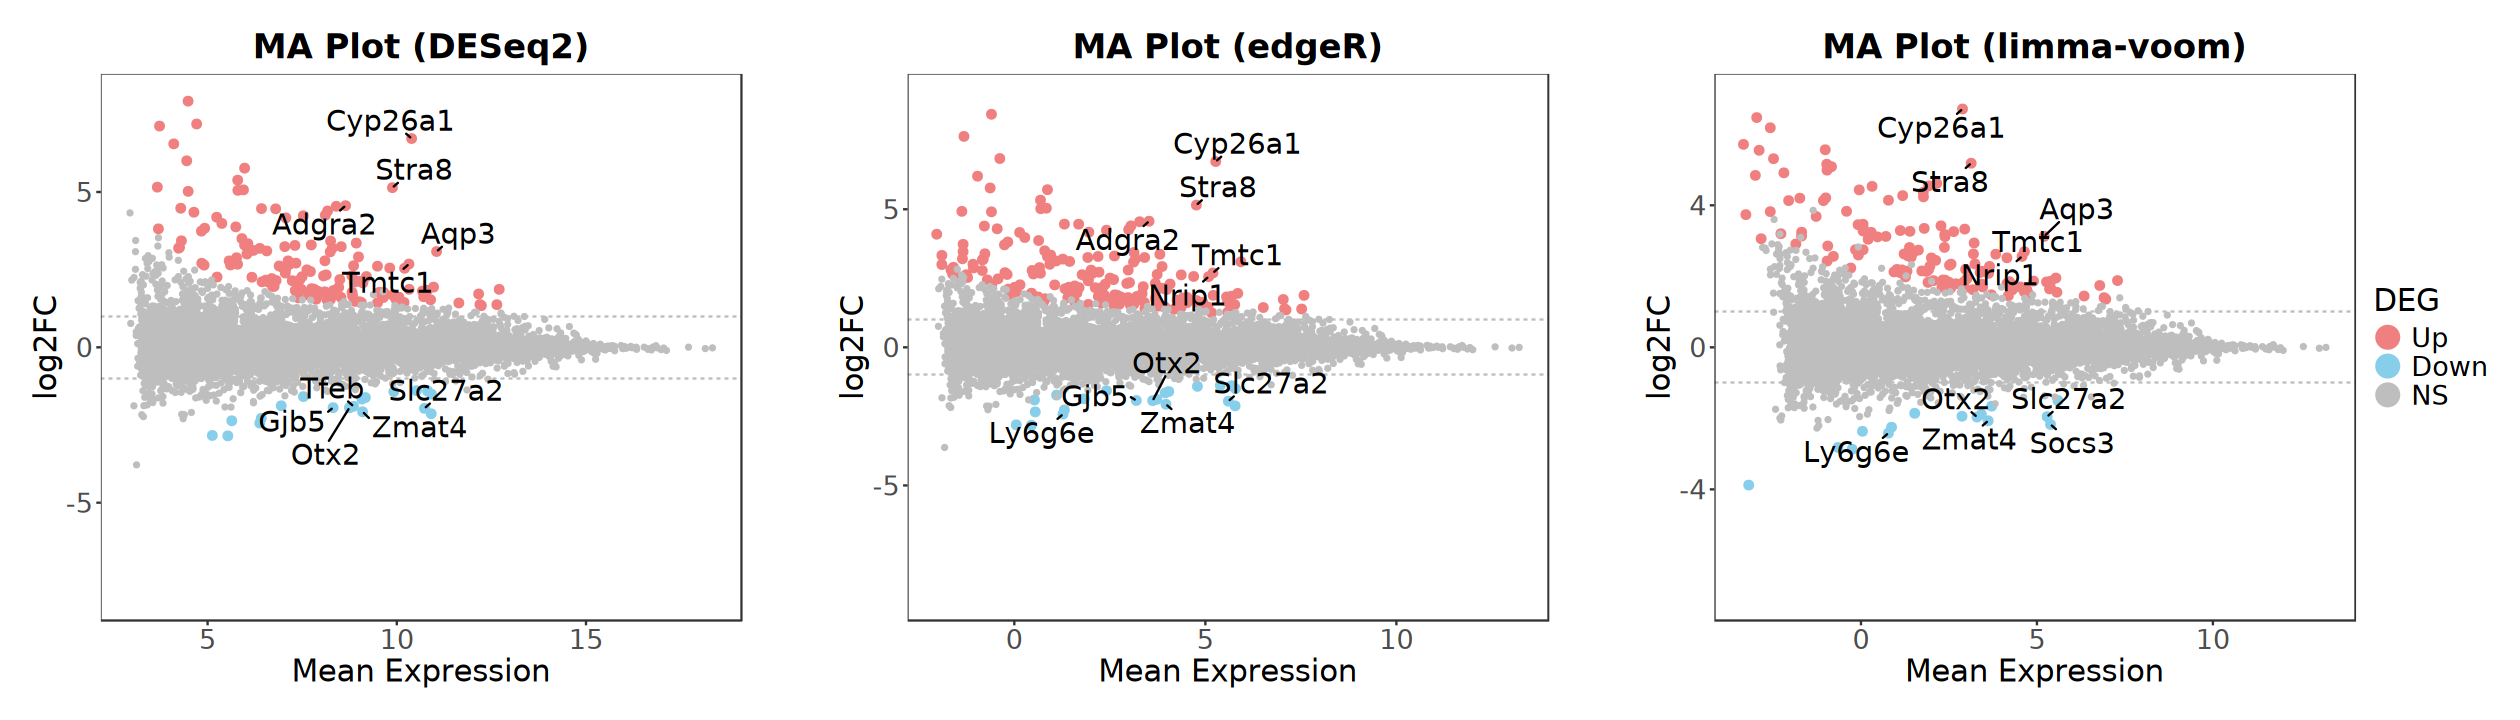

In [132]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect",
        widths = c(1, 0.05, 1, 0.05, 1)
    )

### Volcano

Plot unshrunken log2 fold changes against negative log10 adjusted P values from
the threshold tests. Dashed lines mark the configured cutoffs. The small numerical
floor used before taking logarithms keeps zero adjusted P values finite for plotting.

In [133]:
# Volcano Plot: Visualize log2FC vs statistical significance
#
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |>
        abs() |>
        max(na.rm = TRUE) |>
        ceiling()
    min_padj <- plot_df$padj |>
        pmax(1e-300) |>
        (\(x) -log10(x))() |>
        max(na.rm = TRUE) |>
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(yintercept = -log10(p_cutoff), linetype = "dashed", color = "gray") +
        geom_vline(
            xintercept = c(
                -logfc_cutoff,
                logfc_cutoff
            ),
            linetype = "dashed",
            color = "gray"
        ) +
        ggrepel::geom_text_repel(aes(label = label),
            color = "black", na.rm = TRUE, size = 4,
            min.segment.length = 0,
            segment.size = 0.5,
            max.overlaps = Inf
        ) +
        scale_x_continuous(expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) +
        scale_color_manual(values = c(
            Up = "LightCoral",
            Down = "SkyBlue",
            NS = "gray",
            Not_tested = "grey85"
        )) +
        scale_size_manual(
            values = c(
                Up = 2,
                Down = 2,
                NS = 1,
                Not_tested = 0.5
            ),
            guide = "none"
        ) +
        labs(
            title = paste0("Volcano Plot (", title, ")"), color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))
        ) +
        guides(color = guide_legend(override.aes = list(size = 6))) +
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16)
        )
}

In [134]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

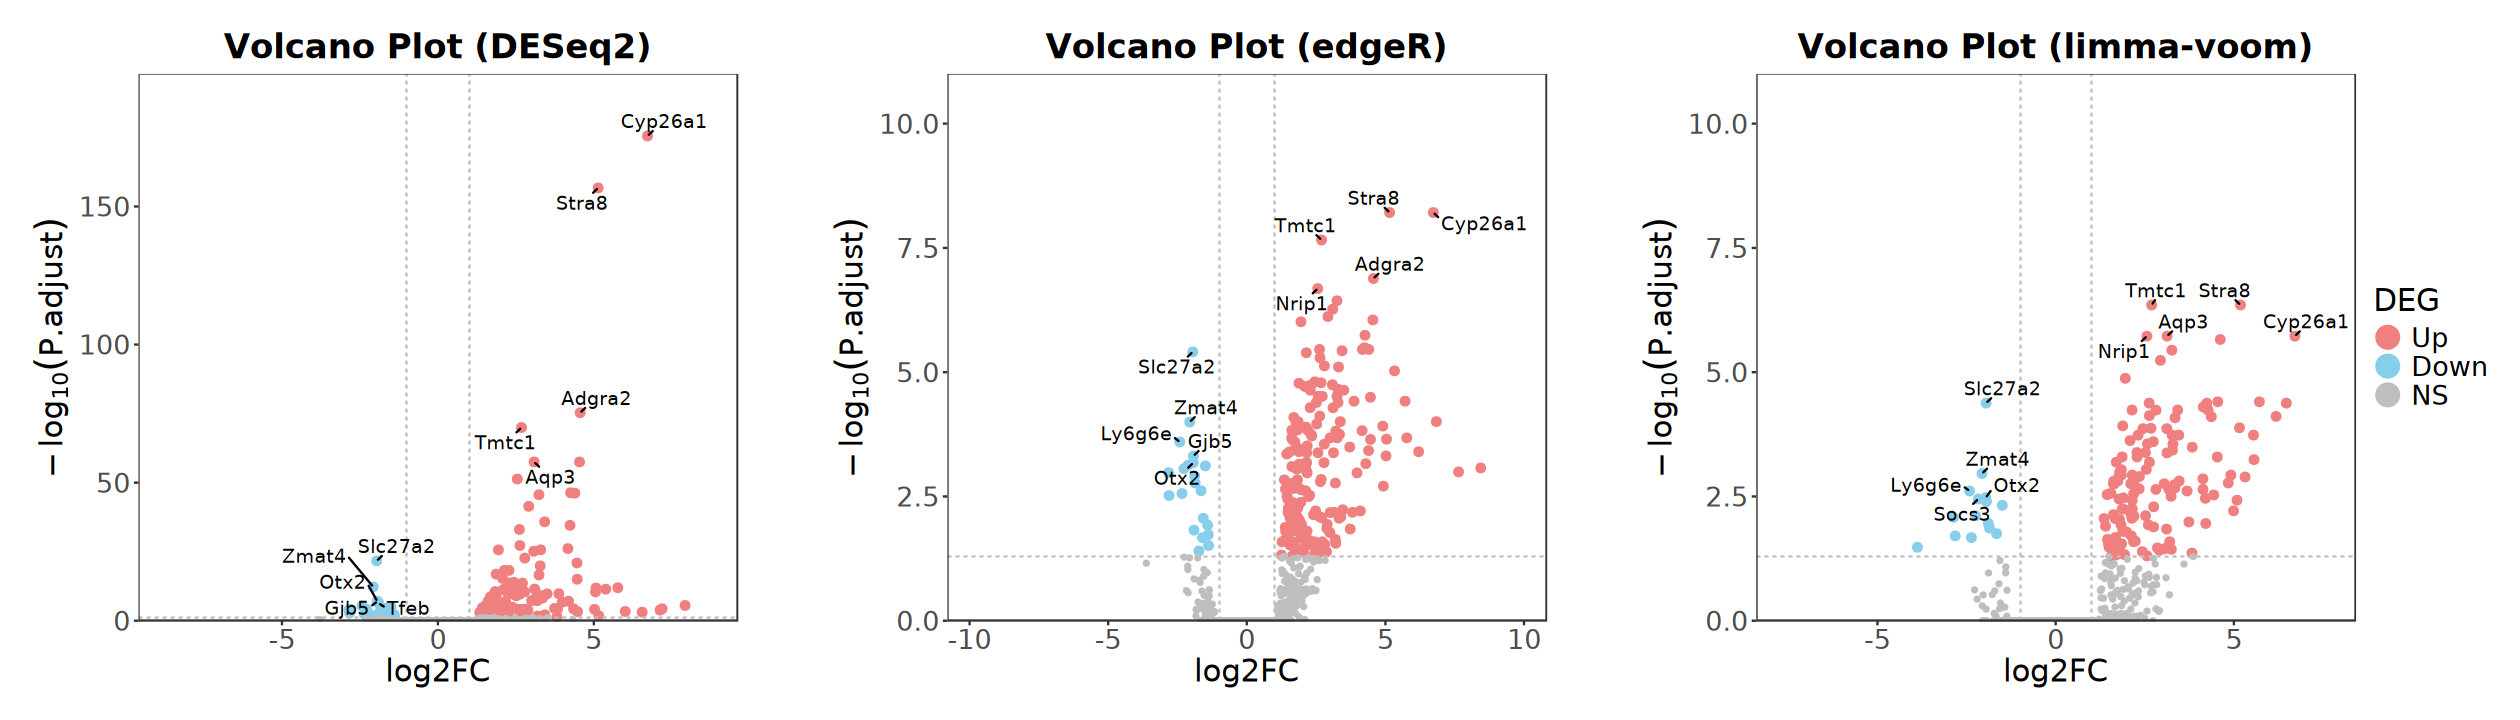

In [135]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect",
        widths = c(1, 0.05, 1, 0.05, 1)
    )

### Venn

In [136]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [137]:
genes_up <- list(
    DESeq2 = deseq2_result |> filter(result == "Up") |>
        rownames() |> unique(),
    edgeR = edger_result |> filter(result == "Up") |>
        rownames() |> unique(),
    limma = limma_result |> filter(result == "Up") |>
        rownames() |> unique()
)

genes_down <- list(
    DESeq2 = deseq2_result |> filter(result == "Down") |>
        rownames() |> unique(),
    edgeR = edger_result |> filter(result == "Down") |>
        rownames() |> unique(),
    limma = limma_result |> filter(result == "Down") |>
        rownames() |> unique()
)

In [138]:
genes_up <- lapply(genes_up, intersect, y = common_tested)
genes_down <- lapply(genes_down, intersect, y = common_tested)

In [139]:
p1 <- ggVennDiagram(
    genes_up,
    set_color = "grey", set_size = 6,
    label_color = "firebrick", label_size = 5
) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down,
    set_color = "grey", set_size = 6,
    label_color = "firebrick", label_size = 5
) +
    scale_fill_distiller(palette = "Reds", direction = 1)

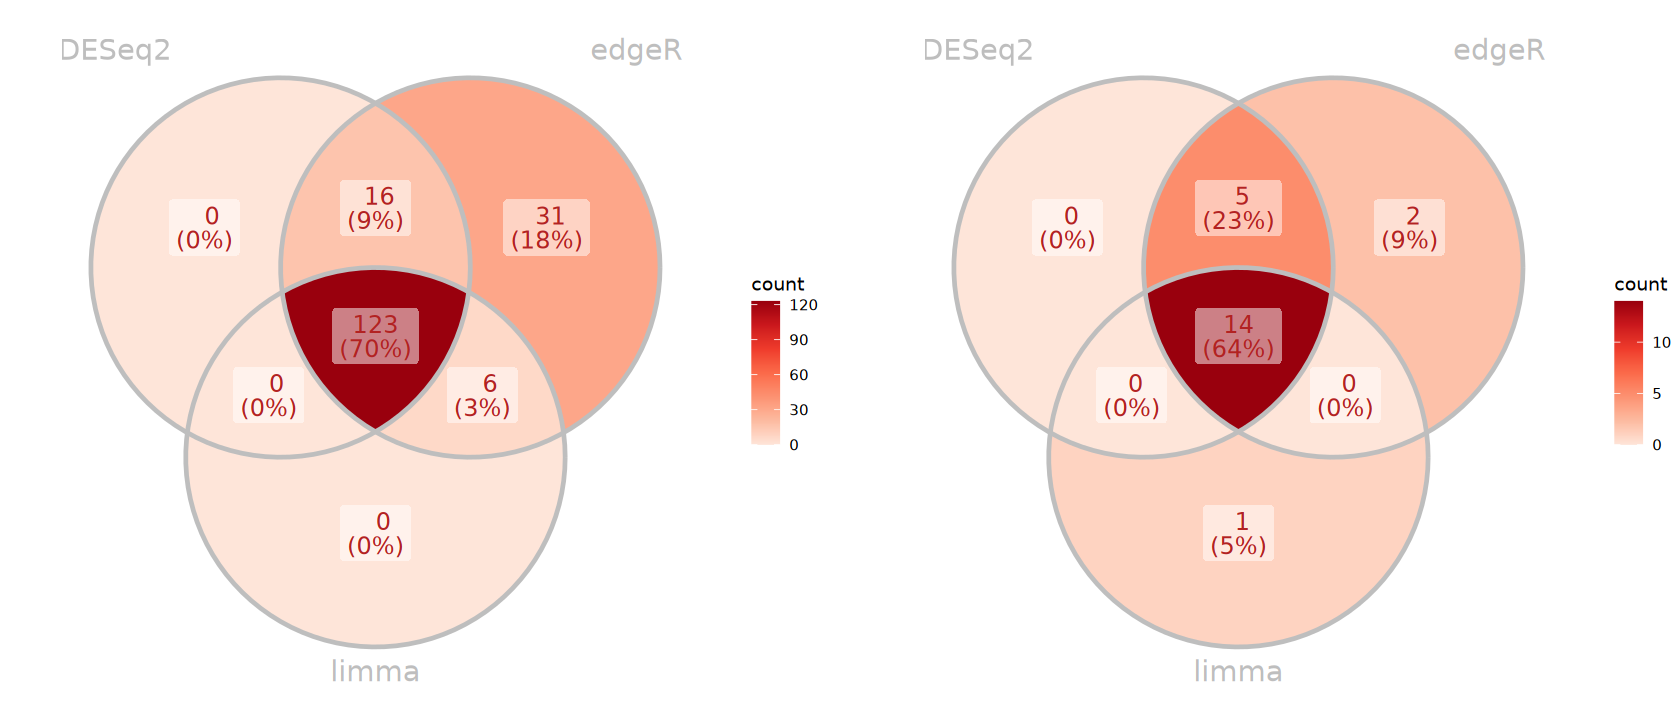

In [140]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Upset

Show intersections among the same directional gene sets used in the Venn plots.
Upregulated and downregulated genes are displayed separately.

In [141]:
suppressPackageStartupMessages(library(UpSetR))

Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>."


Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>."


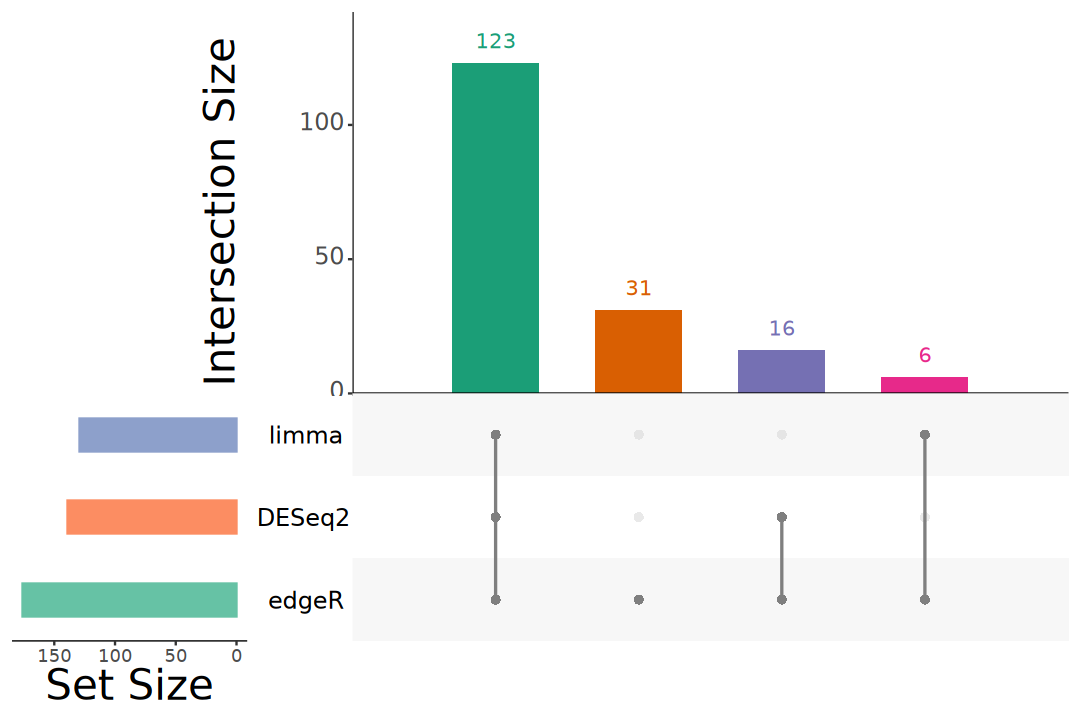

In [142]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up),
    mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 4, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2)
)

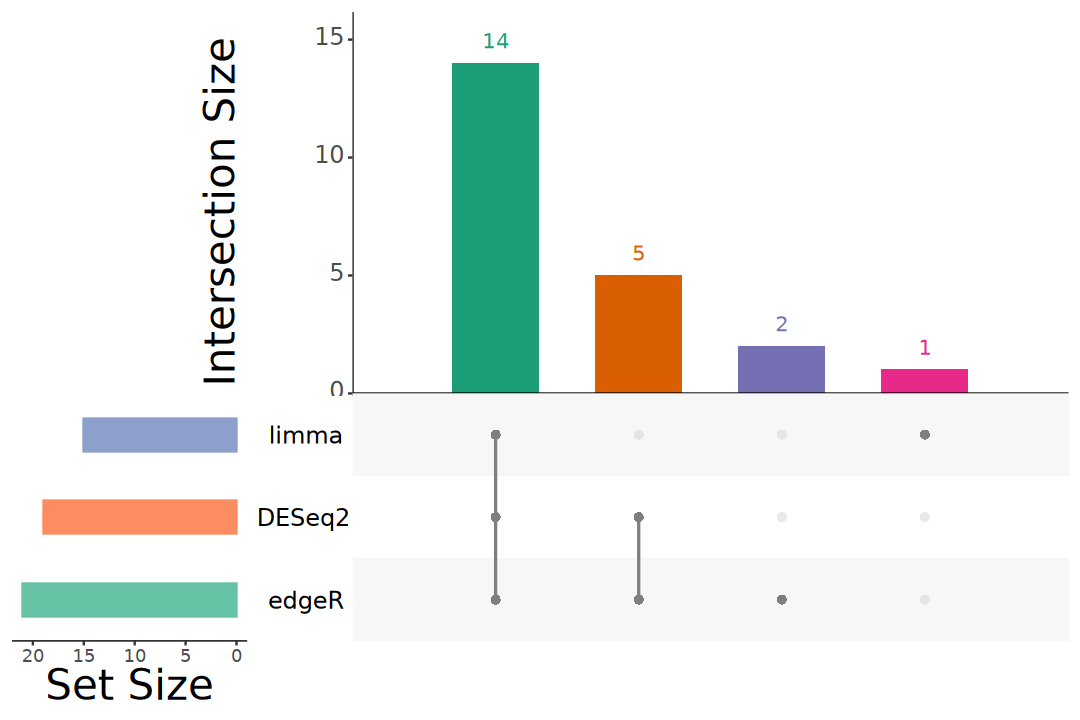

In [143]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down),
    mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 4, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2)
)

## DEGs Visualization

Single-method plots use shrunken DESeq2 coefficients with **unchanged primary threshold-test labels/P values**. A label may therefore not coincide with a cutoff on the shrunken axis. Cross-method plots above use MLE coefficients. Heatmaps use rlog expression and row z-scores.

In [144]:
# Reuse the fitted shrinkage result; avoid recomputation and default-result drift.
stopifnot(identical(deseq2_lfc_result$padj, deseq2_raw_result$padj))

In [145]:
degs_result <- add_label(deseq2_lfc_result)
table(degs_result$result)
head(degs_result)


        Up       Down         NS Not_tested 
       139         19      16372          0 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs,stat_zero,test_status,logFC_MLE,logFC_shrunk,posteriorSD,label
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>
ENSMUSG00000024987.6,1341.8434,6.709281,0.19987753,33.62503,1.790438e-180,2.959594e-176,Up,Cyp26a1,protein_coding,1983,33.62503,tested,6.720888,6.709281,0.19965077,Cyp26a1
ENSMUSG00000029848.11,944.6106,5.130545,0.15305657,33.57856,2.185063e-161,1.805955e-157,Up,Stra8,protein_coding,1803,33.57856,tested,5.139419,5.130545,0.15311272,Stra8
ENSMUSG00000031486.15,399.6966,4.544954,0.18860762,24.17819,8.954897e-80,4.934148e-76,Up,Adgra2,protein_coding,5775,24.17819,tested,4.560190,4.544954,0.18851289,Adgra2
ENSMUSG00000030306.14,1278.2639,2.675123,0.09237637,29.02600,2.546470e-74,1.052329e-70,Up,Tmtc1,protein_coding,8578,29.02600,tested,2.681317,2.675123,0.09247211,Tmtc1
ENSMUSG00000028435.8,2121.8323,3.073601,0.12596336,24.48034,9.215741e-62,3.046724e-58,Up,Aqp3,protein_coding,1829,24.48034,tested,3.083625,3.073601,0.12617201,Aqp3
ENSMUSG00000079173.11,336.5082,4.520576,0.21420665,21.19551,1.170288e-61,3.224143e-58,Up,Zan,protein_coding,19813,21.19551,tested,4.540219,4.520576,0.21420912,NA


In [146]:
max_logfc <- degs_result$logFC |>
    abs() |>
    max(na.rm = TRUE) |>
    ceiling()

min_padj <- degs_result$padj |>
    pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

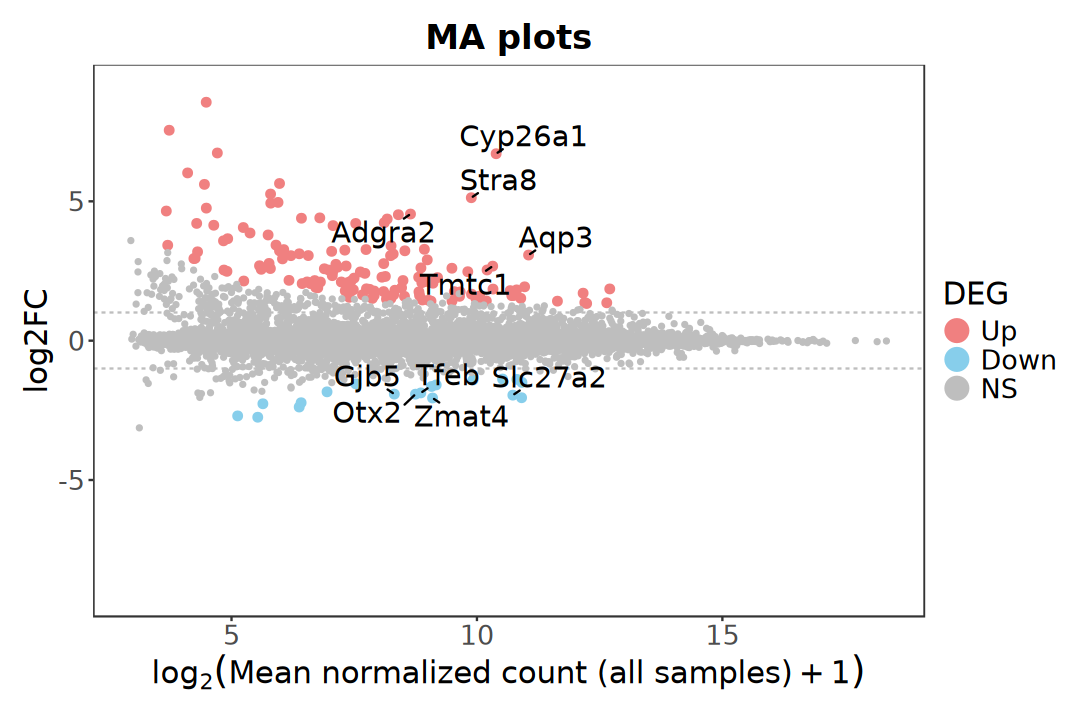

In [147]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(degs_result, aes(x = log2(baseMean + 1), y = logFC)) +
    geom_point(
        aes(color = result, size = result),
        na.rm = TRUE
    ) +
    geom_hline(
        yintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray"
    ) +
    geom_text_repel(
        aes(label = label),
        color = "black", na.rm = TRUE, size = 6,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf
    ) +
    scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray", Not_tested = "grey85")
    ) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1, Not_tested = 0.5), guide = "none"
    ) +
    guides(
        color = guide_legend(override.aes = list(size = 6))
    ) +
    labs(
        title = "MA plots", color = "DEG",
        x = expression(log[2]("Mean normalized count (all samples)" + 1)),
        y = "log2FC"
    ) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

### Volcano

In [148]:
p1 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = result, size = result),
        na.rm = TRUE
    ) +
    geom_hline(
        yintercept = -log10(p_cutoff),
        linetype = "dashed", color = "gray"
    ) +
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray"
    ) +
    geom_text_repel(
        aes(label = label),
        color = "black", na.rm = TRUE, size = 6,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf
    ) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)
    ) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)
    ) +
    scale_color_manual(
        values = c(
            Up = "LightCoral", Down = "SkyBlue", NS = "gray", Not_tested = "grey85"
        )
    ) +
    scale_size_manual(
        values = c(
            Up = 2, Down = 2, NS = 1, Not_tested = 0.5
        ), guide = "none"
    ) +
    guides(
        color = guide_legend(override.aes = list(size = 6))
    ) +
    labs(
        title = "Volcano Plot (Standard)", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))
    ) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

In [149]:
p2 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = logFC, size = abs(logFC)),
        na.rm = TRUE
    ) +
    geom_hline(
        yintercept = -log10(p_cutoff),
        linetype = "dashed", color = "gray"
    ) +
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray"
    ) +
    geom_text_repel(
        aes(label = label),
        color = "black", na.rm = TRUE, size = 6,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf
    ) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)
    ) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)
    ) +
    scale_color_gradientn(
        colours = brewer.pal(11, "RdYlBu") |> rev(),
        limits = c(-max_logfc, max_logfc)
    ) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano Plot (logFC-colored)",
        x = "log2FC", y = expression(-log[10](P.adjust))
    ) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

In [150]:
p3 <- degs_result |>
    mutate(
        neglog10_padj = -log10(pmax(padj, 1e-300)),
        neglog10_padj_m = ifelse(
            logFC < 0, -neglog10_padj, neglog10_padj
        )
    ) |>
    ggplot(aes(x = logFC, y = neglog10_padj)) +
    geom_point(
        aes(color = neglog10_padj_m, size = neglog10_padj),
        na.rm = TRUE
    ) +
    geom_hline(
        yintercept = -log10(p_cutoff),
        linetype = "dashed", color = "gray"
    ) +
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray"
    ) +
    geom_text_repel(
        aes(label = label),
        color = "black", na.rm = TRUE, size = 6,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf
    ) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)
    ) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)
    ) +
    scale_color_gradientn(
        name = expression(-log[10](P.adjust)),
        colours = brewer.pal(11, "RdBu") |> rev(),
        limits = c(-min_padj, min_padj),
        breaks = c(-min_padj, 0, min_padj),
        labels = c(min_padj, 0, min_padj)
    ) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano Plot (bidirectional color)", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))
    ) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

In [151]:
p4 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = -log10(pmax(padj, 1e-300)), size = -log10(pmax(padj, 1e-300))),
        na.rm = TRUE, alpha = 0.8
    ) +
    geom_hline(
        yintercept = -log10(p_cutoff),
        linetype = "dashed", color = "gray"
    ) +
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray"
    ) +
    geom_text_repel(
        aes(label = label),
        color = "black", na.rm = TRUE, size = 6,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf
    ) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)
    ) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)
    ) +
    # scale_color_viridis_c(
    #     option = "turbo", begin = 0.1, end = 0.9) +
    # scale_color_gradientn(
    #     colours = brewer.pal(11, 'RdYlBu') |> rev())+
    # scale_color_gradientn(
    #     colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25")) +
    scale_color_gradientn(
        colors = c(
            "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4",
            "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61",
            "#F46D43", "#D53E4F", "#9C2007", "#9E0142"
        )
    ) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano Plot (pvalue-colored)",
        color = expression(-log[10](P.adjust)),
        x = "log2FC", y = expression(-log[10](P.adjust))
    ) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

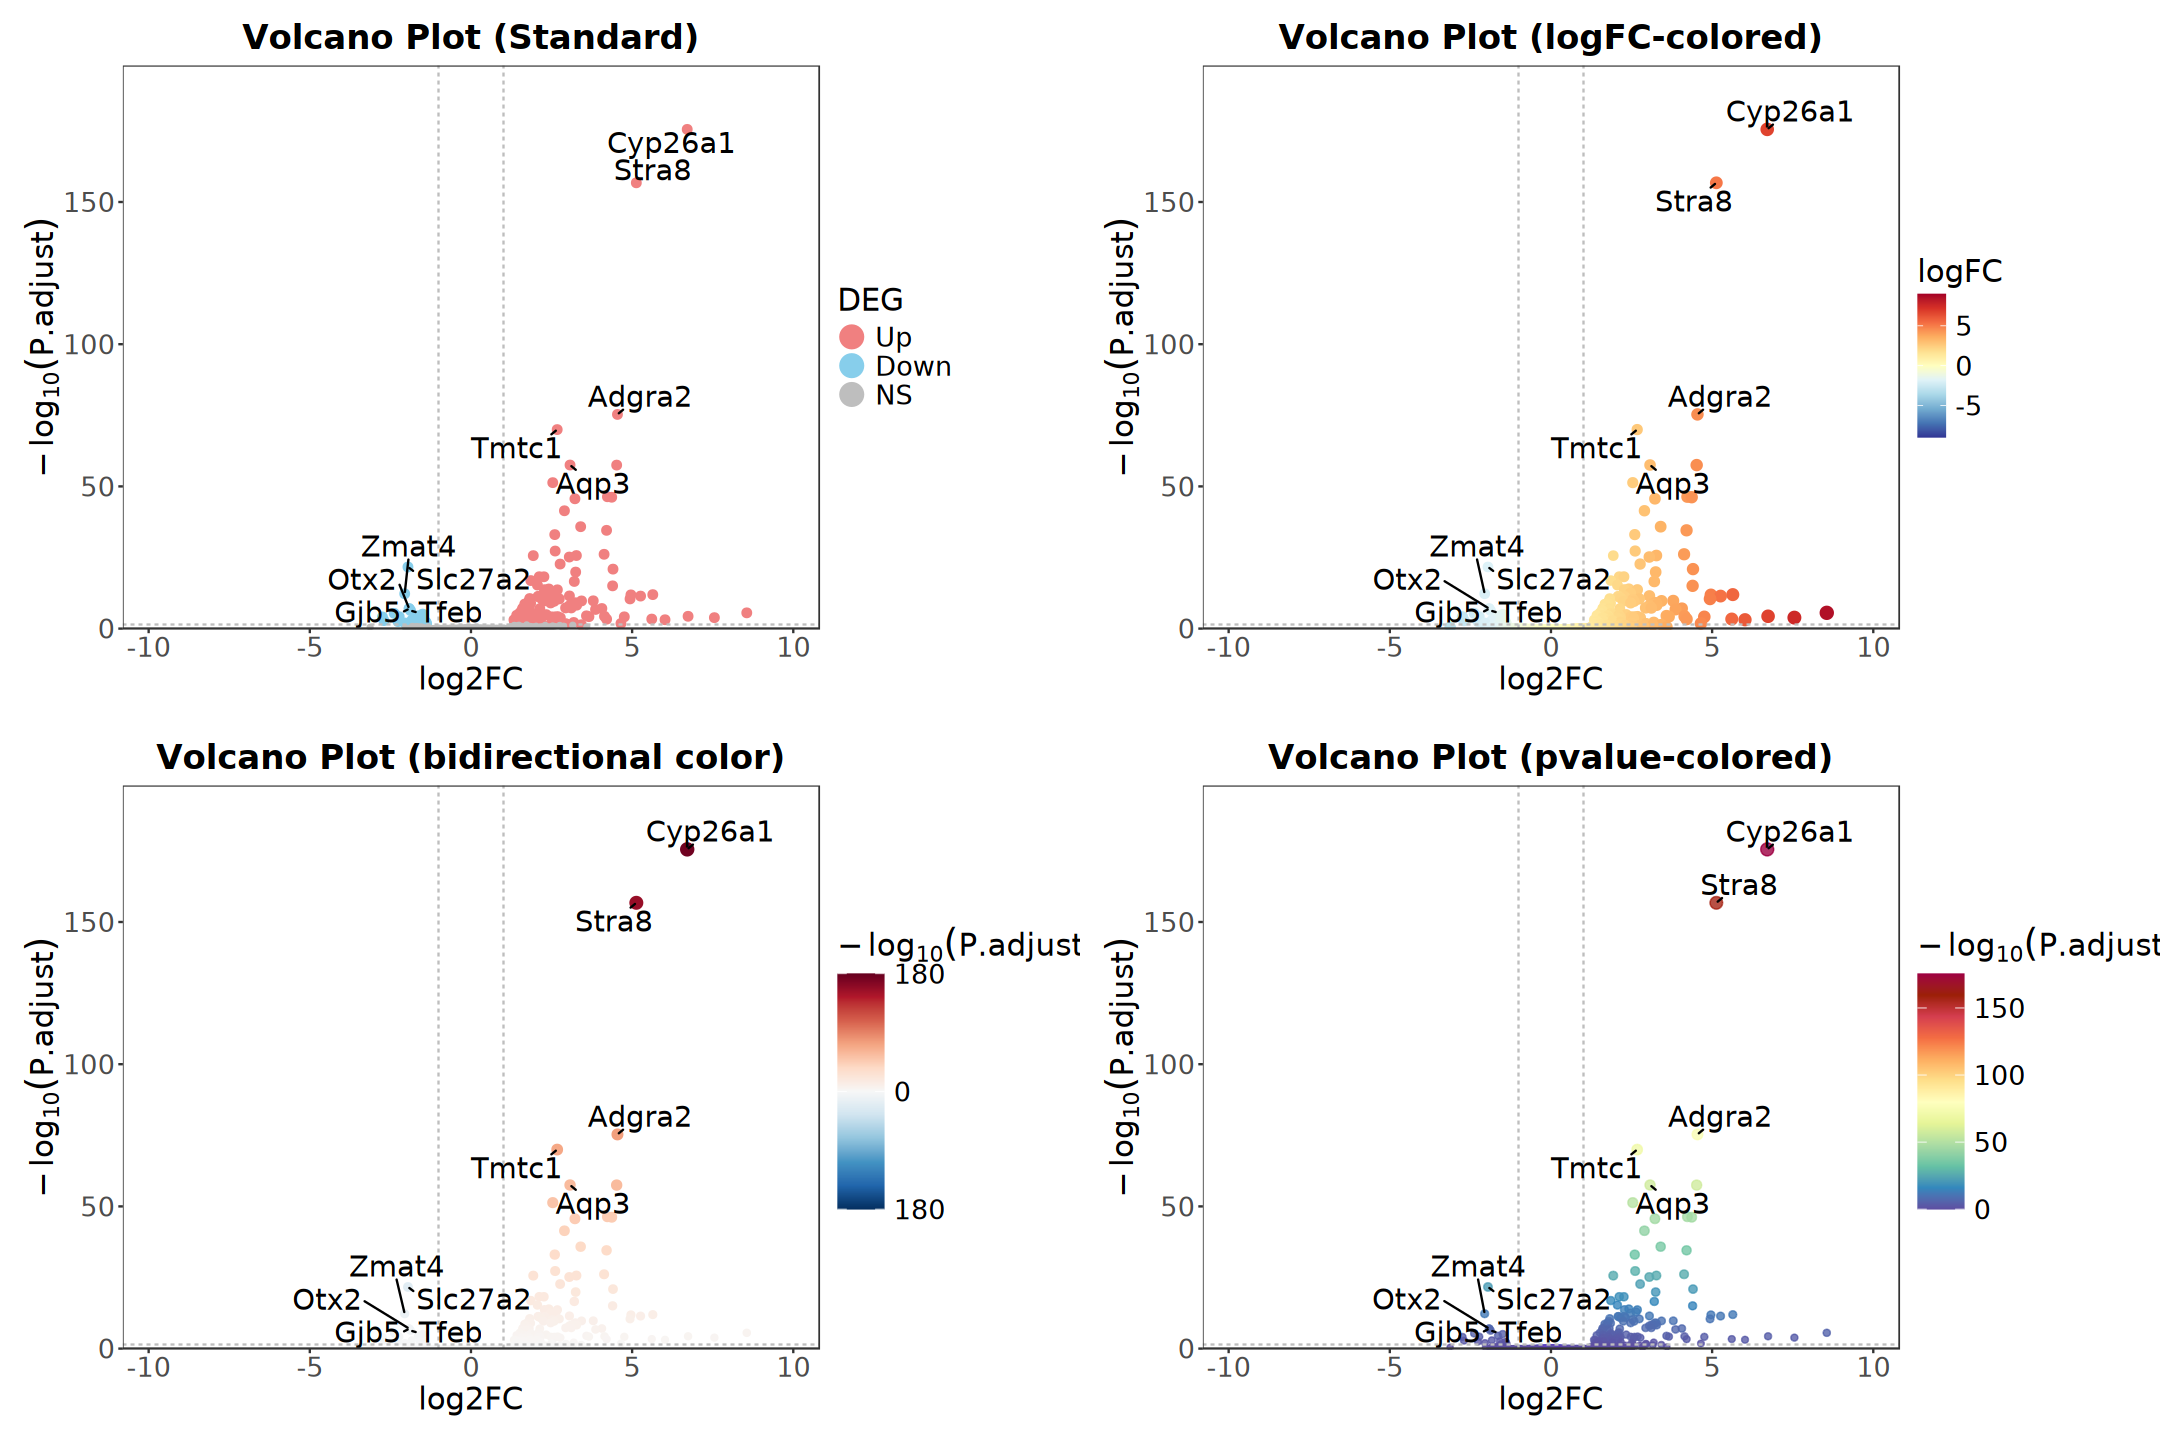

In [152]:
options(repr.plot.width = 18, repr.plot.height = 12)
cowplot::plot_grid(
    p1, p2, p3, p4,
    nrow = 2, align = "hv", axis = "tblr"
)

### Scatter Plot

In [153]:
ctrl_samples <- colnames(dds)[dds$Group == "LIF"]
treat_samples <- colnames(dds)[dds$Group == "RA"]

mean_expr <- dds |>
    counts(normalized = TRUE) |>
    as.data.frame() |>
    rownames_to_column(var = "gene_id") |>
    mutate(
        Ctrl_Mean = rowMeans(across(all_of(ctrl_samples))),
        Treat_Mean = rowMeans(across(all_of(treat_samples)))
    ) |>
    dplyr::select(gene_id, Ctrl_Mean, Treat_Mean)

In [154]:
plot_df <- degs_result |>
    rownames_to_column(var = "gene_id") |>
    inner_join(mean_expr, by = "gene_id") |>
    mutate(
        log2_Ctrl = log2(Ctrl_Mean + 1),
        log2_Treat = log2(Treat_Mean + 1)
    ) |>
    drop_na(log2_Ctrl, log2_Treat)

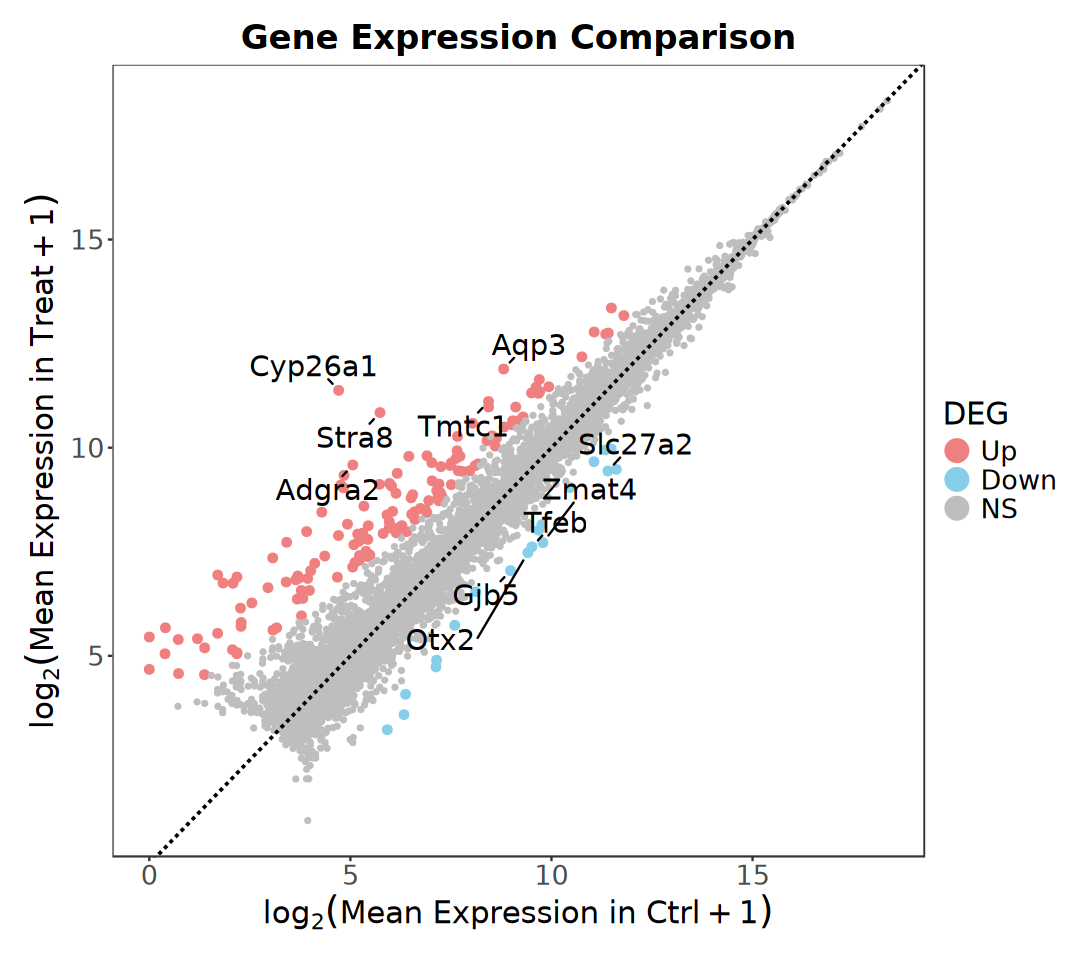

In [155]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = log2_Ctrl, y = log2_Treat)) +
    geom_point(
        aes(color = result, size = result),
        na.rm = TRUE
    ) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed",
        color = "black", linewidth = 0.8
    ) +
    geom_text_repel(
        aes(label = label),
        color = "black", na.rm = TRUE, size = 6,
        box.padding = 0.5, point.padding = 0.3,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf
    ) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray", Not_tested = "grey85")
    ) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1, Not_tested = 0.5), guide = "none"
    ) +
    guides(
        color = guide_legend(override.aes = list(size = 6))
    ) +
    labs(
        title = "Gene Expression Comparison", color = "DEG",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = expression(log[2]("Mean Expression in Treat" + 1))
    ) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16)
    )

### Heatmap

Select genes labeled `Up` or `Down`, retrieve their rlog expression, and exclude
rows with zero variance before scaling. Gene labels and row annotations are
matched to the displayed gene IDs. Clustering is skipped if fewer than two
variable DEGs remain.

In [156]:
# Use primary DEG labels to choose rows, then remove constant expression profiles.
# The same matrix is reused by pheatmap and ComplexHeatmap.
heatmap_ids <- rownames(degs_result)[degs_result$result %in% c("Up", "Down")]
heatmap_dat <- norm_vs[heatmap_ids, , drop = FALSE]
if (nrow(heatmap_dat)) {
    heatmap_dat <- heatmap_dat[matrixStats::rowSds(heatmap_dat) > 0, ,
        drop = FALSE
    ]
}
heatmap_ready <- nrow(heatmap_dat) >= 2
if (!heatmap_ready) message("Fewer than two variable DEGs; skip clustered DEG heatmaps.")

In [157]:
ar <- degs_result |>
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |>
    as.data.frame() |>
    dplyr::select(Replicate, Group)

In [158]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group)
)
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate)
)
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey", Not_tested = "grey85")

anno_colors <- list(
    Group = group_colors, Replicate = replicate_colors, DEG = deg_colors,
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev()
)

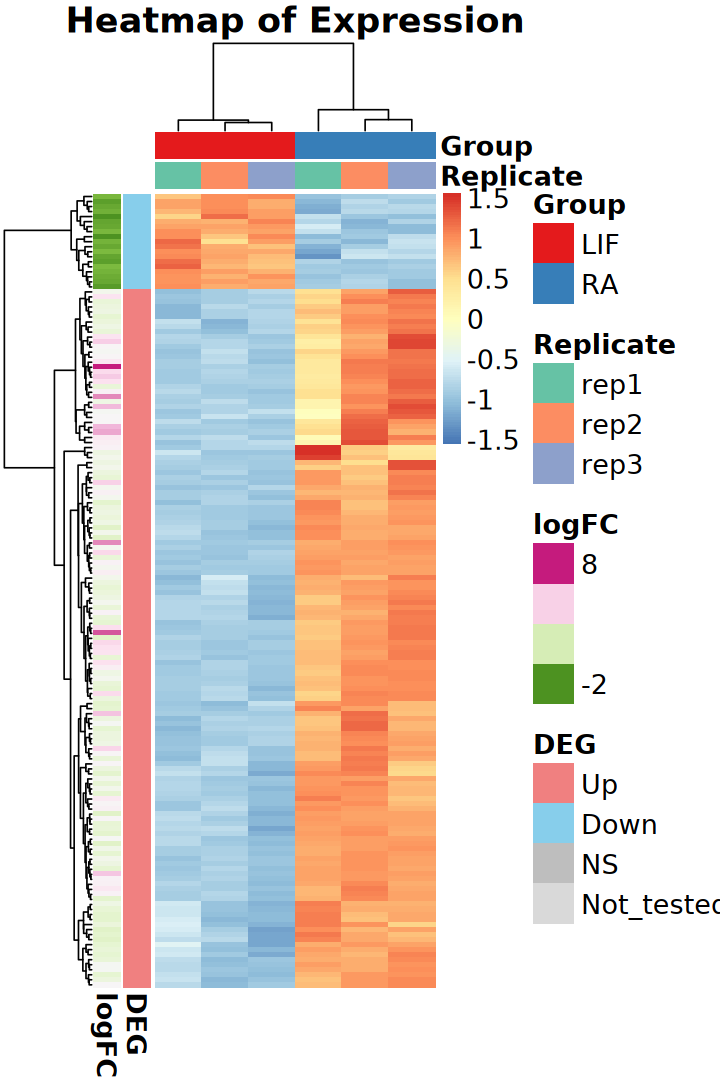

In [159]:
if (heatmap_ready) {
    options(repr.plot.width = 6, repr.plot.height = 9)

    pheatmap::pheatmap(
        heatmap_dat,
        scale = "row",
        annotation_row = ar, annotation_col = ac,
        annotation_colors = anno_colors,
        main = "Heatmap of Expression", fontsize = 16,
        show_colnames = FALSE, show_rownames = FALSE
    )
}

In [160]:
lr <- degs_result[rownames(heatmap_dat), "label"]
lr[is.na(lr)] <- ""

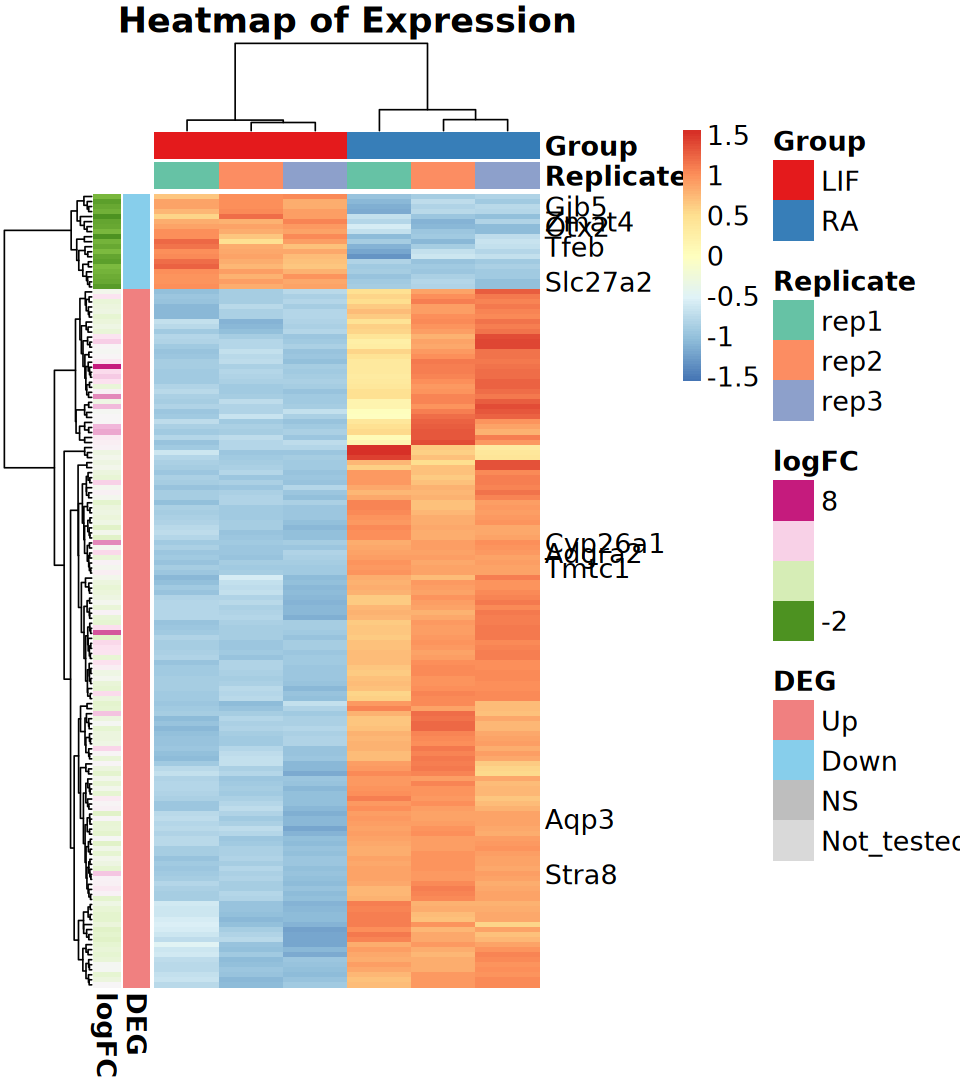

In [161]:
if (heatmap_ready) {
    options(repr.plot.width = 8, repr.plot.height = 9)

    pheatmap::pheatmap(
        heatmap_dat,
        scale = "row",
        annotation_row = ar, annotation_col = ac,
        annotation_colors = anno_colors, labels_row = lr,
        main = "Heatmap of Expression", fontsize = 16,
        show_colnames = FALSE, show_rownames = TRUE
    )
}

### ComplexHeatmap

Reuse the same expression matrix with sample annotations above the heatmap,
effect estimates and DEG classes on the left, and selected gene labels on the
right. Row z-scores summarize expression patterns across samples.

In [162]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [163]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2),
    colors = brewer.pal(n = 11, name = "RdBu")[c(11, 6, 1)]
)

In [164]:
if (heatmap_ready) {
    ac <- colData(dds) |>
        as.data.frame() |>
        dplyr::select(Group, Replicate)

    top_anno <- HeatmapAnnotation(
        df = ac, col = list(
            Group = group_colors,
            Replicate = replicate_colors
        )
    )
}

In [165]:
if (heatmap_ready) {
    ar <- degs_result |>
        dplyr::select(logFC, DEG = result) |>
        rownames_to_column("gene_id") |>
        dplyr::slice(match(rownames(heatmap_dat), gene_id)) |>
        column_to_rownames("gene_id")

    anno_colors <- list(
        DEG = deg_colors,
        logFC = circlize::colorRamp2(
            breaks = c(-5, 0, 5),
            colors = rev(brewer.pal(n = 3, name = "PiYG"))
        )
    )

    stopifnot(identical(rownames(ar), rownames(heatmap_dat)))
    left_anno <- rowAnnotation(
        df = ar, col = anno_colors, show_legend = TRUE
    )
}

In [166]:
if (heatmap_ready) {
    mark_labels <- degs_result[rownames(heatmap_dat), "label"]
    mark_at <- which(!is.na(mark_labels) & nzchar(mark_labels))
    right_anno <- if (length(mark_at)) {
        rowAnnotation(
            marker = anno_mark(
                at = mark_at, labels = mark_labels[mark_at],
                labels_gp = grid::gpar(fontsize = 12)
            )
        )
    } else {
        NULL
    }
}

In [167]:
if (heatmap_ready) {
    ht <- heatmap_dat |>
        t() |>
        scale() |>
        t() |>
        Heatmap(
            name = "rlog z-score", col = heatmap_col,
            top_annotation = top_anno,
            left_annotation = left_anno,
            right_annotation = right_anno,
            show_row_names = FALSE, show_column_names = TRUE,
            column_names_rot = 45, column_names_gp = grid::gpar(fontsize = 10)
        )
}

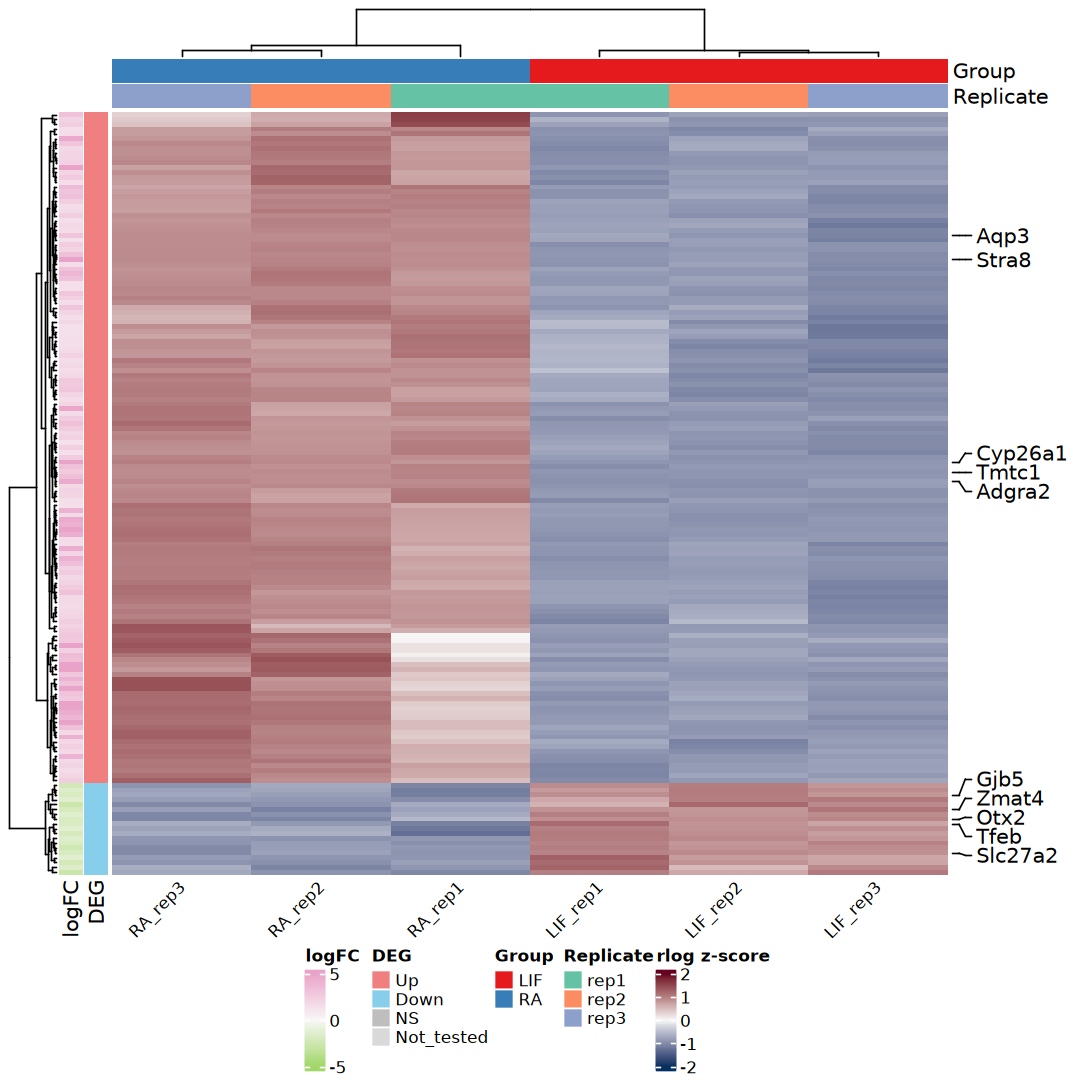

In [168]:
if (heatmap_ready) {
    options(repr.plot.width = 9, repr.plot.height = 9)
    draw(
        ht,
        merge_legend = TRUE,
        heatmap_legend_side = "bottom",
        annotation_legend_side = "bottom",
        padding = grid::unit(c(2, 2, 2, 5), "mm")
    )
}

# 6. Functional Enrichment Analysis

## 1). ORA

> Over-Representation Analysis

Map version-stripped Ensembl IDs to Entrez IDs and retain mappings with exactly
one Entrez ID per Ensembl gene. The mapping summary reports unmapped and ambiguous
IDs before enrichment.

Build separate upregulated and downregulated foregrounds for each method. Use a
shared background of mapped genes with available adjusted P values in all three
methods, and intersect every foreground with that background. GO and KEGG use
these same eligible Entrez gene sets.

In [169]:
suppressPackageStartupMessages(library(enrichplot))
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [170]:
# Keep only unambiguous Ensembl -> Entrez mappings; report losses rather than pick the first
# hit.
mapping_raw <- AnnotationDbi::select(org.Mm.eg.db,
    keys = unique(sub("[.].*$", "", rownames(dds))), keytype = "ENSEMBL",
    columns = c("SYMBOL", "ENTREZID")
)
mapping_table <- mapping_raw |>
    group_by(ENSEMBL) |>
    summarise(
        n_entrez = n_distinct(ENTREZID, na.rm = TRUE),
        ENTREZID = if (n_entrez == 1L) unique(na.omit(ENTREZID))[1] else NA_character_,
        SYMBOL = paste(sort(unique(na.omit(SYMBOL))), collapse = ";"), .groups = "drop"
    )
add_ENTREZID <- function(res) {
    idx <- match(sub("[.].*$", "", rownames(res)), mapping_table$ENSEMBL)
    res$SYMBOL <- mapping_table$SYMBOL[idx]
    res$ENTREZID <- mapping_table$ENTREZID[idx]
    res
}

table(mapping_table$n_entrez, useNA = "ifany")
message(
    "ID mapping: ", sum(mapping_table$n_entrez == 0), " unmapped; ",
    sum(mapping_table$n_entrez > 1),
    " ambiguous; ",
    sum(mapping_table$n_entrez == 1),
    " uniquely mapped."
)

'select()' returned 1:many mapping between keys and columns




    0     1     2     3     4 
 1761 14694    72     2     1 

ID mapping: 1761 unmapped; 75 ambiguous; 14694 uniquely mapped.



In [171]:
# Attach the same unambiguous ID mapping to each method before enrichment.
deseq2_result <- add_ENTREZID(deseq2_result)
edger_result <- add_ENTREZID(edger_result)
limma_result <- add_ENTREZID(limma_result)
head(deseq2_result[, c("SYMBOL", "ENTREZID", "result")])

,SYMBOL,ENTREZID,result
,<chr>,<chr>,<fct>
ENSMUSG00000024987.6,Cyp26a1,13082,Up
ENSMUSG00000029848.11,Stra8,20899,Up
ENSMUSG00000031486.15,Adgra2,78560,Up
ENSMUSG00000030306.14,Tmtc1,387314,Up
ENSMUSG00000028435.8,Aqp3,11828,Up
ENSMUSG00000079173.11,Zan,22635,Up


In [172]:
# Extract directional gene sets for each method.
extract_gene_lists <- function(
  results_map, gene_col = "SYMBOL", result_col = "result",
  directions = c("Up", "Down")
) {
    gene_lists <- lapply(results_map, function(df) {
        lapply(directions, function(direction) {
            ids <- df[[gene_col]][df[[result_col]] %in% direction]
            unique(ids[!is.na(ids) & nzchar(ids)])
        })
    })

    list_names <- outer(names(results_map), directions, paste, sep = "-")
    gene_lists |>
        unlist(recursive = FALSE) |>
        setNames(as.vector(t(list_names)))
}

In [173]:
# Named list of DEG results for compareCluster
results_map <- list(
    DESeq2 = deseq2_result,
    edgeR  = edger_result,
    limma  = limma_result
)

genes_list <- extract_gene_lists(
    results_map,
    gene_col = "ENTREZID", result_col = "result"
)

In [174]:
# Common eligible background: identical for all displayed ORA comparisons.
# Restrict foreground to the same universe; keep individual DE tables unchanged.
ora_gene_ids <- Reduce(intersect, lapply(results_map, function(x) rownames(x)[!is.na(x$padj)]))
ora_universe <- unique(na.omit(deseq2_result[ora_gene_ids, "ENTREZID"]))
genes_list <- lapply(genes_list, intersect, y = ora_universe)
stopifnot(length(ora_universe) > 0)
stopifnot(all(vapply(
    genes_list, function(x) all(x %in% ora_universe), logical(1)
)))
mapping_audit <- data.frame(
    method = names(results_map),
    input_genes = vapply(results_map, nrow, integer(1)),
    mapped_genes = vapply(results_map, function(x) sum(!is.na(x$ENTREZID)), integer(1))
)
mapping_audit

,method,input_genes,mapped_genes
,<chr>,<int>,<int>
DESeq2,DESeq2,16530,14694
edgeR,edgeR,16530,14694
limma,limma,16530,14694


In [175]:
# ---- GO over-representation analysis (compareCluster) ----
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO,
    universe = ora_universe,
    OrgDb = org.Mm.eg.db, ont = "ALL",
    keyType = "ENTREZID", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05,
    minGSSize = 10, maxGSSize = 500, readable = TRUE
)

In [176]:
ego_compare |>
    dplyr::select(-any_of("geneID")) |>
    head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,BP,GO:0048705,skeletal system morphogenesis,14/122,203/13442,0.06896552,7.598643,9.066062,4.186104e-09,7.924295e-06,7.332292e-06,14
2,DESeq2-Up,BP,GO:0007389,pattern specification process,16/122,386/13442,0.04145078,4.567060,6.805227,4.017267e-07,2.964410e-04,2.742947e-04,16
3,DESeq2-Up,BP,GO:0009952,anterior/posterior pattern specification,11/122,176/13442,0.06250000,6.886270,7.522638,5.655920e-07,2.964410e-04,2.742947e-04,11
4,DESeq2-Up,BP,GO:0003002,regionalization,15/122,350/13442,0.04285714,4.722014,6.752314,6.263941e-07,2.964410e-04,2.742947e-04,15
5,DESeq2-Up,BP,GO:0060430,lung saccule development,4/122,12/13442,0.33333333,36.726776,11.849227,3.022345e-06,1.144260e-03,1.058775e-03,4
6,DESeq2-Up,BP,GO:0048704,embryonic skeletal system morphogenesis,7/122,77/13442,0.09090909,10.016393,7.593418,6.064855e-06,1.913462e-03,1.770512e-03,7


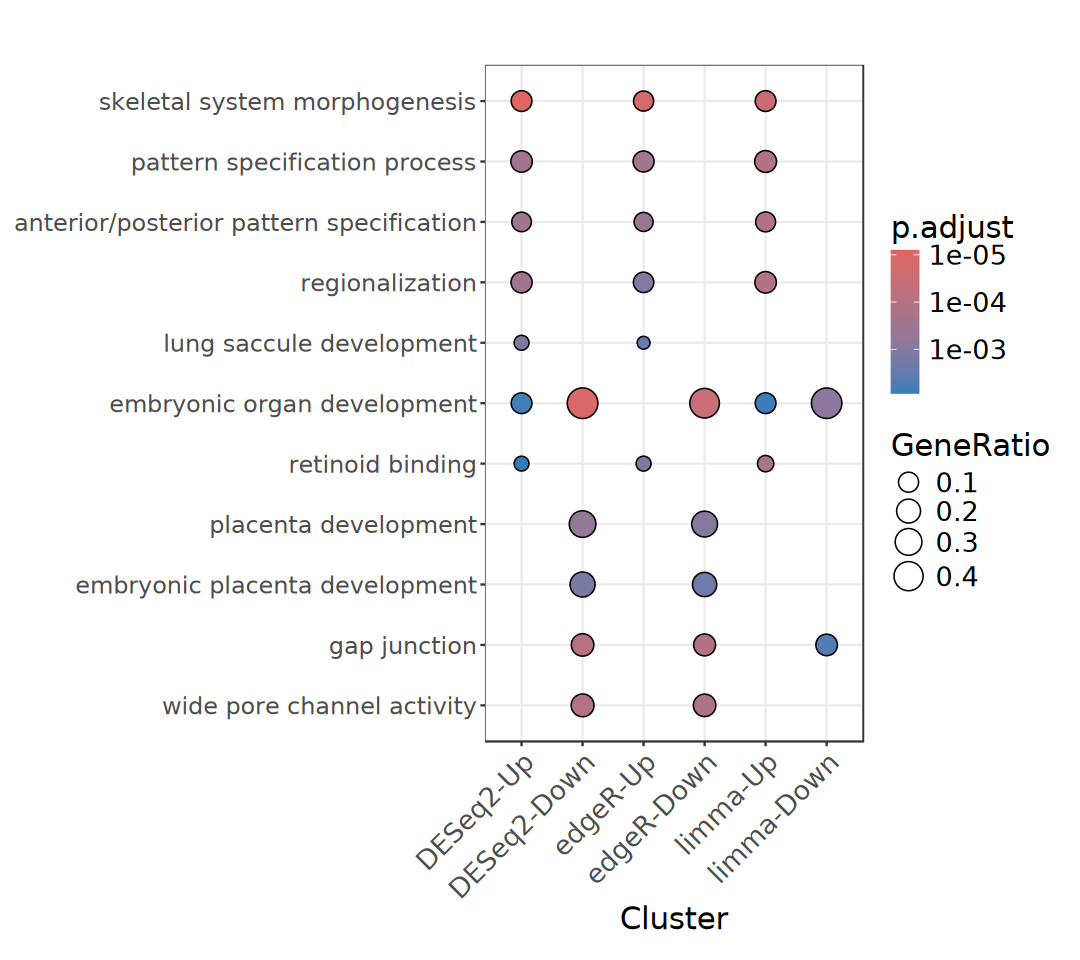

In [177]:
if (!is.null(ego_compare) && nrow(as.data.frame(ego_compare)) > 0) {
    options(repr.plot.width = 9, repr.plot.height = 8)

    dotplot(ego_compare, showCategory = 5, label_format = 50) +
        theme_bw() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text.x = element_text(size = 16, angle = 45, hjust = 1),
            axis.text.y = element_text(size = 14)
        )
} else {
    message("No significant terms: ego_compare")
}

In [178]:
# KEGG uses the same cleaned Entrez foreground and common eligible universe.
genes_list <- extract_gene_lists(results_map, gene_col = "ENTREZID") |>
    lapply(intersect, y = ora_universe)

In [179]:
# ---- KEGG pathway over-representation analysis ----
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG,
    universe = ora_universe,
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05,
    minGSSize = 10, maxGSSize = 500
)

In [180]:
ekegg_compare |>
    dplyr::select(-any_of("geneID")) |>
    head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,Metabolism,Metabolism of cofactors and vitamins,mmu00830,Retinol metabolism,4/50,25/6101,0.16,19.52320,8.435551,4.449088e-05,0.005828305,0.005760398,4
2,limma-Up,Metabolism,Metabolism of cofactors and vitamins,mmu00830,Retinol metabolism,4/47,25/6101,0.16,20.76936,8.726627,3.474439e-05,0.004621004,0.004571630,4


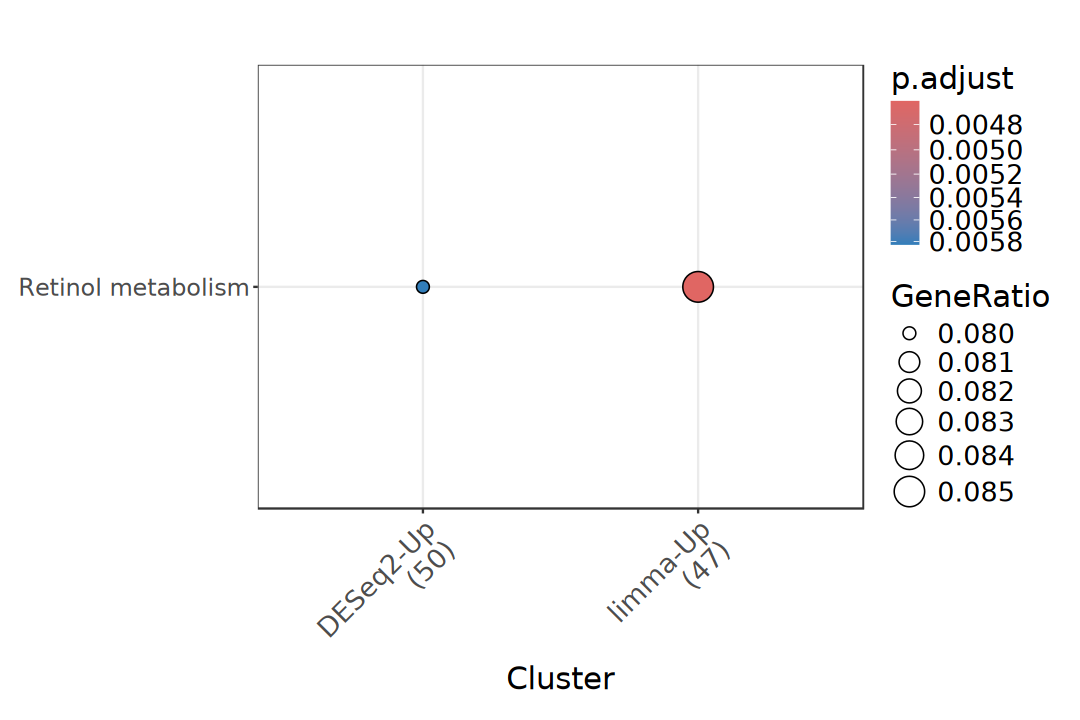

In [181]:
if (!is.null(ekegg_compare) && nrow(as.data.frame(ekegg_compare)) > 0) {
    options(repr.plot.width = 9, repr.plot.height = 6)

    dotplot(ekegg_compare, showCategory = 5, label_format = 50) +
        theme_bw() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text.x = element_text(size = 16, angle = 45, hjust = 1),
            axis.text.y = element_text(size = 14)
        )
} else {
    message("No significant terms: ekegg_compare")
}

## 2). GSEA

> Gene Set Enrichment Analysis

Rank all mapped genes with a finite ordinary DESeq2 Wald statistic, without
restricting the list to DEGs. When multiple Ensembl genes map to one Entrez ID,
retain the gene with the largest `baseMean`, using the gene ID to break ties.

The descending ranking places RA-associated positive statistics first and
LIF-associated negative statistics last. GO and KEGG enrichment use this ranking;
the following sensitivity analysis uses shrunken effects on the same genes.

In [182]:
# Full tested ranking; do not filter by DEG status or adjusted P value.
# Resolve many Ensembl genes -> one Entrez by largest baseMean, independent of effect direction.
rank_input <- deseq2_result |>
    rownames_to_column("gene_id") |>
    filter(!is.na(ENTREZID), nzchar(ENTREZID), is.finite(stat_zero)) |>
    arrange(desc(baseMean), gene_id) |>
    distinct(ENTREZID, .keep_all = TRUE)
ranked_genes <- setNames(rank_input$stat_zero, rank_input$ENTREZID) |> sort(decreasing = TRUE)
shrink_idx <- match(rank_input$gene_id, rownames(deseq2_lfc_result))
ranked_lfc <- setNames(deseq2_lfc_result$logFC_shrunk[shrink_idx], rank_input$ENTREZID) |>
    sort(decreasing = TRUE)
stopifnot(!anyDuplicated(names(ranked_genes)), all(is.finite(ranked_genes)))

In [183]:
# Run GO biological-process GSEA on the full Wald-statistic ranking.
set.seed(analysis_seed)
gsea_go <- gseGO(
    geneList = ranked_genes, OrgDb = org.Mm.eg.db,
    ont = "BP", keyType = "ENTREZID", pvalueCutoff = p_cutoff,
    minGSSize = 10, maxGSSize = 500, eps = 0, seed = TRUE,
    nPermSimple = 10000, verbose = FALSE, BPPARAM = BiocParallel::SerialParam()
)

gsea_go |>
    as.data.frame() |>
    dplyr::select(-any_of("core_enrichment")) |>
    head()

,ID,Description,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalue,rank,leading_edge
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
GO:1990823,GO:1990823,response to leukemia inhibitory factor,130,-0.4903447,-1.911191,5.331233e-06,0.01515136,0.01422036,1176,"tags=29%, list=8%, signal=27%"
GO:1990830,GO:1990830,cellular response to leukemia inhibitory factor,128,-0.4878077,-1.899258,3.344139e-06,0.01515136,0.01422036,1176,"tags=29%, list=8%, signal=27%"
GO:0050673,GO:0050673,epithelial cell proliferation,374,-0.3557077,-1.562346,9.970576e-06,0.01889092,0.01773013,2000,"tags=27%, list=14%, signal=24%"
GO:0050678,GO:0050678,regulation of epithelial cell proliferation,313,-0.3733885,-1.610020,1.468104e-05,0.02086176,0.01957987,2000,"tags=27%, list=14%, signal=24%"
GO:0046426,GO:0046426,negative regulation of receptor signaling pathway via JAK-STAT,18,-0.8062012,-2.093733,2.374241e-05,0.02699037,0.02533190,1774,"tags=56%, list=12%, signal=49%"
GO:1904893,GO:1904893,negative regulation of receptor signaling pathway via STAT,20,-0.7861822,-2.104323,3.606572e-05,0.03373402,0.03166118,1774,"tags=50%, list=12%, signal=44%"


In [184]:
# Reuse the Wald-statistic ranking for mouse KEGG pathways.
set.seed(analysis_seed)
gsea_kegg <- gseKEGG(
    geneList = ranked_genes, organism = "mmu",
    pvalueCutoff = p_cutoff, minGSSize = 10, maxGSSize = 500,
    eps = 0, seed = TRUE, nPermSimple = 10000, verbose = FALSE,
    BPPARAM = BiocParallel::SerialParam()
)

gsea_kegg |>
    as.data.frame() |>
    dplyr::select(-any_of("core_enrichment")) |>
    head()

no term enriched under specific pvalueCutoff...



ID,Description,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalue
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>


### Ranking sensitivity

Repeat GO enrichment using shrunken log2 fold changes to rank the same genes.
Compare this result with the Wald-statistic ranking to assess how the choice of
ranking metric affects the enriched terms.

In [185]:
# Change only the ranking metric for the GO sensitivity comparison.
set.seed(analysis_seed)
gsea_go_lfc <- gseGO(
    geneList = ranked_lfc, OrgDb = org.Mm.eg.db,
    ont = "BP", keyType = "ENTREZID", pvalueCutoff = p_cutoff,
    minGSSize = 10, maxGSSize = 500, eps = 0, seed = TRUE,
    nPermSimple = 10000, verbose = FALSE, BPPARAM = BiocParallel::SerialParam()
)

gsea_go_lfc |>
    as.data.frame() |>
    dplyr::select(-any_of("core_enrichment")) |>
    head()

,ID,Description,setSize,enrichmentScore,NES,pvalue,p.adjust,qvalue,rank,leading_edge
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
GO:0001501,GO:0001501,skeletal system development,438,0.6024542,1.674897,1.175747e-07,0.0006682949,0.0006580473,910,"tags=15%, list=6%, signal=15%"
GO:0048705,GO:0048705,skeletal system morphogenesis,203,0.6848322,1.836028,5.941255e-07,0.0013384883,0.0013179640,779,"tags=16%, list=5%, signal=16%"
GO:0007389,GO:0007389,pattern specification process,386,0.6044119,1.674233,7.064505e-07,0.0013384883,0.0013179640,1076,"tags=17%, list=7%, signal=16%"
GO:0003002,GO:0003002,regionalization,350,0.6163463,1.700739,1.306240e-06,0.0018561665,0.0018277042,1076,"tags=17%, list=7%, signal=16%"
GO:0009952,GO:0009952,anterior/posterior pattern specification,176,0.6663069,1.769812,7.858906e-06,0.0089340039,0.0087970107,480,"tags=14%, list=3%, signal=13%"
GO:0009593,GO:0009593,detection of chemical stimulus,39,-0.7246393,-1.981964,3.333955e-05,0.0292243748,0.0287762512,1851,"tags=44%, list=13%, signal=38%"


# A tibble: 2 × 5
  ID         Description                            direction      NES p.adjust
  <chr>      <chr>                                  <chr>        <dbl>    <dbl>
1 GO:1990823 response to leukemia inhibitory factor LIF enriched -1.91   0.0152
2 GO:0060349 bone morphogenesis                     RA enriched   1.85   0.0337


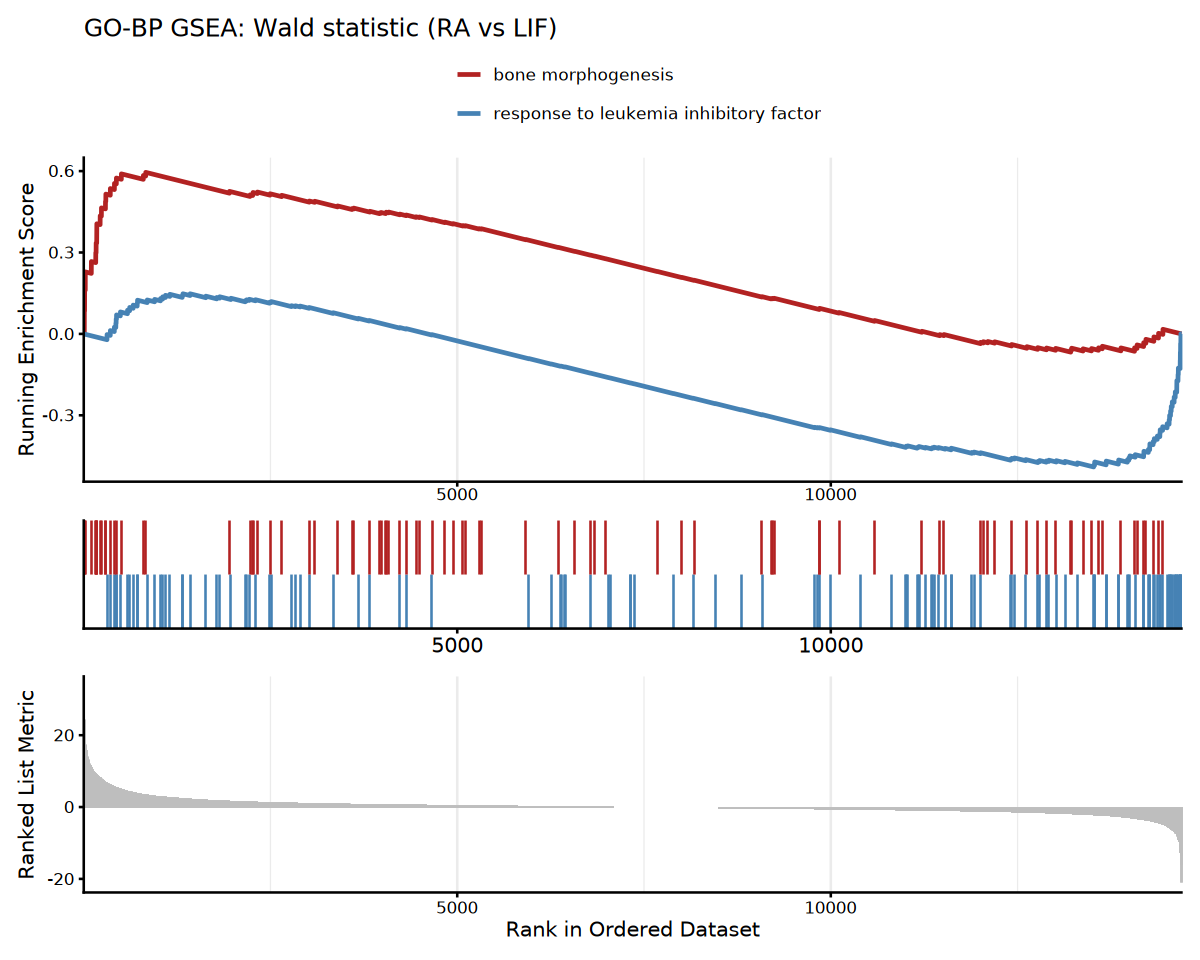

In [186]:
gsea_table <- as.data.frame(gsea_go)
if (nrow(gsea_table)) {
    top_terms <- gsea_table |>
        mutate(direction = if_else(NES > 0,
            "RA enriched",
            "LIF enriched"
        )) |>
        group_by(direction) |>
        slice_min(p.adjust, n = 1, with_ties = FALSE) |>
        ungroup()
    # Named colors follow pathway descriptions, not the plotting package's internal sort order.
    term_colors <- setNames(
        ifelse(top_terms$NES > 0,
            "firebrick",
            "steelblue"
        ),
        top_terms$Description
    )
    gsea_panels <- lapply(1:3, function(panel) {
        gseaplot2(gsea_go,
            geneSetID = top_terms$ID, color = term_colors, subplots = panel,
            pvalue_table = FALSE, ES_geom = "line", base_size = 12
        )
    })
    gsea_panels[[1]] <- gsea_panels[[1]] +
        labs(title = "GO-BP GSEA: Wald statistic (RA vs LIF)") +
        theme(legend.position = "top", legend.text = element_text(size = 10)) +
        guides(color = guide_legend(ncol = 1))
    gsea_plot <- patchwork::wrap_plots(gsea_panels, ncol = 1, heights = c(1.5, 0.5, 1))
    options(repr.plot.width = 10, repr.plot.height = 8)
    print(gsea_plot)
    # A separate table avoids clipped text inside the enrichment panel.
    print(dplyr::select(top_terms, ID, Description, direction, NES, p.adjust))
} else {
    message("No GO-BP terms passed the configured GSEA cutoff.")
}

# 7. Selected Gene Expression

Display normalized expression for selected RA-response and pluripotency markers,
with one point per biological replicate. These plots connect the experimental
context with the differential-expression results; marker selection does not
replace statistical testing.

In [187]:
# Retrieve each selected marker while retaining all sample-level expression values.
marker_symbols <- c("Cyp26a1", "Rarb", "Stra8", "Hoxa1", "Pou5f1", "Nanog", "Sox2", "Esrrb")
marker_ids <- rownames(dds)[rowData(dds)$symbol %in% marker_symbols]
marker_df <- as.data.frame(norm_count[marker_ids, , drop = FALSE]) |>
    rownames_to_column("gene_id") |>
    pivot_longer(-gene_id, names_to = "sample", values_to = "normalized_count") |>
    mutate(
        symbol = rowData(dds)$symbol[match(gene_id, rownames(dds))],
        Group = coldata[sample, "Group"]
    )

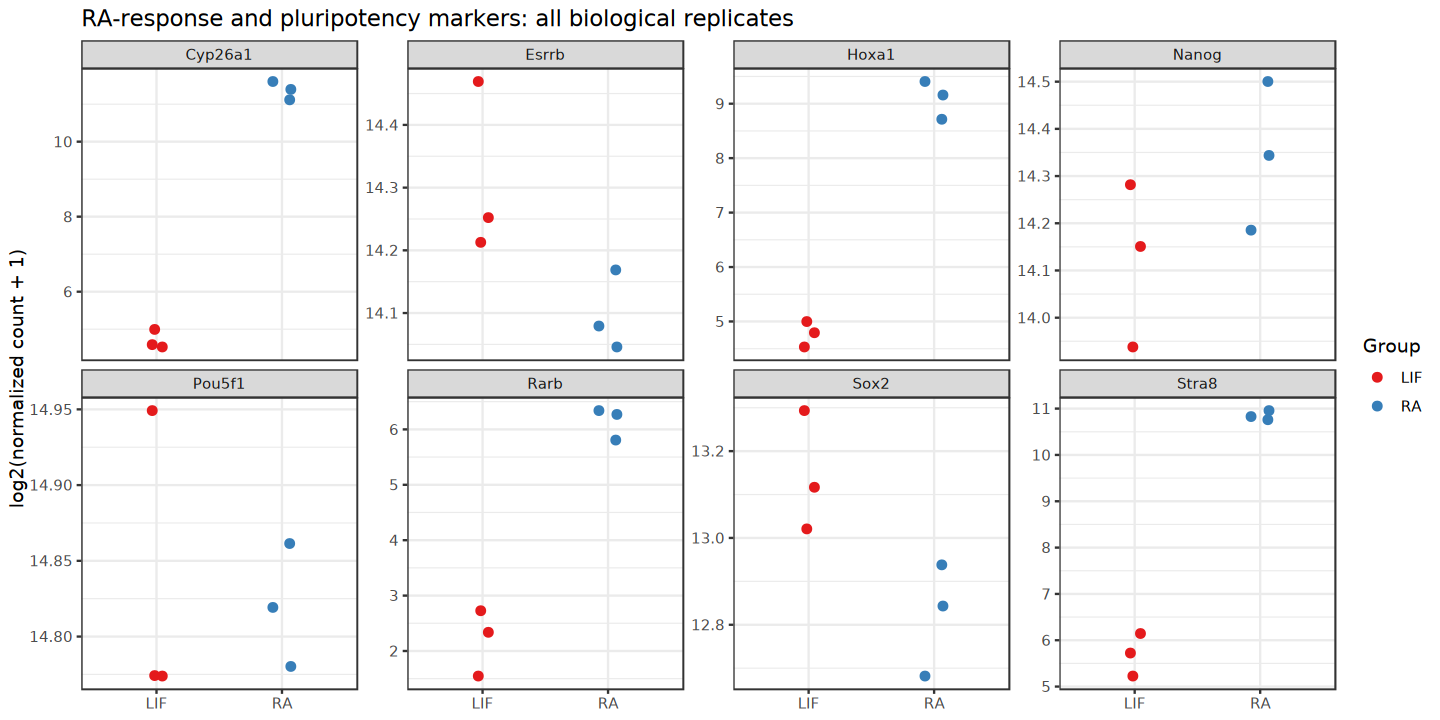

In [188]:
marker_plot <- ggplot(marker_df, aes(Group, log2(normalized_count + 1), color = Group)) +
    geom_point(position = position_jitter(width = 0.08, seed = analysis_seed), size = 2) +
    facet_wrap(~symbol, scales = "free_y", ncol = 4) +
    theme_bw() +
    scale_color_brewer(palette = "Set1") +
    labs(
        y = "log2(normalized count + 1)", x = NULL,
        title = "RA-response and pluripotency markers: all biological replicates"
    )
options(repr.plot.width = 12, repr.plot.height = 6)
print(marker_plot)

# 8. Session Information

Display the R version and loaded package versions used for this notebook session.
Keep this output with the figures and tables when reviewing or rerunning the analysis.

In [189]:
# Record the environment alongside the inline analysis outputs.
sessionInfo()

R version 4.5.2 (2025-10-31)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 24.04.4 LTS

Matrix products: default
BLAS/LAPACK: /home/fugui/miniconda3/envs/r452/lib/libopenblasp-r0.3.32.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: Asia/Shanghai
tzcode source: system (glibc)

attached base packages:
[1] grid      stats4    stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] clusterProfiler_4.18.4      org.Mm.eg.db_3.22.0        
 [3] enrichplot_1.30.5           ComplexHeatmap_2.26.1      
 [5] UpSetR_1.4.1                ggVennDiagram_1.5.7        
 [7] introdataviz_0.0.0.9003     vsn_3.78.1                 
 [9] GenomicFeatures_1.62.

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 3. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 4. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)